In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#======================================
#           Column names
#======================================
columns = [
    "engine_id",
    "cycle",
    "operational_setting_1",
    "operational_setting_2",
    "operational_setting_3"
]

columns += [f"sensor_{i}" for i in range(1, 22)]

print(columns)
print("Total columns:", len(columns))

['engine_id', 'cycle', 'operational_setting_1', 'operational_setting_2', 'operational_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
Total columns: 26


In [3]:
#=============================
#     Load Data
#=============================

train_fd002 = pd.read_csv(
    r"D:\IST\Aircraft_Engine_RUL\data\raw\train_FD002.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test_fd002 = pd.read_csv(
    r"D:\IST\Aircraft_Engine_RUL\data\raw\test_FD002.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_fd002 = pd.read_csv(
    r"D:\IST\Aircraft_Engine_RUL\data\raw\RUL_FD002.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

In [4]:
print("FD002 Train Shape:", train_fd002.shape)
print("FD002 Test Shape :", test_fd002.shape)
print("FD002 RUL Shape  :", rul_fd002.shape)

FD002 Train Shape: (53759, 26)
FD002 Test Shape : (33991, 26)
FD002 RUL Shape  : (259, 1)


In [5]:
#========================================
#               Load FD003
#========================================
train_fd003 = pd.read_csv(
    r"D:\IST\Aircraft_Engine_RUL\data\raw\train_FD003.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test_fd003 = pd.read_csv(
    r"D:\IST\Aircraft_Engine_RUL\data\raw\test_FD003.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_fd003 = pd.read_csv(
    r"D:\IST\Aircraft_Engine_RUL\data\raw\RUL_FD003.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

In [6]:
print("FD003 Train Shape:", train_fd003.shape)
print("FD003 Test Shape :", test_fd003.shape)
print("FD003 RUL Shape  :", rul_fd003.shape)

FD003 Train Shape: (24720, 26)
FD003 Test Shape : (16596, 26)
FD003 RUL Shape  : (100, 1)


In [7]:
train_fd002.head()

,engine_id,cycle,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286


In [8]:
rul_fd003.tail()

,RUL
95,113
96,123
97,17
98,8
99,28


In [9]:
train_fd002.info()
train_fd003.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53759 entries, 0 to 53758
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   engine_id              53759 non-null  int64  
 1   cycle                  53759 non-null  int64  
 2   operational_setting_1  53759 non-null  float64
 3   operational_setting_2  53759 non-null  float64
 4   operational_setting_3  53759 non-null  float64
 5   sensor_1               53759 non-null  float64
 6   sensor_2               53759 non-null  float64
 7   sensor_3               53759 non-null  float64
 8   sensor_4               53759 non-null  float64
 9   sensor_5               53759 non-null  float64
 10  sensor_6               53759 non-null  float64
 11  sensor_7               53759 non-null  float64
 12  sensor_8               53759 non-null  float64
 13  sensor_9               53759 non-null  float64
 14  sensor_10              53759 non-null  float64
 15  se

In [10]:
#============================
#      Number of Engines
#============================
print("FD002 Training Engines:", train_fd002["engine_id"].nunique())
print("FD002 Testing Engines :", test_fd002["engine_id"].nunique())

print()

print("FD003 Training Engines:", train_fd003["engine_id"].nunique())
print("FD003 Testing Engines :", test_fd003["engine_id"].nunique())

FD002 Training Engines: 260
FD002 Testing Engines : 259

FD003 Training Engines: 100
FD003 Testing Engines : 100


In [11]:
train_fd002[train_fd002["engine_id"] == 1].head(10)

,engine_id,cycle,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286
5,1,6,25.0045,0.6205,60.0,462.54,537.02,1266.38,1048.72,7.05,...,164.27,2028.01,7868.87,10.8912,0.02,306,1915,84.93,14.28,8.5590
6,1,7,42.0043,0.8409,100.0,445.00,549.74,1347.45,1127.19,3.91,...,130.49,2387.69,8075.54,9.3753,0.02,330,2212,100.00,10.62,6.4227
7,1,8,20.0020,0.7002,100.0,491.19,607.44,1481.69,1252.36,9.35,...,315.11,2387.99,8049.26,9.2369,0.02,365,2324,100.00,24.33,14.7989
8,1,9,41.9995,0.8407,100.0,445.00,549.33,1348.23,1127.45,3.91,...,130.97,2387.62,8065.78,9.3878,0.02,331,2212,100.00,10.69,6.3802
9,1,10,42.0011,0.8400,100.0,445.00,549.33,1356.40,1127.11,3.91,...,130.50,2387.62,8069.11,9.3957,0.02,329,2212,100.00,10.57,6.2847


In [12]:
train_fd003.describe().T

,count,mean,std,min,25%,50%,75%,max
engine_id,24720.0,48.631877,2.934899e+01,1.0000,23.0000,47.0000,74.0000,100.0000
cycle,24720.0,139.077063,9.884668e+01,1.0000,62.0000,124.0000,191.0000,525.0000
operational_setting_1,24720.0,-0.000024,2.193545e-03,-0.0086,-0.0015,-0.0000,0.0015,0.0086
operational_setting_2,24720.0,0.000005,2.940429e-04,-0.0006,-0.0002,-0.0000,0.0003,0.0007
operational_setting_3,24720.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,24720.0,518.670000,6.684921e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,24720.0,642.457858,5.230311e-01,640.8400,642.0800,642.4000,642.7900,645.1100
sensor_3,24720.0,1588.079175,6.810418e+00,1564.3000,1583.2800,1587.5200,1592.4125,1615.3900
sensor_4,24720.0,1404.471212,9.773178e+00,1377.0600,1397.1875,1402.9100,1410.6000,1441.1600
sensor_5,24720.0,14.620000,3.602525e-12,14.6200,14.6200,14.6200,14.6200,14.6200


In [13]:
train_fd002.describe().T

,count,mean,std,min,25%,50%,75%,max
engine_id,53759.0,131.082981,74.463862,1.0000,68.0000,131.0000,195.0000,260.0000
cycle,53759.0,109.154746,69.180569,1.0000,52.0000,104.0000,157.0000,378.0000
operational_setting_1,53759.0,23.998407,14.747376,0.0000,10.0046,25.0013,41.9980,42.0080
operational_setting_2,53759.0,0.572056,0.310016,0.0000,0.2507,0.7000,0.8400,0.8420
operational_setting_3,53759.0,94.046020,14.237735,60.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,53759.0,472.910207,26.389707,445.0000,445.0000,462.5400,491.1900,518.6700
sensor_2,53759.0,579.672399,37.289399,535.5300,549.5700,555.9800,607.3400,644.5200
sensor_3,53759.0,1419.971013,105.946341,1243.7300,1352.7600,1369.1800,1499.3700,1612.8800
sensor_4,53759.0,1205.442024,119.123428,1023.7700,1123.6550,1138.8900,1306.8500,1439.2300
sensor_5,53759.0,8.031986,3.613839,3.9100,3.9100,7.0500,10.5200,14.6200


In [14]:
fd002_engine_life = (
    train_fd002
    .groupby("engine_id")["cycle"]
    .max()
)

fd002_engine_life.head(10)

engine_id
1     149
2     269
3     206
4     235
5     154
6     175
7     174
8     151
9     199
10    184
Name: cycle, dtype: int64

In [15]:
fd003_engine_life = (
    train_fd003
    .groupby("engine_id")["cycle"]
    .max()
)

fd003_engine_life.head(10)

engine_id
1     259
2     253
3     222
4     272
5     213
6     278
7     424
8     267
9     406
10    481
Name: cycle, dtype: int64

In [16]:
print("FD002 Engine Life")
print("Minimum Life :", fd002_engine_life.min())
print("Maximum Life :", fd002_engine_life.max())
print("Average Life :", fd002_engine_life.mean())

print()

print("FD003 Engine Life")
print("Minimum Life :", fd003_engine_life.min())
print("Maximum Life :", fd003_engine_life.max())
print("Average Life :", fd003_engine_life.mean())

FD002 Engine Life
Minimum Life : 128
Maximum Life : 378
Average Life : 206.76538461538462

FD003 Engine Life
Minimum Life : 145
Maximum Life : 525
Average Life : 247.2


In [17]:
engine_1_fd002 = train_fd002[
    train_fd002["engine_id"] == 1
]

engine_1_fd002.tail(10)

,engine_id,cycle,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
139,1,140,35.0069,0.8406,100.0,449.44,556.36,1376.07,1139.35,5.48,...,182.95,2387.70,8048.75,9.3970,0.02,338,2223,100.00,14.68,8.7953
140,1,141,34.9991,0.8410,100.0,449.44,556.33,1375.95,1144.21,5.48,...,182.67,2387.76,8054.28,9.4441,0.02,339,2223,100.00,14.61,8.9616
141,1,142,20.0025,0.7000,100.0,491.19,608.28,1497.31,1270.91,9.35,...,314.28,2388.15,8049.86,9.2781,0.03,367,2324,100.00,24.13,14.6524
142,1,143,35.0014,0.8400,100.0,449.44,556.56,1374.08,1145.42,5.48,...,182.57,2387.71,8052.68,9.4254,0.02,335,2223,100.00,14.71,8.9133
143,1,144,0.0017,0.0018,100.0,518.67,643.02,1601.91,1429.43,14.62,...,520.24,2388.32,8120.19,8.5092,0.03,395,2388,100.00,38.27,23.1236
144,1,145,35.0007,0.8402,100.0,449.44,556.59,1376.19,1152.04,5.48,...,182.61,2387.77,8050.29,9.4189,0.02,338,2223,100.00,14.72,8.8240
145,1,146,10.0006,0.2516,100.0,489.05,605.94,1511.92,1326.50,10.52,...,370.52,2388.43,8113.02,8.7345,0.03,372,2319,100.00,28.16,16.9984
146,1,147,25.0005,0.6200,60.0,462.54,537.50,1268.62,1057.88,7.05,...,164.56,2027.97,7866.66,10.9764,0.02,310,1915,84.93,14.34,8.4476
147,1,148,0.0024,0.0013,100.0,518.67,643.73,1605.33,1425.76,14.62,...,519.76,2388.31,8115.88,8.5240,0.03,397,2388,100.00,38.55,23.0079
148,1,149,42.0017,0.8414,100.0,445.00,550.49,1366.01,1149.81,3.91,...,129.55,2387.40,8066.19,9.4765,0.02,332,2212,100.00,10.45,6.2285


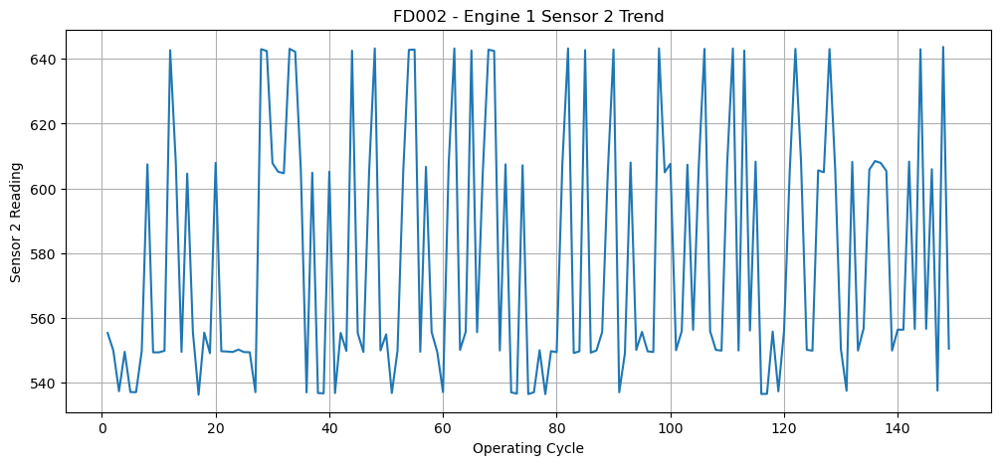

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    engine_1_fd002["cycle"],
    engine_1_fd002["sensor_2"]
)

plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2 Reading")
plt.title("FD002 - Engine 1 Sensor 2 Trend")
plt.grid()
plt.show()

In [19]:
print("FD002 Missing Values:")
print(train_fd002.isnull().sum().sum())

print("FD003 Missing Values:")
print(train_fd003.isnull().sum().sum())

FD002 Missing Values:
0
FD003 Missing Values:
0


In [20]:
print("FD002 Duplicate Rows:", train_fd002.duplicated().sum())
print("FD003 Duplicate Rows:", train_fd003.duplicated().sum())

FD002 Duplicate Rows: 0
FD003 Duplicate Rows: 0


In [21]:
print("FD002 Invalid Engine IDs:",
      (train_fd002["engine_id"] <= 0).sum())

print("FD002 Invalid Cycles:",
      (train_fd002["cycle"] <= 0).sum())

print("FD003 Invalid Engine IDs:",
      (train_fd003["engine_id"] <= 0).sum())

print("FD003 Invalid Cycles:",
      (train_fd003["cycle"] <= 0).sum())

FD002 Invalid Engine IDs: 0
FD002 Invalid Cycles: 0
FD003 Invalid Engine IDs: 0
FD003 Invalid Cycles: 0


In [22]:
fd002_unique_values = train_fd002.nunique().sort_values()
fd002_unique_values

operational_setting_3        2
sensor_19                    2
sensor_16                    2
sensor_1                     6
sensor_18                    6
sensor_5                     6
sensor_10                    9
sensor_6                    14
sensor_17                   53
operational_setting_2      105
engine_id                  260
cycle                      378
sensor_20                  510
sensor_13                  514
operational_setting_1      536
sensor_11                  681
sensor_8                   897
sensor_2                  1590
sensor_12                 1672
sensor_7                  2067
sensor_15                 8464
sensor_3                 12305
sensor_14                14905
sensor_4                 15411
sensor_21                17837
sensor_9                 22434
dtype: int64

In [23]:
fd003_unique_values = train_fd003.nunique().sort_values()
fd003_unique_values

sensor_19                   1
operational_setting_3       1
sensor_1                    1
sensor_18                   1
sensor_16                   1
sensor_5                    1
sensor_10                   4
sensor_17                  12
operational_setting_2      14
sensor_6                   17
engine_id                 100
operational_setting_1     160
sensor_8                  161
sensor_13                 163
sensor_20                 165
sensor_11                 170
sensor_2                  334
cycle                     525
sensor_12                1772
sensor_7                 1854
sensor_15                3122
sensor_3                 3358
sensor_4                 4383
sensor_14                6320
sensor_21                6440
sensor_9                 7114
dtype: int64

In [24]:
fd002_constant_cols = [
    col for col in train_fd002.columns
    if train_fd002[col].nunique() == 1
]

fd003_constant_cols = [
    col for col in train_fd003.columns
    if train_fd003[col].nunique() == 1
]

print("FD002 Constant Columns:", fd002_constant_cols)
print("FD003 Constant Columns:", fd003_constant_cols)

FD002 Constant Columns: []
FD003 Constant Columns: ['operational_setting_3', 'sensor_1', 'sensor_5', 'sensor_16', 'sensor_18', 'sensor_19']


In [25]:
fd002_max_cycle = (
    train_fd002.groupby("engine_id")["cycle"]
    .max()
    .reset_index()
)

fd002_max_cycle.columns = ["engine_id", "max_cycle"]

In [26]:
train_fd002 = train_fd002.merge(
    fd002_max_cycle,
    on="engine_id",
    how="left"
)

In [27]:
train_fd002["RUL"] = (
    train_fd002["max_cycle"] - train_fd002["cycle"]
)

In [28]:
train_fd002.head()

,engine_id,cycle,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,149,148
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,149,147
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,149,146
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701,149,145
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286,149,144


In [29]:
#============================================
#          RUL Calculation for FD003
#============================================
fd003_max_cycle = (
    train_fd003.groupby("engine_id")["cycle"]
    .max()
    .reset_index()
)

fd003_max_cycle.columns = ["engine_id", "max_cycle"]

train_fd003 = train_fd003.merge(
    fd003_max_cycle,
    on="engine_id",
    how="left"
)

train_fd003["RUL"] = (
    train_fd003["max_cycle"] - train_fd003["cycle"]
)

In [30]:
train_fd003.tail()

,engine_id,cycle,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL
24715,100,148,-0.0016,-0.0003,100.0,518.67,643.78,1596.01,1424.11,14.62,...,8138.08,8.5036,0.03,394,2388,100.0,38.44,22.9631,152,4
24716,100,149,0.0034,-0.0003,100.0,518.67,643.29,1596.38,1429.14,14.62,...,8144.36,8.5174,0.03,395,2388,100.0,38.50,22.9746,152,3
24717,100,150,-0.0016,0.0004,100.0,518.67,643.84,1604.53,1431.41,14.62,...,8135.95,8.5223,0.03,396,2388,100.0,38.39,23.0682,152,2
24718,100,151,-0.0023,0.0004,100.0,518.67,643.94,1597.56,1426.57,14.62,...,8141.24,8.5148,0.03,395,2388,100.0,38.31,23.0753,152,1
24719,100,152,0.0000,0.0003,100.0,518.67,643.64,1599.04,1436.06,14.62,...,8136.98,8.5150,0.03,396,2388,100.0,38.56,23.0847,152,0


In [31]:
#=======================================
#              Validation
#========================================
print(
    "FD002 Negative RUL:",
    (train_fd002["RUL"] < 0).sum()
)

print(
    "FD003 Negative RUL:",
    (train_fd003["RUL"] < 0).sum()
)

FD002 Negative RUL: 0
FD003 Negative RUL: 0


In [32]:
print(
    "FD002 Final RUL values:",
    train_fd002.groupby("engine_id")["RUL"].last().unique()
)

print(
    "FD003 Final RUL values:",
    train_fd003.groupby("engine_id")["RUL"].last().unique()
)

FD002 Final RUL values: [0]
FD003 Final RUL values: [0]


In [33]:
train_fd002.rename(
    columns={"RUL": "RUL_original"},
    inplace=True
)

train_fd003.rename(
    columns={"RUL": "RUL_original"},
    inplace=True
)

In [34]:
RUL_CAP = 125

train_fd002["RUL_capped"] = (
    train_fd002["RUL_original"]
    .clip(upper=RUL_CAP)
)

train_fd003["RUL_capped"] = (
    train_fd003["RUL_original"]
    .clip(upper=RUL_CAP)
)

In [35]:
display(
    train_fd002[
        [
            "engine_id",
            "cycle",
            "RUL_original",
            "RUL_capped"
        ]
    ].head(30)
)

display(
    train_fd002[
        train_fd002["engine_id"] == 1
    ][
        [
            "cycle",
            "RUL_original",
            "RUL_capped"
        ]
    ].tail(15)
)

,engine_id,cycle,RUL_original,RUL_capped
0,1,1,148,125
1,1,2,147,125
2,1,3,146,125
3,1,4,145,125
4,1,5,144,125
5,1,6,143,125
6,1,7,142,125
7,1,8,141,125
8,1,9,140,125
9,1,10,139,125


,cycle,RUL_original,RUL_capped
134,135,14,14
135,136,13,13
136,137,12,12
137,138,11,11
138,139,10,10
139,140,9,9
140,141,8,8
141,142,7,7
142,143,6,6
143,144,5,5


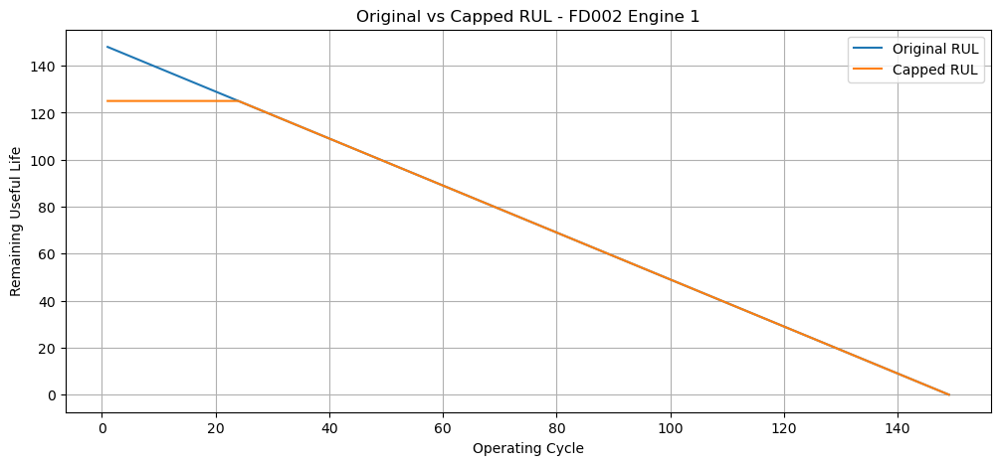

In [36]:
engine_1 = train_fd002[
    train_fd002["engine_id"] == 1
]

plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["RUL_original"],
    label="Original RUL"
)

plt.plot(
    engine_1["cycle"],
    engine_1["RUL_capped"],
    label="Capped RUL"
)

plt.xlabel("Operating Cycle")
plt.ylabel("Remaining Useful Life")
plt.title("Original vs Capped RUL - FD002 Engine 1")

plt.legend()
plt.grid()

plt.show()

In [37]:
op_cols = [
    "operational_setting_1",
    "operational_setting_2",
    "operational_setting_3"
]

train_fd002[op_cols].describe()

,operational_setting_1,operational_setting_2,operational_setting_3
count,53759.000000,53759.000000,53759.000000
mean,23.998407,0.572056,94.046020
std,14.747376,0.310016,14.237735
min,0.000000,0.000000,60.000000
25%,10.004600,0.250700,100.000000
50%,25.001300,0.700000,100.000000
75%,41.998000,0.840000,100.000000
max,42.008000,0.842000,100.000000


In [38]:
train_fd003[op_cols].describe()

,operational_setting_1,operational_setting_2,operational_setting_3
count,24720.000000,24720.000000,24720.0
mean,-0.000024,0.000005,100.0
std,0.002194,0.000294,0.0
min,-0.008600,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,-0.000000,-0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008600,0.000700,100.0


In [39]:
print("FD002 Operational Settings Range")

for col in op_cols:
    print(
        col,
        "Min:", train_fd002[col].min(),
        "Max:", train_fd002[col].max()
    )

print("\nFD003 Operational Settings Range")

for col in op_cols:
    print(
        col,
        "Min:", train_fd003[col].min(),
        "Max:", train_fd003[col].max()
    )

FD002 Operational Settings Range
operational_setting_1 Min: 0.0 Max: 42.008
operational_setting_2 Min: 0.0 Max: 0.842
operational_setting_3 Min: 60.0 Max: 100.0

FD003 Operational Settings Range
operational_setting_1 Min: -0.0086 Max: 0.0086
operational_setting_2 Min: -0.0006 Max: 0.0007
operational_setting_3 Min: 100.0 Max: 100.0


In [40]:
#=============================================================================================
#     No drop_Duplicates use K means to find unique Operating regimes
#==============================================================================================
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [41]:
op_scaler_fd002 = StandardScaler()

train_op_scaled_fd002 = op_scaler_fd002.fit_transform(
    train_fd002[op_cols]
)

test_op_scaled_fd002 = op_scaler_fd002.transform(
    test_fd002[op_cols]
)

In [42]:
kmeans_fd002 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=20
)

train_fd002["operating_condition"] = (
    kmeans_fd002.fit_predict(
        train_op_scaled_fd002
    )
)

test_fd002["operating_condition"] = (
    kmeans_fd002.predict(
        test_op_scaled_fd002
    )
)

In [43]:
train_fd002[
    "operating_condition"
].value_counts().sort_index()

operating_condition
0    13458
1     8044
2     8122
3     8002
4     8096
5     8037
Name: count, dtype: int64

In [44]:
test_fd002[
    "operating_condition"
].value_counts().sort_index()

operating_condition
0    8483
1    5148
2    5063
3    5042
4    5107
5    5148
Name: count, dtype: int64

In [45]:
condition_centers_fd002 = (
    op_scaler_fd002.inverse_transform(
        kmeans_fd002.cluster_centers_
    )
)

condition_centers_fd002 = pd.DataFrame(
    condition_centers_fd002,
    columns=op_cols
)

condition_centers_fd002.index.name = "operating_condition"

condition_centers_fd002

,operational_setting_1,operational_setting_2,operational_setting_3
operating_condition,,,
0,42.002976,0.840485,100.0
1,0.001505,0.000494,100.0
2,20.002999,0.700515,100.0
3,25.003038,0.620502,60.0
4,10.002971,0.250495,100.0
5,35.003049,0.840501,100.0


In [46]:
train_fd003["operating_condition"] = 0
test_fd003["operating_condition"] = 0

In [47]:
print(
    "FD002 Train Conditions:",
    sorted(
        train_fd002["operating_condition"].unique()
    )
)

print(
    "FD002 Test Conditions:",
    sorted(
        test_fd002["operating_condition"].unique()
    )
)

print(
    "FD003 Train Conditions:",
    train_fd003["operating_condition"].unique()
)

FD002 Train Conditions: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]
FD002 Test Conditions: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]
FD003 Train Conditions: [0]


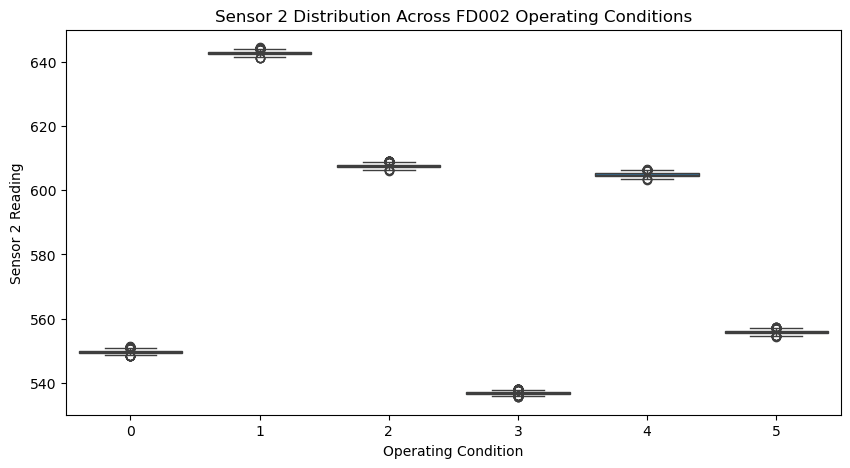

In [48]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_fd002,
    x="operating_condition",
    y="sensor_2"
)

plt.title(
    "Sensor 2 Distribution Across FD002 Operating Conditions"
)

plt.xlabel("Operating Condition")
plt.ylabel("Sensor 2 Reading")

plt.show()

In [49]:
# 9. Condition-Aware Sensor Normalization
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

print("Total sensors:", len(sensor_cols))
print(sensor_cols)

Total sensors: 21
['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [50]:
fd002_constant_sensors = [
    col for col in sensor_cols
    if train_fd002[col].nunique() == 1
]

fd003_constant_sensors = [
    col for col in sensor_cols
    if train_fd003[col].nunique() == 1
]

print("FD002 Constant Sensors:", fd002_constant_sensors)
print("FD003 Constant Sensors:", fd003_constant_sensors)

FD002 Constant Sensors: []
FD003 Constant Sensors: ['sensor_1', 'sensor_5', 'sensor_16', 'sensor_18', 'sensor_19']


In [51]:
fd002_condition_means = (
    train_fd002
    .groupby("operating_condition")[sensor_cols]
    .mean()
)

fd002_condition_stds = (
    train_fd002
    .groupby("operating_condition")[sensor_cols]
    .std()
)

fd002_condition_means.head()

,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
operating_condition,,,,,,,,,,,,,,,,,,,,,
0,445.00,549.704881,1354.463034,1127.802495,3.91,5.715840,138.630382,2211.971548,8327.889811,1.020244,...,130.549504,2388.052269,8089.438359,9.375055,0.020000,331.066503,2212.0,100.00,10.586419,6.351238
1,518.67,642.678721,1590.421137,1408.860945,14.62,21.609831,553.360726,2388.100476,9062.833793,1.300000,...,521.404623,2388.099434,8141.662577,8.442246,0.030000,393.198533,2388.0,100.00,38.817484,23.290044
2,491.19,607.564851,1485.587547,1253.118492,9.35,13.656623,334.496711,2324.021300,8729.768692,1.077731,...,314.873344,2388.154163,8065.910277,9.232689,0.022142,365.384511,2324.0,100.00,24.454191,14.672779
3,462.54,536.865069,1262.684786,1050.320924,7.05,9.027761,175.425952,1915.415771,8015.498543,0.939921,...,164.572178,2028.314200,7878.461663,10.913964,0.020000,307.348163,1915.0,84.93,14.262839,8.558454
4,489.05,604.913381,1502.012059,1311.253127,10.52,15.493286,394.324910,2318.958436,8785.436437,1.259996,...,371.445821,2388.161959,8135.127500,8.664625,0.030000,369.699728,2319.0,100.00,28.526285,17.115757


In [52]:
fd003_sensor_means = train_fd003[sensor_cols].mean()
fd003_sensor_stds = train_fd003[sensor_cols].std()

fd003_sensor_stds = fd003_sensor_stds.replace(0, 1)

In [53]:
def condition_aware_normalize_fd002(
    df,
    sensor_cols,
    condition_means,
    condition_stds
):
    df = df.copy()

    for sensor in sensor_cols:

        df[f"{sensor}_norm"] = df.apply(
            lambda row: (
                row[sensor]
                - condition_means.loc[
                    row["operating_condition"], sensor
                ]
            )
            / condition_stds.loc[
                row["operating_condition"], sensor
            ],
            axis=1
        )

    return df

In [54]:
train_fd002 = condition_aware_normalize_fd002(
    train_fd002,
    sensor_cols,
    fd002_condition_means,
    fd002_condition_stds
)

In [55]:
test_fd002 = condition_aware_normalize_fd002(
    test_fd002,
    sensor_cols,
    fd002_condition_means,
    fd002_condition_stds
)

In [56]:
def normalize_fd003(
    df,
    sensor_cols,
    train_means,
    train_stds
):
    df = df.copy()

    for sensor in sensor_cols:

        df[f"{sensor}_norm"] = (
            df[sensor] - train_means[sensor]
        ) / train_stds[sensor]

    return df

In [57]:
train_fd003 = normalize_fd003(
    train_fd003,
    sensor_cols,
    fd003_sensor_means,
    fd003_sensor_stds
)

test_fd003 = normalize_fd003(
    test_fd003,
    sensor_cols,
    fd003_sensor_means,
    fd003_sensor_stds
)

In [58]:
norm_sensor_cols = [
    f"sensor_{i}_norm"
    for i in range(1, 22)
]

print(norm_sensor_cols)

['sensor_1_norm', 'sensor_2_norm', 'sensor_3_norm', 'sensor_4_norm', 'sensor_5_norm', 'sensor_6_norm', 'sensor_7_norm', 'sensor_8_norm', 'sensor_9_norm', 'sensor_10_norm', 'sensor_11_norm', 'sensor_12_norm', 'sensor_13_norm', 'sensor_14_norm', 'sensor_15_norm', 'sensor_16_norm', 'sensor_17_norm', 'sensor_18_norm', 'sensor_19_norm', 'sensor_20_norm', 'sensor_21_norm']


In [59]:
print(
    "FD002 Normalized Missing Values:",
    train_fd002[norm_sensor_cols]
    .isnull()
    .sum()
    .sum()
)

print(
    "FD003 Normalized Missing Values:",
    train_fd003[norm_sensor_cols]
    .isnull()
    .sum()
    .sum()
)

FD002 Normalized Missing Values: 255259
FD003 Normalized Missing Values: 0


In [60]:
print(
    "FD002 Infinite Values:",
    np.isinf(
        train_fd002[norm_sensor_cols]
    ).sum().sum()
)

print(
    "FD003 Infinite Values:",
    np.isinf(
        train_fd003[norm_sensor_cols]
    ).sum().sum()
)

FD002 Infinite Values: 13458
FD003 Infinite Values: 0


In [61]:
train_fd002.groupby(
    "operating_condition"
)["sensor_2_norm"].agg(
    ["mean", "std"]
)

,mean,std
operating_condition,,
0,-7.865639e-15,1.0
1,1.204411e-13,1.0
2,1.208078e-13,1.0
3,4.355704e-14,1.0
4,-1.215158e-13,1.0
5,-1.353718e-13,1.0


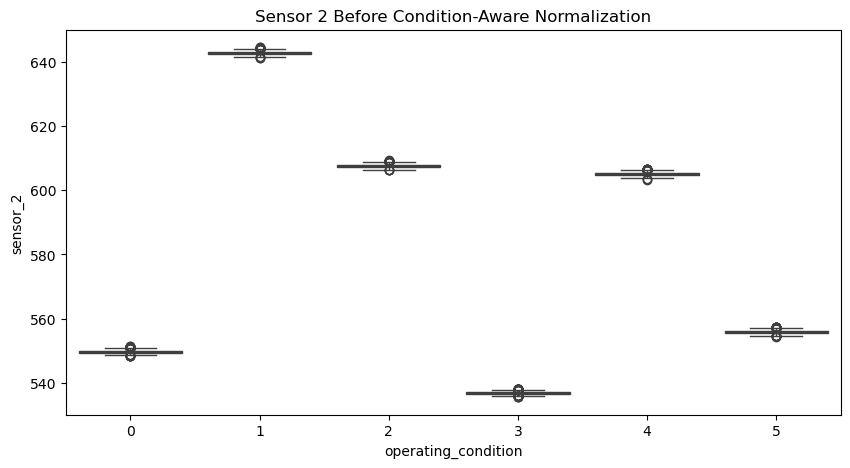

In [62]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_fd002,
    x="operating_condition",
    y="sensor_2"
)

plt.title(
    "Sensor 2 Before Condition-Aware Normalization"
)

plt.show()

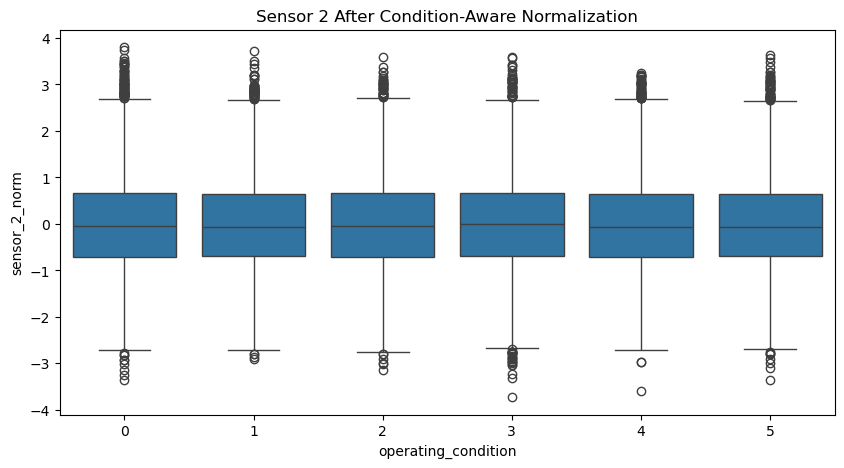

In [63]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_fd002,
    x="operating_condition",
    y="sensor_2_norm"
)

plt.title(
    "Sensor 2 After Condition-Aware Normalization"
)

plt.show()

In [64]:
# Count infinite values separately for every normalized sensor

inf_counts_fd002 = pd.Series({
    col: np.isinf(train_fd002[col]).sum()
    for col in norm_sensor_cols
})

# Sirf woh sensors rakho jin mein infinity mili hai
inf_counts_fd002 = inf_counts_fd002[
    inf_counts_fd002 > 0
]

print("Sensors containing infinite values:")
print(inf_counts_fd002)

Sensors containing infinite values:
sensor_5_norm    13458
dtype: int64


In [65]:
inf_counts_fd002

sensor_5_norm    13458
dtype: int64

In [66]:
train_fd002.groupby(
    "operating_condition"
)["sensor_5"].agg(
    ["min", "max", "mean", "std", "nunique"]
)

,min,max,mean,std,nunique
operating_condition,,,,,
0,3.91,3.91,3.91,0.0,1
1,14.62,14.62,14.62,0.0,1
2,9.35,9.35,9.35,0.0,1
3,7.05,7.05,7.05,0.0,1
4,10.52,10.52,10.52,0.0,1
5,5.48,5.48,5.48,0.0,1


In [67]:
train_fd003["sensor_5"].agg(
    ["min", "max", "mean", "std", "nunique"]
)

min        1.462000e+01
max        1.462000e+01
mean       1.462000e+01
std        3.602525e-12
nunique    1.000000e+00
Name: sensor_5, dtype: float64

In [68]:
EPSILON = 1e-8
fd002_condition_std = (
    train_fd002
    .groupby("operating_condition")[sensor_cols]
    .std()
)

problematic_fd002_sensors = []
for sensor in sensor_cols:
    if (fd002_condition_std[sensor].abs() < EPSILON).any():
        problematic_fd002_sensors.append(sensor)

print("FD002 Sensors with zero/near-zero variance within any condition:")
print(problematic_fd002_sensors)

FD002 Sensors with zero/near-zero variance within any condition:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


In [69]:
fd003_sensor_std = train_fd003[sensor_cols].std()

problematic_fd003_sensors = (
    fd003_sensor_std[
        fd003_sensor_std.abs() < EPSILON
    ]
    .index
    .tolist()
)
print("FD003 Zero/Near-Zero Variance Sensors:")
print(problematic_fd003_sensors)

FD003 Zero/Near-Zero Variance Sensors:
['sensor_1', 'sensor_5', 'sensor_16', 'sensor_18', 'sensor_19']


In [70]:
common_problematic = sorted(
    set(problematic_fd002_sensors)
    | set(problematic_fd003_sensors)
)

print("Problematic Sensors Overall:")
print(common_problematic)

Problematic Sensors Overall:
['sensor_1', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'sensor_5']


In [71]:
train_fd002.drop(
    columns=["sensor_5_norm"],
    inplace=True
)

test_fd002.drop(
    columns=["sensor_5_norm"],
    inplace=True
)

In [72]:
norm_sensor_cols = [
    f"{sensor}_norm"
    for sensor in sensor_cols
    if sensor != "sensor_5"
]

In [73]:
common_constant_sensors = [
    "sensor_1",
    "sensor_5",
    "sensor_16",
    "sensor_18",
    "sensor_19"
]

In [74]:
special_check_sensors = ["sensor_10"]

In [75]:
train_fd002.groupby(
    "operating_condition"
)["sensor_10"].agg(
    ["min", "max", "mean", "std", "nunique"]
)

,min,max,mean,std,nunique
operating_condition,,,,,
0,1.02,1.03,1.020244,0.001544,2
1,1.30,1.30,1.300000,0.000000,1
2,1.07,1.08,1.077731,0.004189,2
3,0.93,0.94,0.939921,0.000884,2
4,1.25,1.26,1.259996,0.000192,2
5,1.02,1.03,1.020391,0.001938,2


In [76]:
train_fd003["sensor_10"].agg(
    ["min", "max", "mean", "std", "nunique"]
)

min        1.290000
max        1.320000
mean       1.301232
std        0.003485
nunique    4.000000
Name: sensor_10, dtype: float64

In [77]:
excluded_sensors = [
    "sensor_1",
    "sensor_5",
    "sensor_16",
    "sensor_18",
    "sensor_19"
]

candidate_sensor_cols = [
    sensor
    for sensor in sensor_cols
    if sensor not in excluded_sensors
]

print("Original Sensors:", len(sensor_cols))
print("Excluded Sensors:", len(excluded_sensors))
print("Candidate Sensors:", len(candidate_sensor_cols))

print("\nCandidate Sensor List:")
print(candidate_sensor_cols)

Original Sensors: 21
Excluded Sensors: 5
Candidate Sensors: 16

Candidate Sensor List:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [78]:
old_norm_cols_fd002 = [
    col for col in train_fd002.columns
    if col.endswith("_norm")
]

old_norm_cols_fd003 = [
    col for col in train_fd003.columns
    if col.endswith("_norm")
]

train_fd002.drop(
    columns=old_norm_cols_fd002,
    inplace=True
)

test_fd002.drop(
    columns=[
        col for col in test_fd002.columns
        if col.endswith("_norm")
    ],
    inplace=True
)

train_fd003.drop(
    columns=old_norm_cols_fd003,
    inplace=True
)

test_fd003.drop(
    columns=[
        col for col in test_fd003.columns
        if col.endswith("_norm")
    ],
    inplace=True
)

In [79]:
EPSILON = 1e-8

In [80]:
fd002_condition_means = (
    train_fd002
    .groupby("operating_condition")[candidate_sensor_cols]
    .mean()
)

fd002_condition_stds = (
    train_fd002
    .groupby("operating_condition")[candidate_sensor_cols]
    .std()
)

In [81]:
fd002_unsafe_std = (
    fd002_condition_stds.abs() < EPSILON
)

print(
    "Number of condition-sensor combinations "
    "with near-zero std:",
    fd002_unsafe_std.sum().sum()
)

Number of condition-sensor combinations with near-zero std: 1


In [82]:
fd002_safe_stds = fd002_condition_stds.copy()

fd002_safe_stds[
    fd002_safe_stds.abs() < EPSILON
] = 1.0

In [83]:
def normalize_fd002_by_condition(
    df,
    sensors,
    condition_means,
    condition_stds
):
    result = df.copy()

    for condition in condition_means.index:

        mask = (
            result["operating_condition"] == condition
        )

        for sensor in sensors:

            mean = condition_means.loc[
                condition, sensor
            ]

            std = condition_stds.loc[
                condition, sensor
            ]

            result.loc[
                mask,
                f"{sensor}_norm"
            ] = (
                result.loc[mask, sensor] - mean
            ) / std

    return result

In [84]:
train_fd002 = normalize_fd002_by_condition(
    train_fd002,
    candidate_sensor_cols,
    fd002_condition_means,
    fd002_safe_stds
)

test_fd002 = normalize_fd002_by_condition(
    test_fd002,
    candidate_sensor_cols,
    fd002_condition_means,
    fd002_safe_stds
)

In [85]:
fd003_means = (
    train_fd003[candidate_sensor_cols].mean()
)

fd003_stds = (
    train_fd003[candidate_sensor_cols].std()
)

fd003_safe_stds = fd003_stds.copy()

fd003_safe_stds[
    fd003_safe_stds.abs() < EPSILON
] = 1.0

In [86]:
def normalize_fd003(
    df,
    sensors,
    means,
    stds
):
    result = df.copy()

    for sensor in sensors:

        result[f"{sensor}_norm"] = (
            result[sensor] - means[sensor]
        ) / stds[sensor]

    return result

In [87]:
train_fd003 = normalize_fd003(
    train_fd003,
    candidate_sensor_cols,
    fd003_means,
    fd003_safe_stds
)

test_fd003 = normalize_fd003(
    test_fd003,
    candidate_sensor_cols,
    fd003_means,
    fd003_safe_stds
)

In [88]:
norm_sensor_cols = [
    f"{sensor}_norm"
    for sensor in candidate_sensor_cols
]

print(norm_sensor_cols)
print("Total normalized candidate sensors:",
      len(norm_sensor_cols))

['sensor_2_norm', 'sensor_3_norm', 'sensor_4_norm', 'sensor_6_norm', 'sensor_7_norm', 'sensor_8_norm', 'sensor_9_norm', 'sensor_10_norm', 'sensor_11_norm', 'sensor_12_norm', 'sensor_13_norm', 'sensor_14_norm', 'sensor_15_norm', 'sensor_17_norm', 'sensor_20_norm', 'sensor_21_norm']
Total normalized candidate sensors: 16


In [89]:
print(
    "FD002 Train NaN:",
    train_fd002[norm_sensor_cols]
    .isnull()
    .sum()
    .sum()
)

print(
    "FD002 Train Inf:",
    np.isinf(
        train_fd002[norm_sensor_cols]
    ).sum().sum()
)

print(
    "FD002 Test NaN:",
    test_fd002[norm_sensor_cols]
    .isnull()
    .sum()
    .sum()
)

print(
    "FD002 Test Inf:",
    np.isinf(
        test_fd002[norm_sensor_cols]
    ).sum().sum()
)

FD002 Train NaN: 0
FD002 Train Inf: 0
FD002 Test NaN: 0
FD002 Test Inf: 0


In [90]:
print(
    "FD003 Train NaN:",
    train_fd003[norm_sensor_cols]
    .isnull()
    .sum()
    .sum()
)

print(
    "FD003 Train Inf:",
    np.isinf(
        train_fd003[norm_sensor_cols]
    ).sum().sum()
)

print(
    "FD003 Test NaN:",
    test_fd003[norm_sensor_cols]
    .isnull()
    .sum()
    .sum()
)

print(
    "FD003 Test Inf:",
    np.isinf(
        test_fd003[norm_sensor_cols]
    ).sum().sum()
)

FD003 Train NaN: 0
FD003 Train Inf: 0
FD003 Test NaN: 0
FD003 Test Inf: 0


In [91]:
#================================
#   Degradation EDA
#================================
train_fd002[norm_sensor_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
sensor_2_norm,53759.0,2.247979e-15,0.999953,-3.727910,-0.704357,-0.057482,0.647865,3.800667
sensor_3_norm,53759.0,-9.837816e-15,0.999953,-3.683135,-0.699698,-0.059612,0.645809,4.201112
sensor_4_norm,53759.0,-5.794415e-15,0.999953,-3.899446,-0.716972,-0.106408,0.622734,3.932840
sensor_6_norm,53759.0,5.181433e-13,0.999953,-7.624948,-0.699478,0.131132,0.713276,5.724057
sensor_7_norm,53759.0,-1.470174e-14,0.999953,-5.060918,-0.660998,0.038428,0.701414,3.916009
sensor_8_norm,53759.0,2.440881e-13,0.999953,-2.907792,-0.618376,-0.168522,0.395199,7.958592
sensor_9_norm,53759.0,9.334506e-15,0.999953,-2.199277,-0.579215,-0.200385,0.258692,8.347774
sensor_10_norm,53759.0,-1.386959e-14,0.922113,-51.935859,-0.158295,0.000000,0.089076,6.316867
sensor_11_norm,53759.0,-2.228946e-15,0.999953,-2.740590,-0.744624,-0.120436,0.616935,3.873917
sensor_12_norm,53759.0,7.917623e-15,0.999953,-4.196128,-0.646015,0.051839,0.698487,4.110977


In [92]:
train_fd003[norm_sensor_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
sensor_2_norm,24720.0,1.605505e-14,1.0,-3.093235,-0.722439,-0.110621,0.635033,5.070715
sensor_3_norm,24720.0,-1.091338e-14,1.0,-3.491588,-0.704681,-0.082106,0.636279,4.010154
sensor_4_norm,24720.0,-2.131168e-14,1.0,-2.804739,-0.745276,-0.159745,0.627103,3.754028
sensor_6_norm,24720.0,8.250574e-14,1.0,-8.050398,-0.874421,0.229575,0.781573,0.781573
sensor_7_norm,24720.0,-1.241035e-14,1.0,-1.609909,-0.591680,-0.318213,0.260722,4.464551
sensor_8_norm,24720.0,1.219151e-12,1.0,-7.401555,-0.452062,-0.009822,0.432419,3.338570
sensor_9_norm,24720.0,-1.188377e-14,1.0,-2.308815,-0.610142,-0.205243,0.299380,8.520355
sensor_10_norm,24720.0,-8.339564e-14,1.0,-3.223037,-0.353472,-0.353472,-0.353472,5.385658
sensor_11_norm,24720.0,3.035328e-15,1.0,-2.418425,-0.752170,-0.185643,0.614159,3.413467
sensor_12_norm,24720.0,-1.792913e-14,1.0,-1.622231,-0.583929,-0.328961,0.242412,4.407909


In [93]:
engine_1 = train_fd002[
    train_fd002["engine_id"] == 1
]

In [94]:
sensors_to_plot = [
    "sensor_2_norm",
    "sensor_3_norm",
    "sensor_4_norm",
    "sensor_7_norm",
    "sensor_11_norm",
    "sensor_12_norm",
    "sensor_15_norm"
]

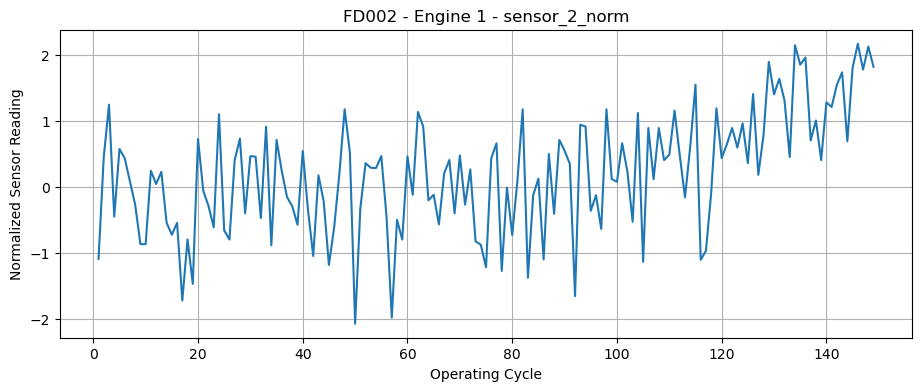

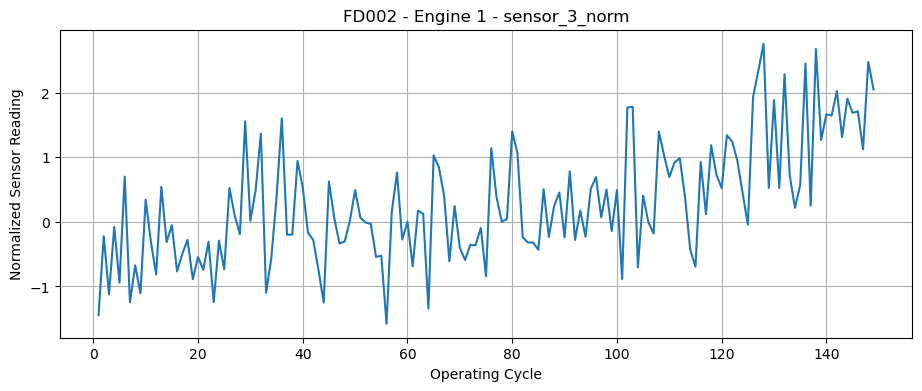

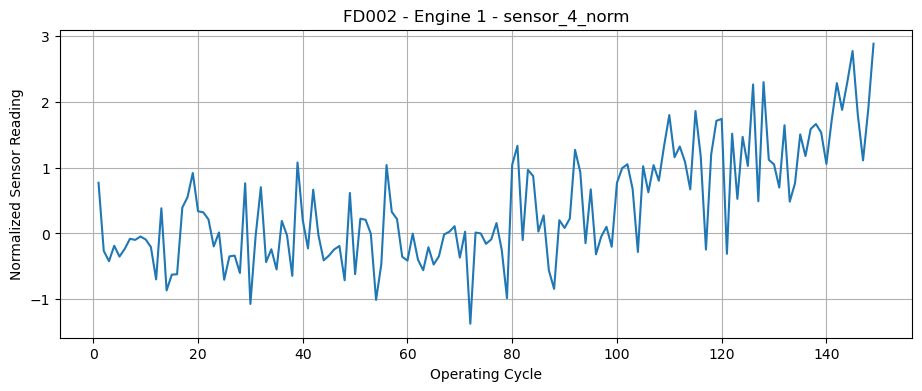

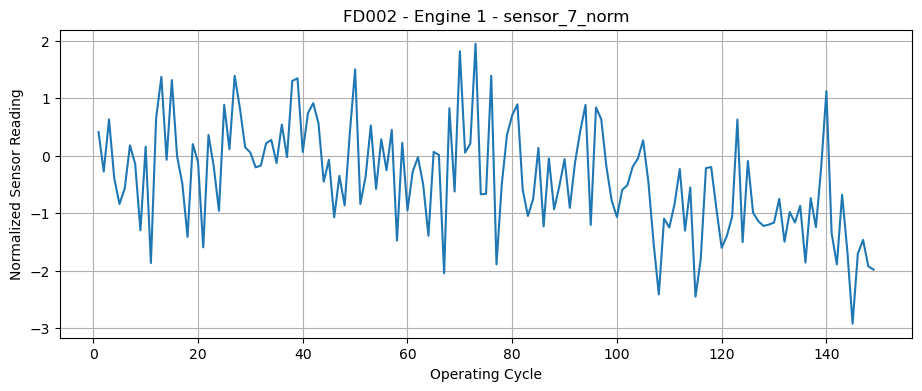

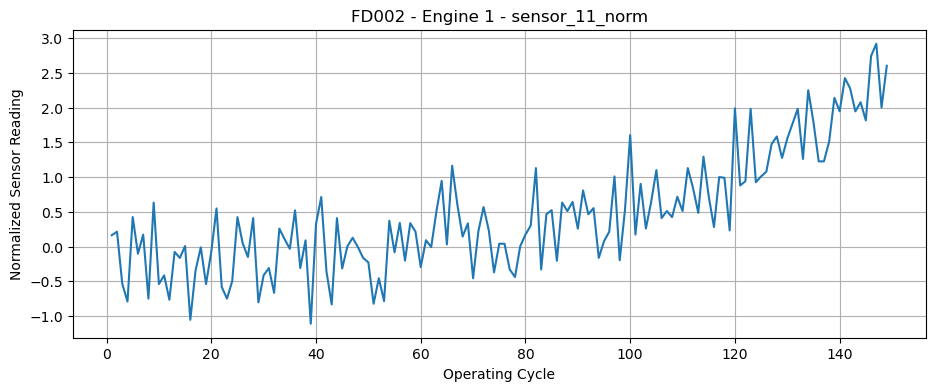

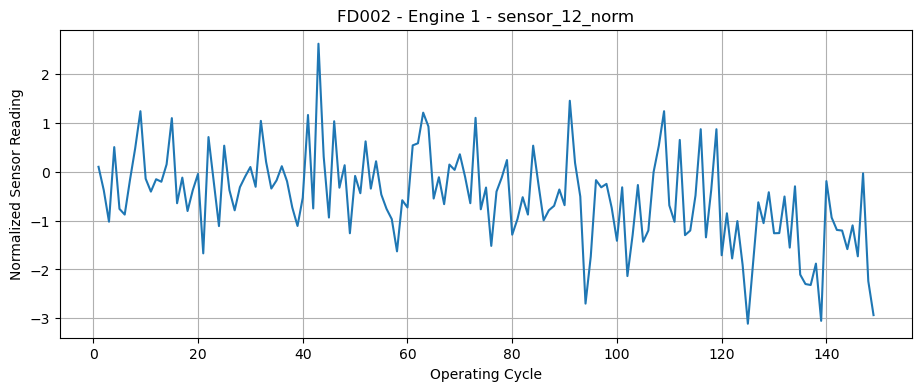

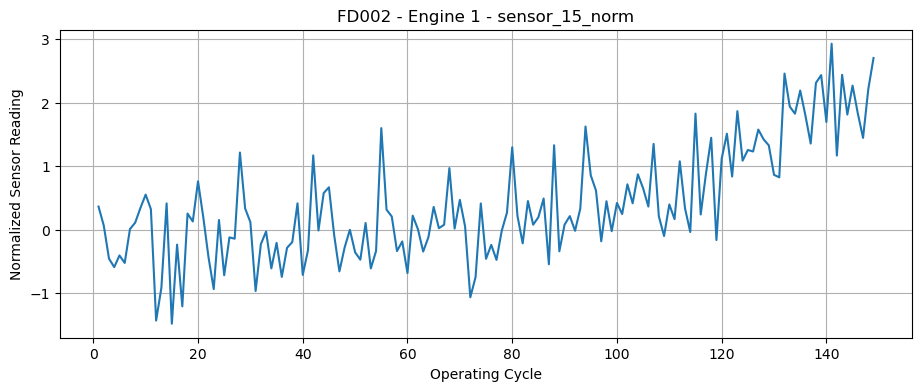

In [95]:
for sensor in sensors_to_plot:

    plt.figure(figsize=(11, 4))

    plt.plot(
        engine_1["cycle"],
        engine_1[sensor]
    )

    plt.xlabel("Operating Cycle")
    plt.ylabel("Normalized Sensor Reading")

    plt.title(
        f"FD002 - Engine 1 - {sensor}"
    )

    plt.grid()
    plt.show()

In [96]:
# ============================================================
# Pearson correlation of normalized sensors with capped RUL
# ============================================================

# FD002: correlation of each normalized sensor with RUL
fd002_rul_corr = (
    train_fd002[
        norm_sensor_cols + ["RUL_capped"]
    ]
    .corr()["RUL_capped"]
    .drop("RUL_capped")
    .sort_values(
        key=abs,
        ascending=False
    )
)

# FD003: correlation of each normalized sensor with RUL
fd003_rul_corr = (
    train_fd003[
        norm_sensor_cols + ["RUL_capped"]
    ]
    .corr()["RUL_capped"]
    .drop("RUL_capped")
    .sort_values(
        key=abs,
        ascending=False
    )
)

print("FD002 RUL Correlation:")
print(fd002_rul_corr)

print("\nFD003 RUL Correlation:")
print(fd003_rul_corr)

FD002 RUL Correlation:
sensor_11_norm   -0.770679
sensor_4_norm    -0.737635
sensor_15_norm   -0.724126
sensor_17_norm   -0.648756
sensor_2_norm    -0.630409
sensor_3_norm    -0.618035
sensor_12_norm    0.534934
sensor_7_norm     0.509541
sensor_20_norm    0.483756
sensor_21_norm    0.479197
sensor_13_norm   -0.476411
sensor_8_norm    -0.475319
sensor_9_norm    -0.422450
sensor_6_norm    -0.362654
sensor_14_norm   -0.321572
sensor_10_norm    0.038181
Name: RUL_capped, dtype: float64

FD003 RUL Correlation:
sensor_11_norm   -0.804532
sensor_4_norm    -0.770051
sensor_17_norm   -0.725751
sensor_3_norm    -0.696364
sensor_2_norm    -0.681722
sensor_9_norm    -0.643791
sensor_13_norm   -0.634565
sensor_8_norm    -0.634102
sensor_14_norm   -0.563636
sensor_10_norm   -0.494808
sensor_12_norm   -0.374957
sensor_7_norm    -0.356735
sensor_6_norm    -0.096395
sensor_20_norm    0.050340
sensor_21_norm    0.041641
sensor_15_norm   -0.002052
Name: RUL_capped, dtype: float64


In [97]:
# ============================================================
# Compare FD002 and FD003 Pearson correlations
# ============================================================

sensor_corr_comparison = pd.DataFrame({
    "FD002_Correlation": fd002_rul_corr,
    "FD003_Correlation": fd003_rul_corr
})

# Absolute correlation helps compare strength regardless of sign
sensor_corr_comparison["FD002_Abs"] = (
    sensor_corr_comparison["FD002_Correlation"].abs()
)

sensor_corr_comparison["FD003_Abs"] = (
    sensor_corr_comparison["FD003_Correlation"].abs()
)

# Average correlation strength across both datasets
sensor_corr_comparison["Average_Abs_Correlation"] = (
    sensor_corr_comparison["FD002_Abs"]
    + sensor_corr_comparison["FD003_Abs"]
) / 2

sensor_corr_comparison.sort_values(
    "Average_Abs_Correlation",
    ascending=False
)

,FD002_Correlation,FD003_Correlation,FD002_Abs,FD003_Abs,Average_Abs_Correlation
sensor_11_norm,-0.770679,-0.804532,0.770679,0.804532,0.787606
sensor_4_norm,-0.737635,-0.770051,0.737635,0.770051,0.753843
sensor_17_norm,-0.648756,-0.725751,0.648756,0.725751,0.687253
sensor_3_norm,-0.618035,-0.696364,0.618035,0.696364,0.657200
sensor_2_norm,-0.630409,-0.681722,0.630409,0.681722,0.656066
sensor_13_norm,-0.476411,-0.634565,0.476411,0.634565,0.555488
sensor_8_norm,-0.475319,-0.634102,0.475319,0.634102,0.554711
sensor_9_norm,-0.422450,-0.643791,0.422450,0.643791,0.533121
sensor_12_norm,0.534934,-0.374957,0.534934,0.374957,0.454945
sensor_14_norm,-0.321572,-0.563636,0.321572,0.563636,0.442604


In [98]:
sensor_corr_comparison = pd.DataFrame({
    "FD002_Correlation": fd002_rul_corr,
    "FD003_Correlation": fd003_rul_corr
})

sensor_corr_comparison[
    "FD002_Abs"
] = sensor_corr_comparison[
    "FD002_Correlation"
].abs()

sensor_corr_comparison[
    "FD003_Abs"
] = sensor_corr_comparison[
    "FD003_Correlation"
].abs()

sensor_corr_comparison[
    "Average_Abs_Correlation"
] = (
    sensor_corr_comparison["FD002_Abs"]
    +
    sensor_corr_comparison["FD003_Abs"]
)/2

sensor_corr_comparison.sort_values(
    "Average_Abs_Correlation",
    ascending=False
)

,FD002_Correlation,FD003_Correlation,FD002_Abs,FD003_Abs,Average_Abs_Correlation
sensor_11_norm,-0.770679,-0.804532,0.770679,0.804532,0.787606
sensor_4_norm,-0.737635,-0.770051,0.737635,0.770051,0.753843
sensor_17_norm,-0.648756,-0.725751,0.648756,0.725751,0.687253
sensor_3_norm,-0.618035,-0.696364,0.618035,0.696364,0.657200
sensor_2_norm,-0.630409,-0.681722,0.630409,0.681722,0.656066
sensor_13_norm,-0.476411,-0.634565,0.476411,0.634565,0.555488
sensor_8_norm,-0.475319,-0.634102,0.475319,0.634102,0.554711
sensor_9_norm,-0.422450,-0.643791,0.422450,0.643791,0.533121
sensor_12_norm,0.534934,-0.374957,0.534934,0.374957,0.454945
sensor_14_norm,-0.321572,-0.563636,0.321572,0.563636,0.442604


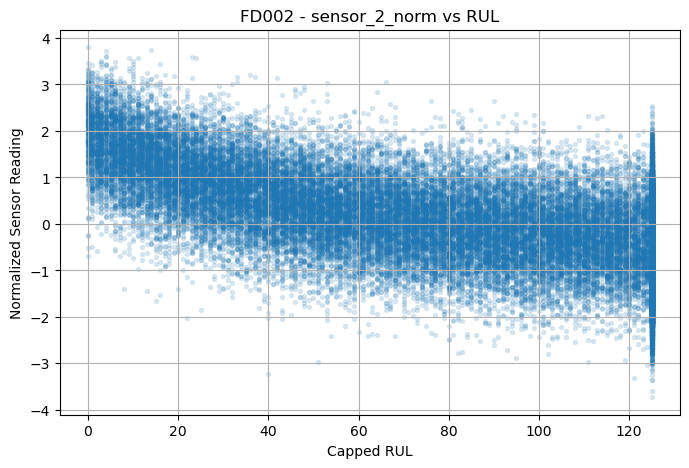

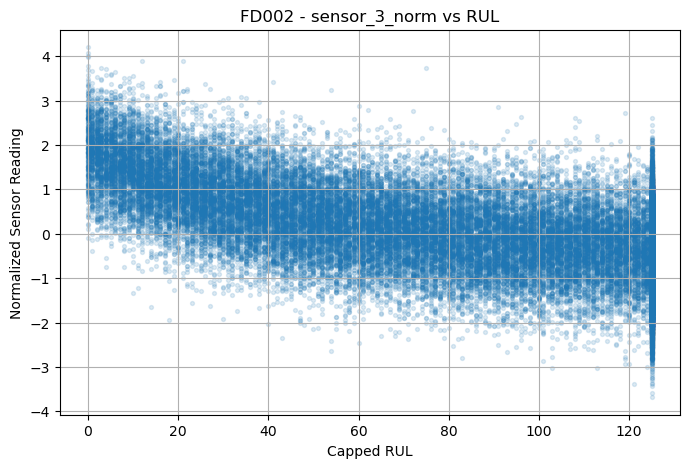

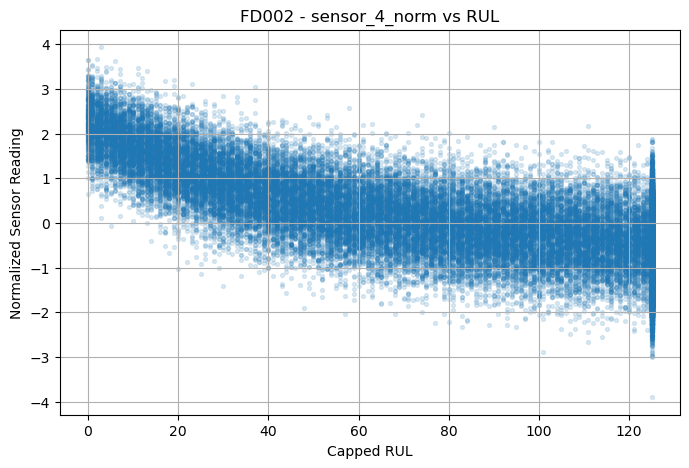

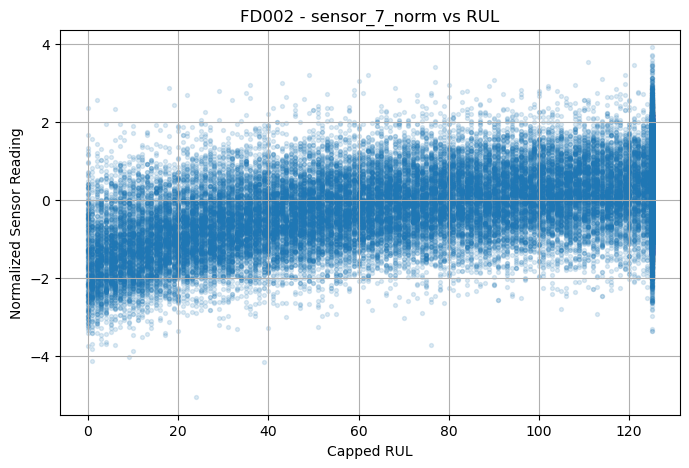

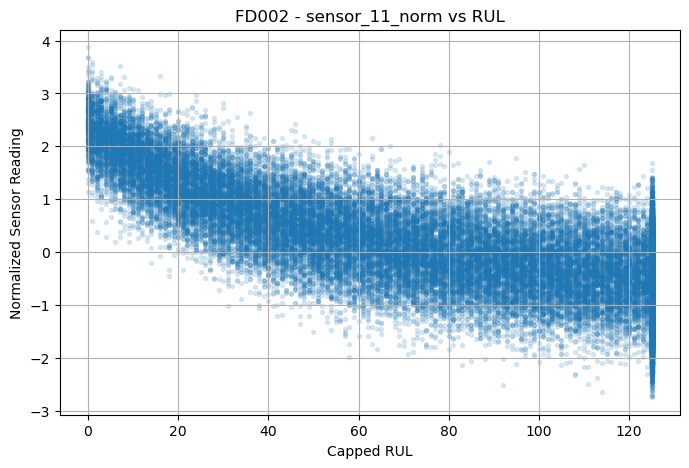

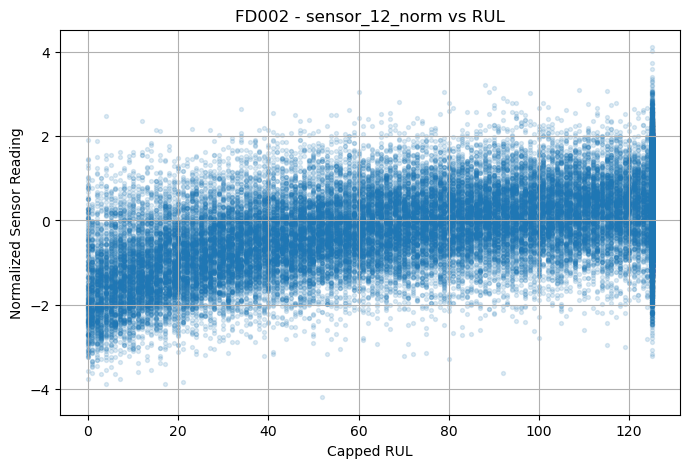

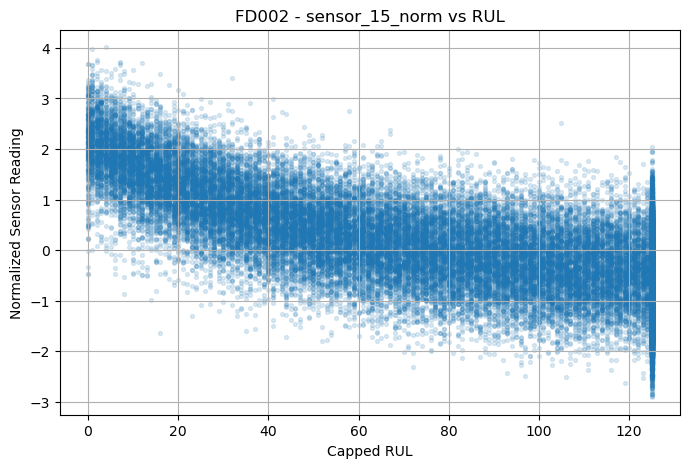

In [99]:
for sensor in sensors_to_plot:

    plt.figure(figsize=(8, 5))

    plt.scatter(
        train_fd002["RUL_capped"],
        train_fd002[sensor],
        alpha=0.15,
        s=8
    )

    plt.xlabel("Capped RUL")
    plt.ylabel("Normalized Sensor Reading")

    plt.title(
        f"FD002 - {sensor} vs RUL"
    )

    plt.grid()
    plt.show()

In [100]:
# ============================================================
# PEARSON CORRELATION: Sensors vs Capped RUL
# ============================================================

# Calculate Pearson correlation between normalized sensors
# and the target RUL for FD002
fd002_rul_corr = (
    train_fd002[norm_sensor_cols + ["RUL_capped"]]
    .corr(method="pearson")["RUL_capped"]
    .drop("RUL_capped")
)

# Calculate the same correlation for FD003
fd003_rul_corr = (
    train_fd003[norm_sensor_cols + ["RUL_capped"]]
    .corr(method="pearson")["RUL_capped"]
    .drop("RUL_capped")
)

print("FD002 Pearson Correlation:")
print(fd002_rul_corr.sort_values(key=abs, ascending=False))

print("\nFD003 Pearson Correlation:")
print(fd003_rul_corr.sort_values(key=abs, ascending=False))

FD002 Pearson Correlation:
sensor_11_norm   -0.770679
sensor_4_norm    -0.737635
sensor_15_norm   -0.724126
sensor_17_norm   -0.648756
sensor_2_norm    -0.630409
sensor_3_norm    -0.618035
sensor_12_norm    0.534934
sensor_7_norm     0.509541
sensor_20_norm    0.483756
sensor_21_norm    0.479197
sensor_13_norm   -0.476411
sensor_8_norm    -0.475319
sensor_9_norm    -0.422450
sensor_6_norm    -0.362654
sensor_14_norm   -0.321572
sensor_10_norm    0.038181
Name: RUL_capped, dtype: float64

FD003 Pearson Correlation:
sensor_11_norm   -0.804532
sensor_4_norm    -0.770051
sensor_17_norm   -0.725751
sensor_3_norm    -0.696364
sensor_2_norm    -0.681722
sensor_9_norm    -0.643791
sensor_13_norm   -0.634565
sensor_8_norm    -0.634102
sensor_14_norm   -0.563636
sensor_10_norm   -0.494808
sensor_12_norm   -0.374957
sensor_7_norm    -0.356735
sensor_6_norm    -0.096395
sensor_20_norm    0.050340
sensor_21_norm    0.041641
sensor_15_norm   -0.002052
Name: RUL_capped, dtype: float64


In [101]:
# ============================================================
# COMBINE FD002 AND FD003 PEARSON CORRELATIONS
# ============================================================

# Put both datasets side-by-side so that every sensor
# can be compared across FD002 and FD003
rul_correlation_comparison = pd.DataFrame({
    "FD002": fd002_rul_corr,
    "FD003": fd003_rul_corr
})

# Sort sensors using their average absolute correlation
# so the strongest overall relationships appear first
rul_correlation_comparison["Average_Abs"] = (
    rul_correlation_comparison["FD002"].abs()
    + rul_correlation_comparison["FD003"].abs()
) / 2

rul_correlation_comparison = (
    rul_correlation_comparison
    .sort_values("Average_Abs", ascending=False)
)

# Display result
rul_correlation_comparison

,FD002,FD003,Average_Abs
sensor_11_norm,-0.770679,-0.804532,0.787606
sensor_4_norm,-0.737635,-0.770051,0.753843
sensor_17_norm,-0.648756,-0.725751,0.687253
sensor_3_norm,-0.618035,-0.696364,0.657200
sensor_2_norm,-0.630409,-0.681722,0.656066
sensor_13_norm,-0.476411,-0.634565,0.555488
sensor_8_norm,-0.475319,-0.634102,0.554711
sensor_9_norm,-0.422450,-0.643791,0.533121
sensor_12_norm,0.534934,-0.374957,0.454945
sensor_14_norm,-0.321572,-0.563636,0.442604


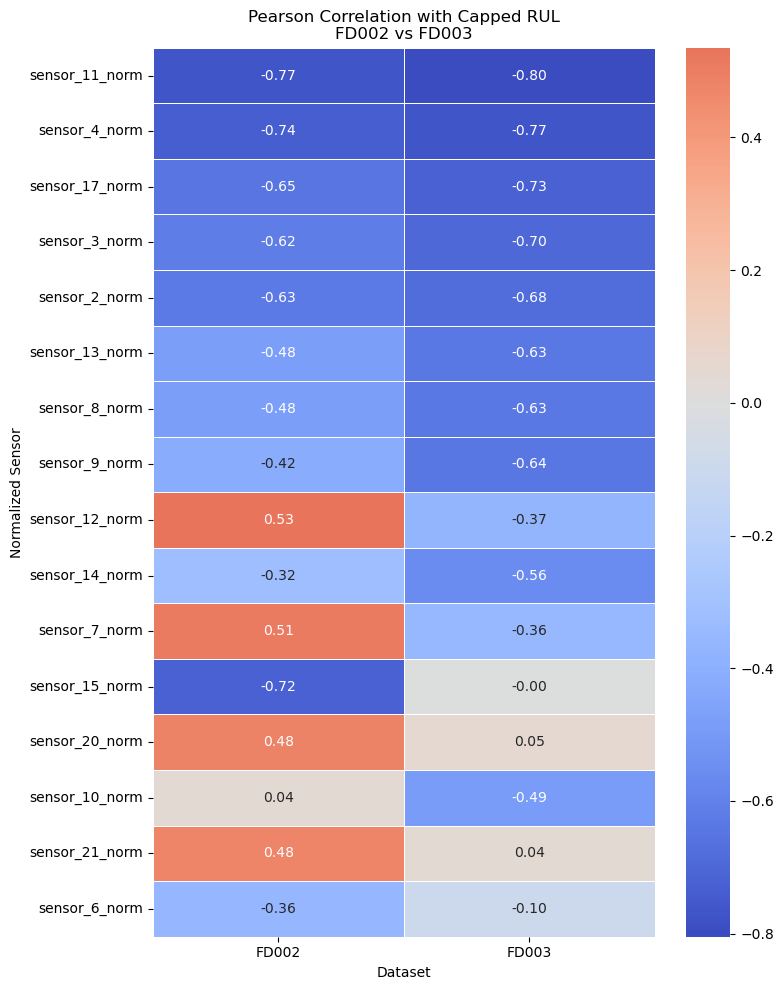

In [102]:
# ============================================================
# PEARSON CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(8, 10))

sns.heatmap(
    rul_correlation_comparison[["FD002", "FD003"]],
    annot=True,          # Show correlation value in each box
    fmt=".2f",           # Two decimal places
    cmap="coolwarm",     # Visual separation of +/- correlation
    center=0,            # Zero is the center
    linewidths=0.5
)

plt.title(
    "Pearson Correlation with Capped RUL\nFD002 vs FD003"
)

plt.xlabel("Dataset")
plt.ylabel("Normalized Sensor")

plt.tight_layout()
plt.show()

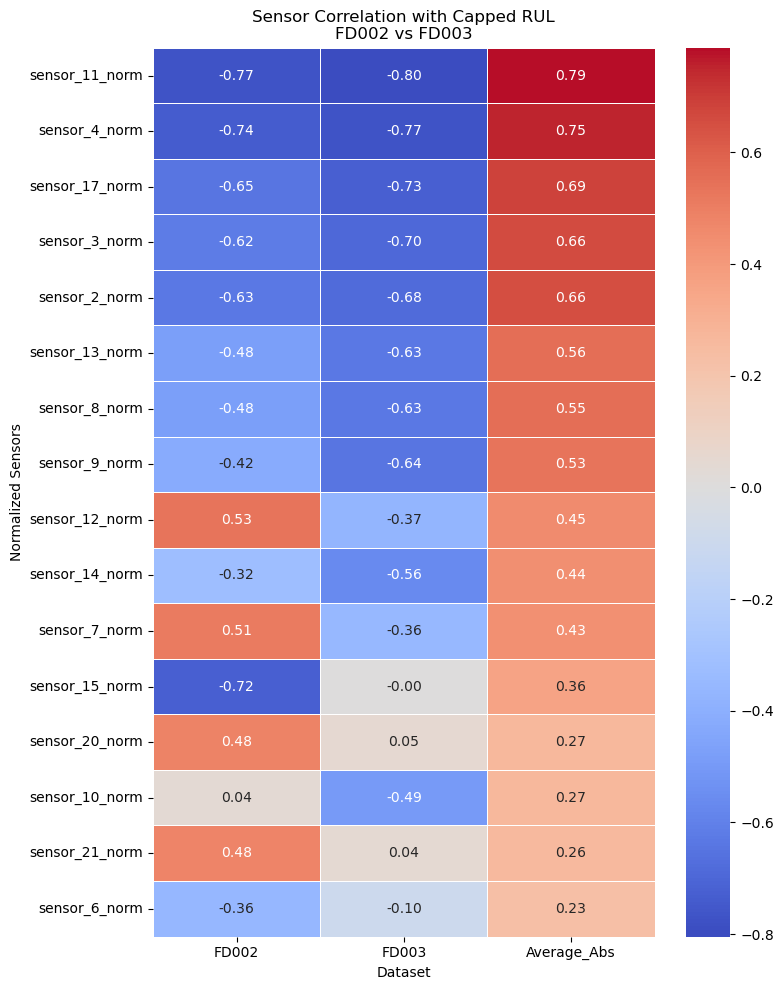

In [103]:
# ============================================================
# Heatmap: Sensor correlation with RUL
# ============================================================

plt.figure(figsize=(8, 10))

# Heatmap shows positive and negative correlations visually
sns.heatmap(
    rul_correlation_comparison,
    annot=True,          # Display correlation values inside cells
    fmt=".2f",           # Show values with 2 decimal places
    cmap="coolwarm",     # Negative and positive correlation visually separate
    center=0,            # 0 correlation remains at the center of color scale
    linewidths=0.5
)

plt.title(
    "Sensor Correlation with Capped RUL\nFD002 vs FD003"
)

plt.xlabel("Dataset")
plt.ylabel("Normalized Sensors")

plt.tight_layout()
plt.show()

In [104]:
# ============================================================
# SPEARMAN CORRELATION: Sensors vs Capped RUL
# ============================================================

# Calculate Spearman correlation between normalized sensors
# and capped RUL for FD002
fd002_spearman_corr = (
    train_fd002[norm_sensor_cols + ["RUL_capped"]]
    .corr(method="spearman")["RUL_capped"]
    .drop("RUL_capped")
)

# Calculate Spearman correlation for FD003
fd003_spearman_corr = (
    train_fd003[norm_sensor_cols + ["RUL_capped"]]
    .corr(method="spearman")["RUL_capped"]
    .drop("RUL_capped")
)

# Display strongest relationships first
print("FD002 Spearman Correlation:")
print(
    fd002_spearman_corr.sort_values(
        key=abs,
        ascending=False
    )
)

print("\nFD003 Spearman Correlation:")
print(
    fd003_spearman_corr.sort_values(
        key=abs,
        ascending=False
    )
)

FD002 Spearman Correlation:
sensor_11_norm   -0.715043
sensor_4_norm    -0.684934
sensor_15_norm   -0.673855
sensor_17_norm   -0.602969
sensor_2_norm    -0.591529
sensor_3_norm    -0.577793
sensor_12_norm    0.499377
sensor_7_norm     0.476816
sensor_20_norm    0.454388
sensor_21_norm    0.448242
sensor_13_norm   -0.384902
sensor_8_norm    -0.384773
sensor_6_norm    -0.357926
sensor_9_norm    -0.292481
sensor_14_norm   -0.164138
sensor_10_norm    0.071912
Name: RUL_capped, dtype: float64

FD003 Spearman Correlation:
sensor_11_norm   -0.738877
sensor_13_norm   -0.715085
sensor_8_norm    -0.713620
sensor_4_norm    -0.708766
sensor_17_norm   -0.680327
sensor_3_norm    -0.654640
sensor_2_norm    -0.636479
sensor_9_norm    -0.565148
sensor_14_norm   -0.469242
sensor_10_norm   -0.454520
sensor_6_norm    -0.180895
sensor_21_norm    0.083623
sensor_20_norm    0.083597
sensor_15_norm   -0.077709
sensor_12_norm   -0.053771
sensor_7_norm    -0.043719
Name: RUL_capped, dtype: float64


In [105]:
# ============================================================
# COMBINE FD002 AND FD003 SPEARMAN CORRELATIONS
# ============================================================

# Combine both datasets so every sensor can be compared
# across FD002 and FD003
spearman_comparison = pd.DataFrame({
    "FD002": fd002_spearman_corr,
    "FD003": fd003_spearman_corr
})

# Calculate average absolute correlation strength
# Absolute value is used because both + and - correlations
# can represent strong relationships
spearman_comparison["Average_Abs"] = (
    spearman_comparison["FD002"].abs()
    + spearman_comparison["FD003"].abs()
) / 2

# Sort strongest overall sensors first
spearman_comparison = (
    spearman_comparison
    .sort_values(
        "Average_Abs",
        ascending=False
    )
)

# Display comparison
spearman_comparison

,FD002,FD003,Average_Abs
sensor_11_norm,-0.715043,-0.738877,0.726960
sensor_4_norm,-0.684934,-0.708766,0.696850
sensor_17_norm,-0.602969,-0.680327,0.641648
sensor_3_norm,-0.577793,-0.654640,0.616217
sensor_2_norm,-0.591529,-0.636479,0.614004
sensor_13_norm,-0.384902,-0.715085,0.549994
sensor_8_norm,-0.384773,-0.713620,0.549196
sensor_9_norm,-0.292481,-0.565148,0.428815
sensor_15_norm,-0.673855,-0.077709,0.375782
sensor_14_norm,-0.164138,-0.469242,0.316690


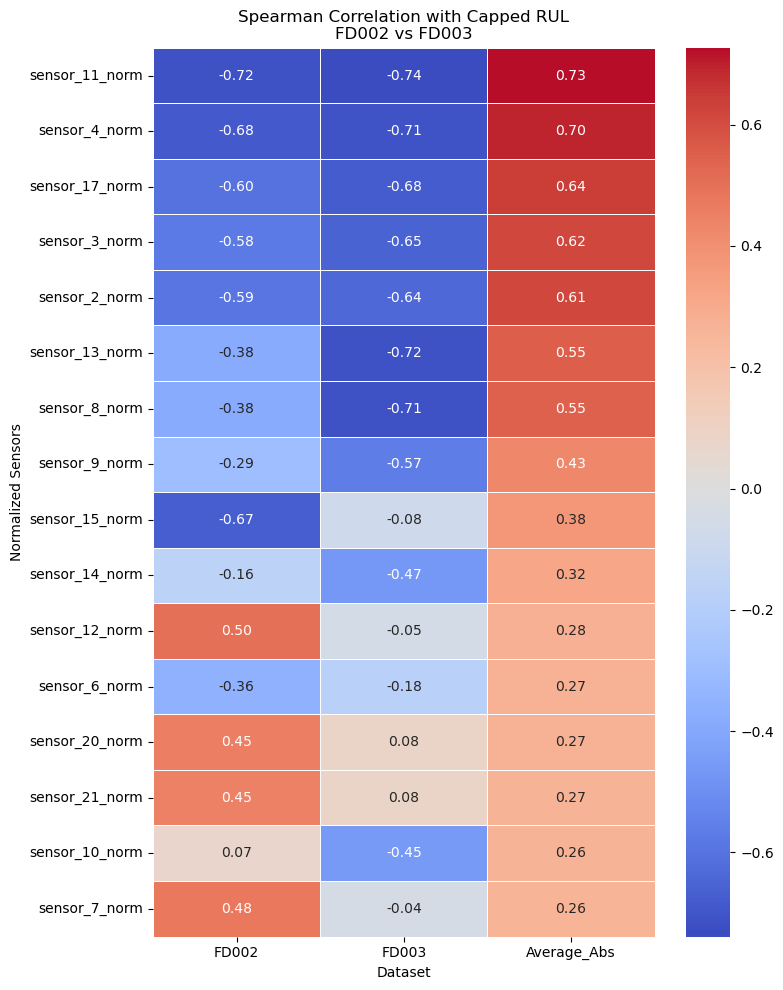

In [106]:
# ============================================================
# Heatmap: Spearman correlation with RUL
# ============================================================

plt.figure(figsize=(8, 10))

sns.heatmap(
    spearman_comparison,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Spearman Correlation with Capped RUL\nFD002 vs FD003"
)

plt.xlabel("Dataset")
plt.ylabel("Normalized Sensors")

plt.tight_layout()
plt.show()

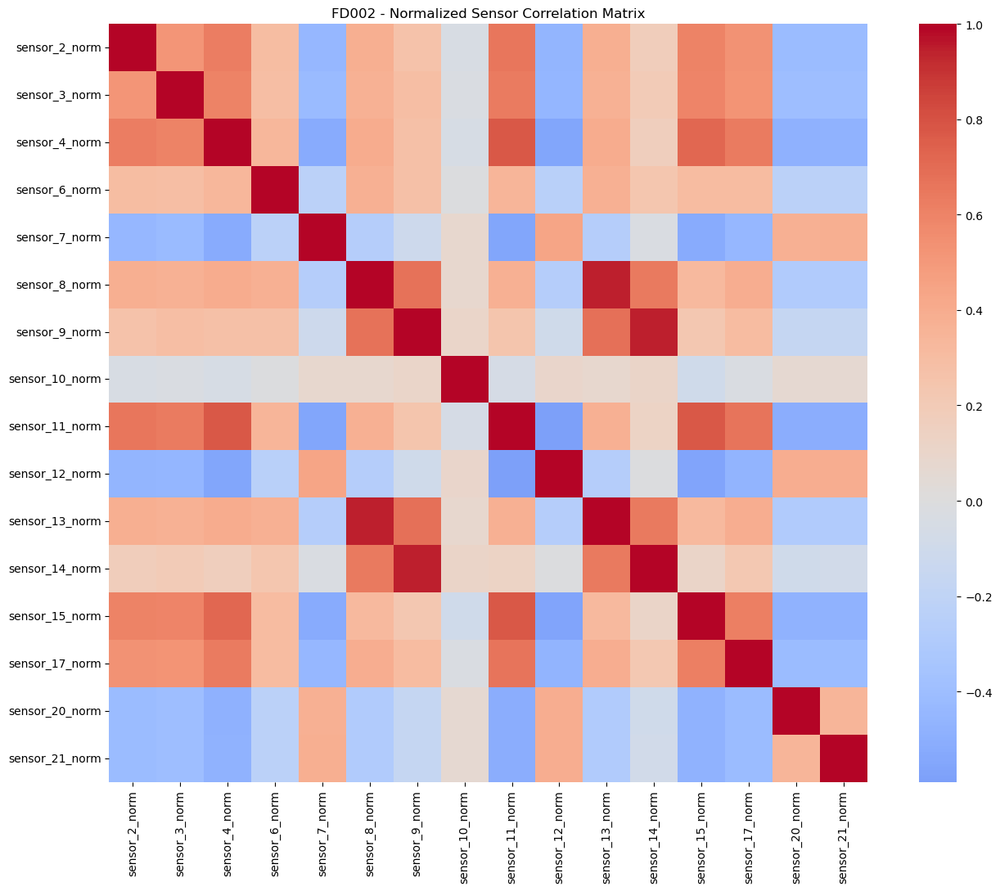

In [107]:
# ============================================================
# Sensor-to-Sensor correlation heatmap for FD002
# Helps identify highly redundant sensors
# ============================================================

fd002_sensor_corr_matrix = (
    train_fd002[norm_sensor_cols]
    .corr()
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    fd002_sensor_corr_matrix,
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "FD002 - Normalized Sensor Correlation Matrix"
)

plt.tight_layout()
plt.show()

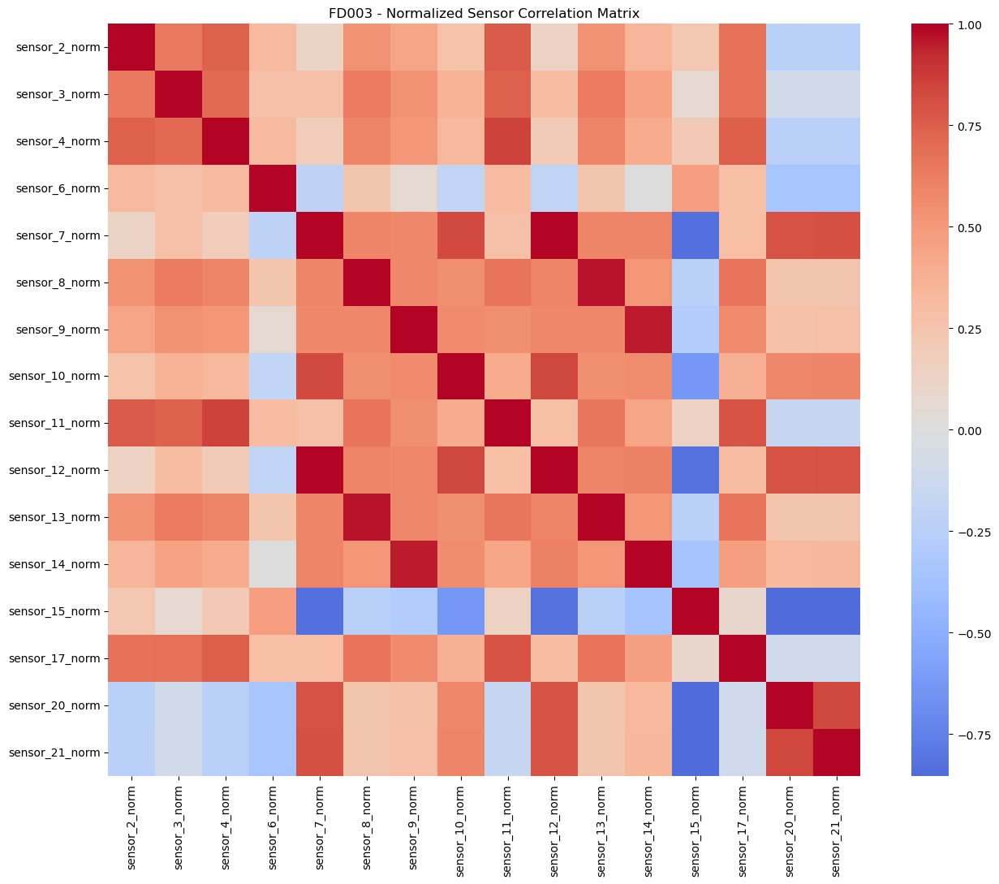

In [108]:
# ============================================================
# Sensor-to-Sensor correlation heatmap for FD003
# ============================================================

fd003_sensor_corr_matrix = (
    train_fd003[norm_sensor_cols]
    .corr()
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    fd003_sensor_corr_matrix,
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "FD003 - Normalized Sensor Correlation Matrix"
)

plt.tight_layout()
plt.show()

In [109]:
# ============================================================
# CREATE ENGINE HEALTH STAGES FOR EDA
# ============================================================

def create_health_stage(rul):
    """
    Categorize engine condition using capped RUL.

    These labels are currently used for exploratory analysis.
    Final maintenance thresholds can be optimized later.
    """

    if rul > 75:
        return "Healthy"

    elif rul > 30:
        return "Warning"

    else:
        return "Critical"


# Create health-stage labels for FD002 training data
train_fd002["health_stage"] = (
    train_fd002["RUL_capped"]
    .apply(create_health_stage)
)

# Create health-stage labels for FD003 training data
train_fd003["health_stage"] = (
    train_fd003["RUL_capped"]
    .apply(create_health_stage)
)

In [110]:
# ============================================================
# CHECK NUMBER OF OBSERVATIONS IN EACH HEALTH STAGE
# ============================================================

print("FD002 Health Stage Distribution:")
print(
    train_fd002["health_stage"]
    .value_counts()
)

print("\nFD003 Health Stage Distribution:")
print(
    train_fd003["health_stage"]
    .value_counts()
)

FD002 Health Stage Distribution:
health_stage
Healthy     33999
Warning     11700
Critical     8060
Name: count, dtype: int64

FD003 Health Stage Distribution:
health_stage
Healthy     17120
Warning      4500
Critical     3100
Name: count, dtype: int64


In [111]:
# ============================================================
# VERIFY RUL RANGE OF EACH HEALTH STAGE
# ============================================================

print(
    train_fd002.groupby("health_stage")[
        "RUL_capped"
    ].agg(["min", "max", "mean", "count"])
)

              min  max        mean  count
health_stage                             
Critical        0   30   15.000000   8060
Healthy        76  125  115.632077  33999
Warning        31   75   53.000000  11700


In [112]:
# ============================================================
# FD002: MEAN NORMALIZED SENSOR VALUES BY HEALTH STAGE
# ============================================================

fd002_stage_sensor_means = (
    train_fd002
    .groupby("health_stage")[norm_sensor_cols]
    .mean()
)

# Keep health stages in logical degradation order
fd002_stage_sensor_means = (
    fd002_stage_sensor_means
    .reindex(["Healthy", "Warning", "Critical"])
)

fd002_stage_sensor_means

,sensor_2_norm,sensor_3_norm,sensor_4_norm,sensor_6_norm,sensor_7_norm,sensor_8_norm,sensor_9_norm,sensor_10_norm,sensor_11_norm,sensor_12_norm,sensor_13_norm,sensor_14_norm,sensor_15_norm,sensor_17_norm,sensor_20_norm,sensor_21_norm
health_stage,,,,,,,,,,,,,,,,
Healthy,-0.413946,-0.406737,-0.484448,-0.245048,0.335437,-0.311959,-0.277300,0.025081,-0.506322,0.350285,-0.312356,-0.210776,-0.475457,-0.425916,0.317131,0.314834
Warning,0.323481,0.317328,0.368322,0.250822,-0.263772,0.219741,0.190938,-0.039707,0.389009,-0.269183,0.219771,0.137498,0.364374,0.326773,-0.245655,-0.238230
Critical,1.276554,1.255077,1.508857,0.669573,-1.032057,0.996940,0.892552,-0.048157,1.571096,-1.086837,0.998570,0.689507,1.476660,1.322265,-0.981137,-0.982226


In [113]:
# ============================================================
# FD003: MEAN NORMALIZED SENSOR VALUES BY HEALTH STAGE
# ============================================================

fd003_stage_sensor_means = (
    train_fd003
    .groupby("health_stage")[norm_sensor_cols]
    .mean()
)

fd003_stage_sensor_means = (
    fd003_stage_sensor_means
    .reindex(["Healthy", "Warning", "Critical"])
)

fd003_stage_sensor_means

,sensor_2_norm,sensor_3_norm,sensor_4_norm,sensor_6_norm,sensor_7_norm,sensor_8_norm,sensor_9_norm,sensor_10_norm,sensor_11_norm,sensor_12_norm,sensor_13_norm,sensor_14_norm,sensor_15_norm,sensor_17_norm,sensor_20_norm,sensor_21_norm
health_stage,,,,,,,,,,,,,,,,
Healthy,-0.396491,-0.404683,-0.447518,-0.053582,-0.207956,-0.366762,-0.372875,-0.304193,-0.467450,-0.218492,-0.367433,-0.326121,-0.000400,-0.421912,0.027786,0.023716
Warning,0.499787,0.501076,0.541548,0.113778,0.249210,0.476067,0.423278,0.434064,0.566763,0.259002,0.476002,0.361074,0.012839,0.528040,-0.036488,-0.037533
Critical,1.464158,1.507528,1.685338,0.130750,0.786700,1.334406,1.444796,1.049838,1.758812,0.830670,1.338210,1.276890,-0.016430,1.563534,-0.100483,-0.076492


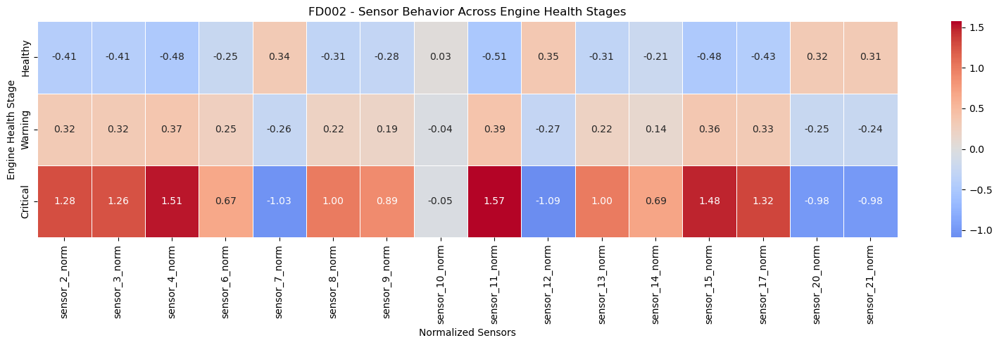

In [114]:
# ============================================================
# FD002 HEALTH-STAGE SENSOR HEATMAP
# ============================================================

plt.figure(figsize=(16, 5))

sns.heatmap(
    fd002_stage_sensor_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "FD002 - Sensor Behavior Across Engine Health Stages"
)

plt.xlabel("Normalized Sensors")
plt.ylabel("Engine Health Stage")

plt.tight_layout()
plt.show()

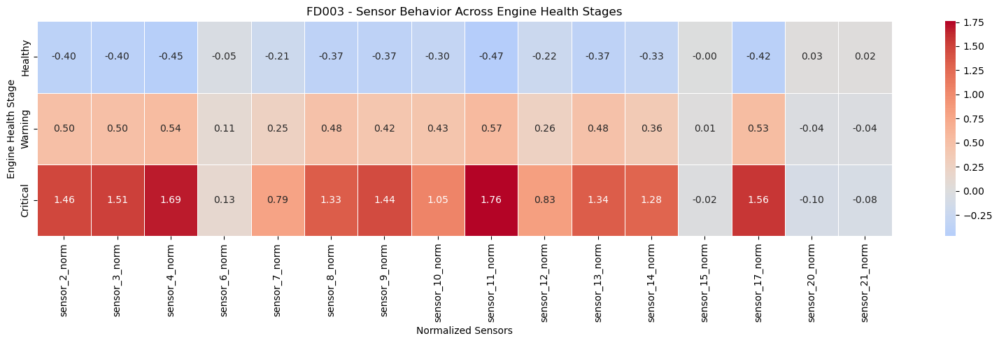

In [115]:
# ============================================================
# FD003 HEALTH-STAGE SENSOR HEATMAP
# ============================================================

plt.figure(figsize=(16, 5))

sns.heatmap(
    fd003_stage_sensor_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "FD003 - Sensor Behavior Across Engine Health Stages"
)

plt.xlabel("Normalized Sensors")
plt.ylabel("Engine Health Stage")

plt.tight_layout()
plt.show()

In [116]:
# ============================================================
# CALCULATE HEALTH-STAGE SEPARATION SCORE
# ============================================================

# FD002: difference between healthy and critical sensor means
fd002_stage_separation = (
    fd002_stage_sensor_means.loc["Critical"]
    -
    fd002_stage_sensor_means.loc["Healthy"]
).abs()

# Sort strongest stage-separating sensors first
fd002_stage_separation = (
    fd002_stage_separation
    .sort_values(ascending=False)
)


# FD003
fd003_stage_separation = (
    fd003_stage_sensor_means.loc["Critical"]
    -
    fd003_stage_sensor_means.loc["Healthy"]
).abs()

fd003_stage_separation = (
    fd003_stage_separation
    .sort_values(ascending=False)
)


print("FD002 Stage Separation:")
print(fd002_stage_separation)

print("\nFD003 Stage Separation:")
print(fd003_stage_separation)

FD002 Stage Separation:
sensor_11_norm    2.077419
sensor_4_norm     1.993306
sensor_15_norm    1.952117
sensor_17_norm    1.748180
sensor_2_norm     1.690499
sensor_3_norm     1.661815
sensor_12_norm    1.437122
sensor_7_norm     1.367494
sensor_13_norm    1.310926
sensor_8_norm     1.308900
sensor_20_norm    1.298267
sensor_21_norm    1.297059
sensor_9_norm     1.169852
sensor_6_norm     0.914621
sensor_14_norm    0.900283
sensor_10_norm    0.073237
dtype: float64

FD003 Stage Separation:
sensor_11_norm    2.226262
sensor_4_norm     2.132856
sensor_17_norm    1.985446
sensor_3_norm     1.912212
sensor_2_norm     1.860649
sensor_9_norm     1.817671
sensor_13_norm    1.705644
sensor_8_norm     1.701168
sensor_14_norm    1.603011
sensor_10_norm    1.354031
sensor_12_norm    1.049162
sensor_7_norm     0.994656
sensor_6_norm     0.184332
sensor_20_norm    0.128269
sensor_21_norm    0.100209
sensor_15_norm    0.016030
dtype: float64


In [117]:
# ============================================================
# COMPARE STAGE-SEPARATION STRENGTH ACROSS BOTH DATASETS
# ============================================================

stage_separation_comparison = pd.DataFrame({
    "FD002": fd002_stage_separation,
    "FD003": fd003_stage_separation
})

# Average stage-separation across FD002 and FD003
stage_separation_comparison["Average"] = (
    stage_separation_comparison["FD002"]
    +
    stage_separation_comparison["FD003"]
) / 2

# Sort strongest sensors first
stage_separation_comparison = (
    stage_separation_comparison
    .sort_values(
        "Average",
        ascending=False
    )
)

stage_separation_comparison

,FD002,FD003,Average
sensor_11_norm,2.077419,2.226262,2.151840
sensor_4_norm,1.993306,2.132856,2.063081
sensor_17_norm,1.748180,1.985446,1.866813
sensor_3_norm,1.661815,1.912212,1.787013
sensor_2_norm,1.690499,1.860649,1.775574
sensor_13_norm,1.310926,1.705644,1.508285
sensor_8_norm,1.308900,1.701168,1.505034
sensor_9_norm,1.169852,1.817671,1.493761
sensor_14_norm,0.900283,1.603011,1.251647
sensor_12_norm,1.437122,1.049162,1.243142


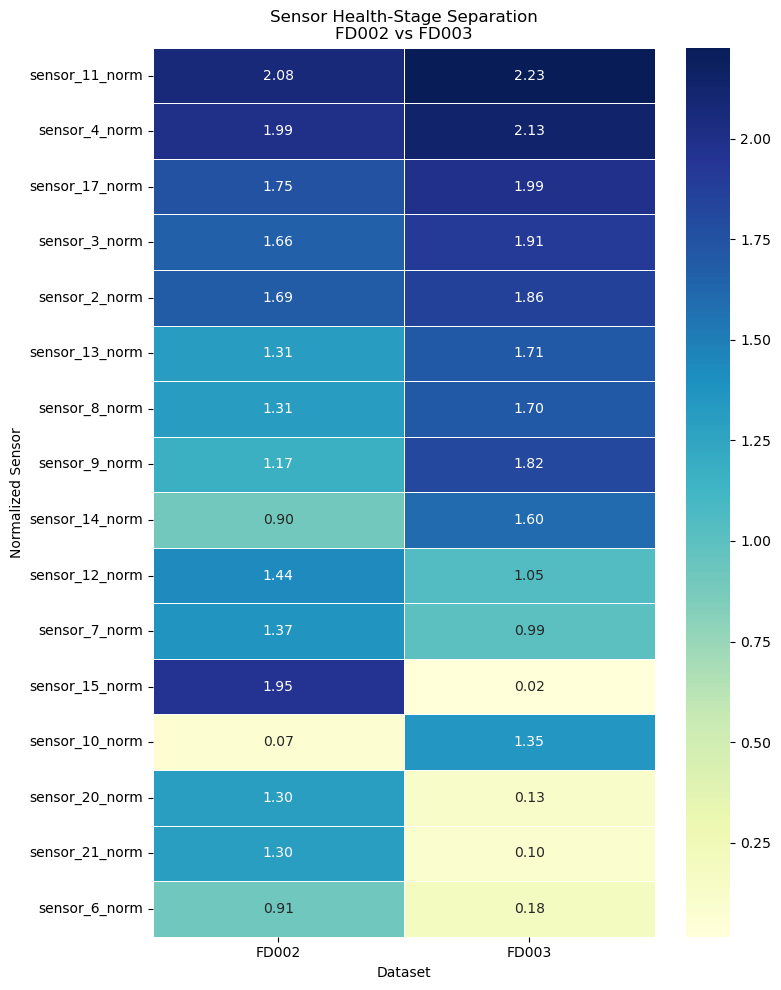

In [118]:
# ============================================================
# HEATMAP: HEALTH-STAGE SEPARATION ACROSS DATASETS
# ============================================================

plt.figure(figsize=(8, 10))

sns.heatmap(
    stage_separation_comparison[
        ["FD002", "FD003"]
    ],
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Sensor Health-Stage Separation\nFD002 vs FD003"
)

plt.xlabel("Dataset")
plt.ylabel("Normalized Sensor")

plt.tight_layout()
plt.show()

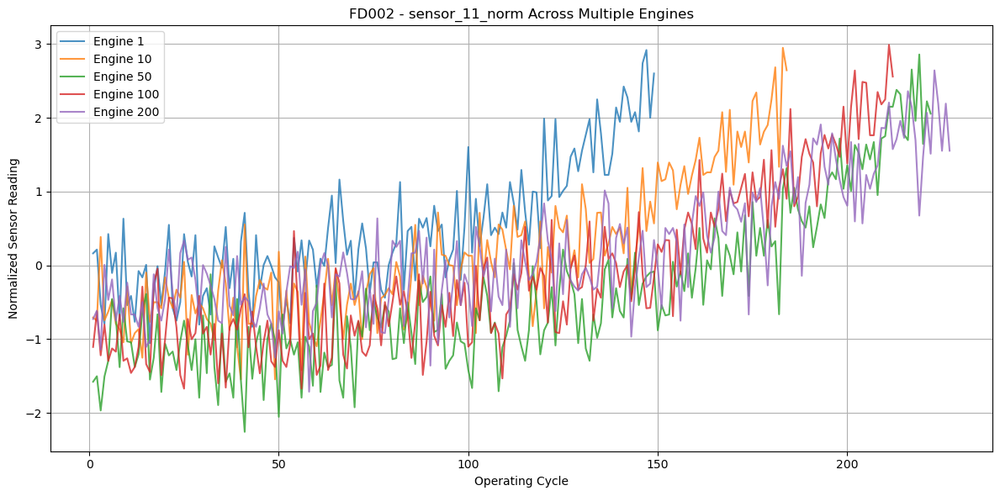

In [119]:
# ============================================================
# VISUALIZE SENSOR DEGRADATION ACROSS MULTIPLE ENGINES
# ============================================================

# Select some engines for visual inspection
selected_engines = [1, 10, 50, 100, 200]

sensor_to_plot = "sensor_11_norm"

plt.figure(figsize=(12, 6))

for engine_id in selected_engines:

    engine_data = train_fd002[
        train_fd002["engine_id"] == engine_id
    ]

    plt.plot(
        engine_data["cycle"],
        engine_data[sensor_to_plot],
        label=f"Engine {engine_id}",
        alpha=0.8
    )

plt.xlabel("Operating Cycle")
plt.ylabel("Normalized Sensor Reading")

plt.title(
    f"FD002 - {sensor_to_plot} Across Multiple Engines"
)

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [120]:
# ============================================================
# NORMALIZED ENGINE LIFE / DEGRADATION PERCENTAGE
# ============================================================

# Convert every engine's current cycle into a percentage
# of its complete observed training lifetime.
#
# 0%   ≈ beginning of life
# 50%  ≈ middle of life
# 100% = end of life / failure point

train_fd002["life_percentage"] = (
    train_fd002["cycle"]
    / train_fd002["max_cycle"]
) * 100

train_fd003["life_percentage"] = (
    train_fd003["cycle"]
    / train_fd003["max_cycle"]
) * 100

In [121]:
# ============================================================
# VALIDATE LIFE PERCENTAGE
# ============================================================

print("FD002 Life Percentage Range:")
print(
    train_fd002["life_percentage"].min(),
    "to",
    train_fd002["life_percentage"].max()
)

print("\nFD003 Life Percentage Range:")
print(
    train_fd003["life_percentage"].min(),
    "to",
    train_fd003["life_percentage"].max()
)

FD002 Life Percentage Range:
0.26455026455026454 to 100.0

FD003 Life Percentage Range:
0.19047619047619047 to 100.0


In [122]:
# ============================================================
# CHECK NORMALIZED LIFE FOR ENGINE 1
# ============================================================

train_fd002[
    train_fd002["engine_id"] == 1
][
    [
        "engine_id",
        "cycle",
        "max_cycle",
        "life_percentage"
    ]
].head(10)

,engine_id,cycle,max_cycle,life_percentage
0,1,1,149,0.671141
1,1,2,149,1.342282
2,1,3,149,2.013423
3,1,4,149,2.684564
4,1,5,149,3.355705
5,1,6,149,4.026846
6,1,7,149,4.697987
7,1,8,149,5.369128
8,1,9,149,6.040268
9,1,10,149,6.711409


In [123]:
train_fd002[
    train_fd002["engine_id"] == 1
][
    [
        "engine_id",
        "cycle",
        "max_cycle",
        "life_percentage"
    ]
].tail(10)

,engine_id,cycle,max_cycle,life_percentage
139,1,140,149,93.959732
140,1,141,149,94.630872
141,1,142,149,95.302013
142,1,143,149,95.973154
143,1,144,149,96.644295
144,1,145,149,97.315436
145,1,146,149,97.986577
146,1,147,149,98.657718
147,1,148,149,99.328859
148,1,149,149,100.000000


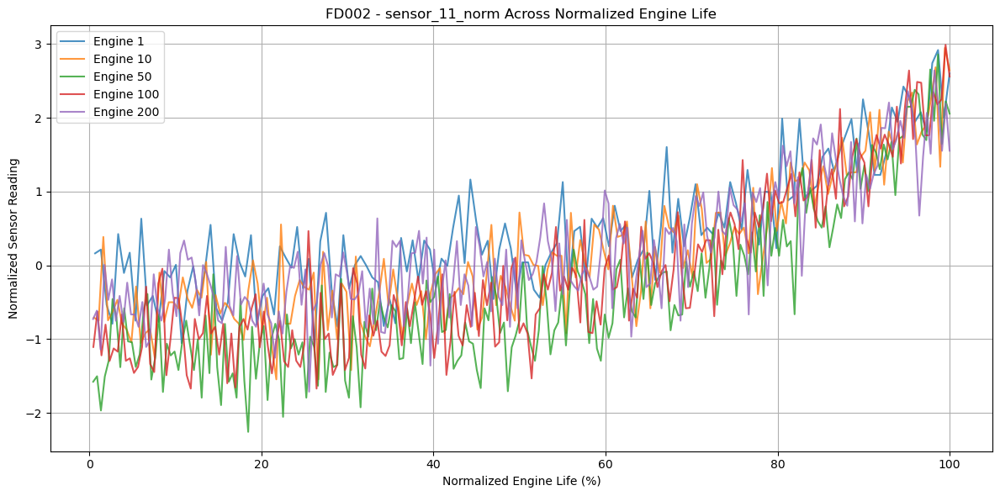

In [124]:
# ============================================================
# SENSOR 11 ACROSS MULTIPLE ENGINES
# USING NORMALIZED ENGINE LIFE
# ============================================================

selected_engines = [1, 10, 50, 100, 200]

sensor_to_plot = "sensor_11_norm"

plt.figure(figsize=(12, 6))

for engine_id in selected_engines:

    # Select one engine's complete lifecycle
    engine_data = train_fd002[
        train_fd002["engine_id"] == engine_id
    ]

    # Plot sensor behavior against relative engine lifetime
    plt.plot(
        engine_data["life_percentage"],
        engine_data[sensor_to_plot],
        label=f"Engine {engine_id}",
        alpha=0.8
    )

plt.xlabel("Normalized Engine Life (%)")
plt.ylabel("Normalized Sensor Reading")

plt.title(
    f"FD002 - {sensor_to_plot} Across Normalized Engine Life"
)

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [125]:
# ============================================================
# CREATE COMMON ENGINE-LIFE BINS
# ============================================================

life_bins = [0, 20, 40, 60, 80, 100]

life_labels = [
    "0-20%",
    "20-40%",
    "40-60%",
    "60-80%",
    "80-100%"
]

# FD002
train_fd002["life_bin"] = pd.cut(
    train_fd002["life_percentage"],
    bins=life_bins,
    labels=life_labels,
    include_lowest=True
)

# FD003
train_fd003["life_bin"] = pd.cut(
    train_fd003["life_percentage"],
    bins=life_bins,
    labels=life_labels,
    include_lowest=True
)

In [126]:
# ============================================================
# CHECK NUMBER OF OBSERVATIONS PER LIFE BIN
# ============================================================

print("FD002 Life Bins:")
print(
    train_fd002["life_bin"]
    .value_counts()
    .sort_index()
)

print("\nFD003 Life Bins:")
print(
    train_fd003["life_bin"]
    .value_counts()
    .sort_index()
)

FD002 Life Bins:
life_bin
0-20%      10638
20-40%     10758
40-60%     10751
60-80%     10758
80-100%    10854
Name: count, dtype: int64

FD003 Life Bins:
life_bin
0-20%      4906
20-40%     4942
40-60%     4945
60-80%     4942
80-100%    4985
Name: count, dtype: int64


In [127]:
# ============================================================
# SENSOR 11 MEAN ACROSS ENGINE LIFE STAGES
# ============================================================

fd002_sensor11_life_trend = (
    train_fd002
    .groupby(
        "life_bin",
        observed=True
    )["sensor_11_norm"]
    .mean()
)

print(fd002_sensor11_life_trend)

life_bin
0-20%     -0.709816
20-40%    -0.582204
40-60%    -0.317951
60-80%     0.213127
80-100%    1.376437
Name: sensor_11_norm, dtype: float64


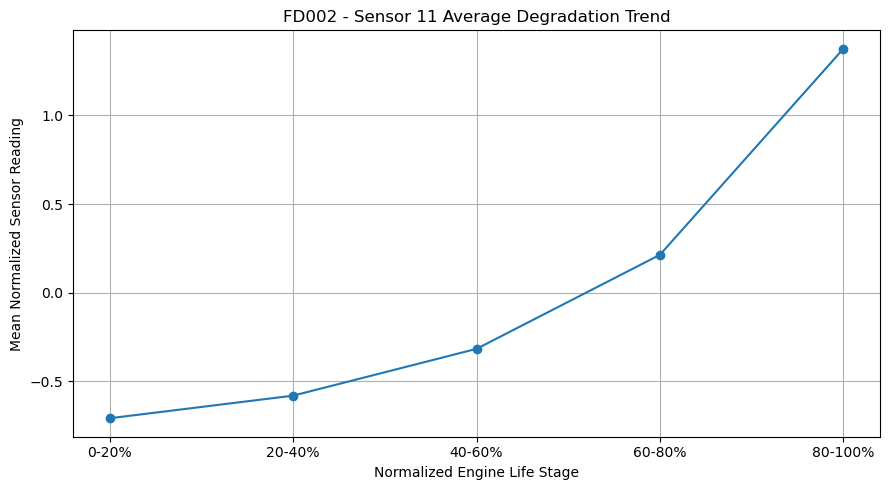

In [128]:
# ============================================================
# SENSOR 11 AVERAGE DEGRADATION TREND
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    fd002_sensor11_life_trend.index.astype(str),
    fd002_sensor11_life_trend.values,
    marker="o"
)

plt.xlabel("Normalized Engine Life Stage")
plt.ylabel("Mean Normalized Sensor Reading")

plt.title(
    "FD002 - Sensor 11 Average Degradation Trend"
)

plt.grid()
plt.tight_layout()
plt.show()

In [129]:
# ============================================================
# MEAN SENSOR BEHAVIOR ACROSS NORMALIZED LIFE STAGES
# ============================================================

fd002_life_stage_means = (
    train_fd002
    .groupby(
        "life_bin",
        observed=True
    )[norm_sensor_cols]
    .mean()
)

fd003_life_stage_means = (
    train_fd003
    .groupby(
        "life_bin",
        observed=True
    )[norm_sensor_cols]
    .mean()
)

fd002_life_stage_means

,sensor_2_norm,sensor_3_norm,sensor_4_norm,sensor_6_norm,sensor_7_norm,sensor_8_norm,sensor_9_norm,sensor_10_norm,sensor_11_norm,sensor_12_norm,sensor_13_norm,sensor_14_norm,sensor_15_norm,sensor_17_norm,sensor_20_norm,sensor_21_norm
life_bin,,,,,,,,,,,,,,,,
0-20%,-0.592786,-0.575413,-0.684733,-0.396167,0.467751,-0.445538,-0.402360,0.041145,-0.709816,0.500024,-0.447833,-0.309848,-0.667893,-0.605661,0.452547,0.442182
20-40%,-0.481394,-0.469775,-0.552556,-0.303445,0.385338,-0.375711,-0.346368,0.035106,-0.582204,0.399360,-0.376509,-0.268026,-0.548938,-0.485589,0.360207,0.376955
40-60%,-0.254440,-0.256275,-0.309336,-0.116690,0.209651,-0.221277,-0.211109,0.004175,-0.317951,0.209018,-0.218719,-0.174138,-0.295205,-0.277217,0.215335,0.181115
60-80%,0.184548,0.174297,0.201633,0.183936,-0.153181,0.115408,0.088379,-0.039697,0.213127,-0.147442,0.113730,0.056861,0.200715,0.184812,-0.151058,-0.125861
80-100%,1.127235,1.110670,1.325326,0.622318,-0.896208,0.913850,0.859167,-0.039912,1.376437,-0.946798,0.916019,0.685466,1.292148,1.166311,-0.864132,-0.861652


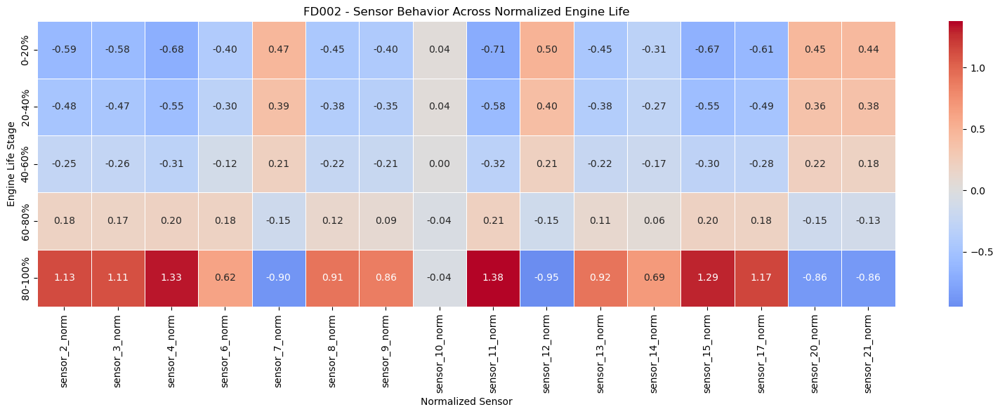

In [130]:
# ============================================================
# FD002 TEMPORAL DEGRADATION HEATMAP
# ============================================================

plt.figure(figsize=(16, 6))

sns.heatmap(
    fd002_life_stage_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "FD002 - Sensor Behavior Across Normalized Engine Life"
)

plt.xlabel("Normalized Sensor")
plt.ylabel("Engine Life Stage")

plt.tight_layout()
plt.show()

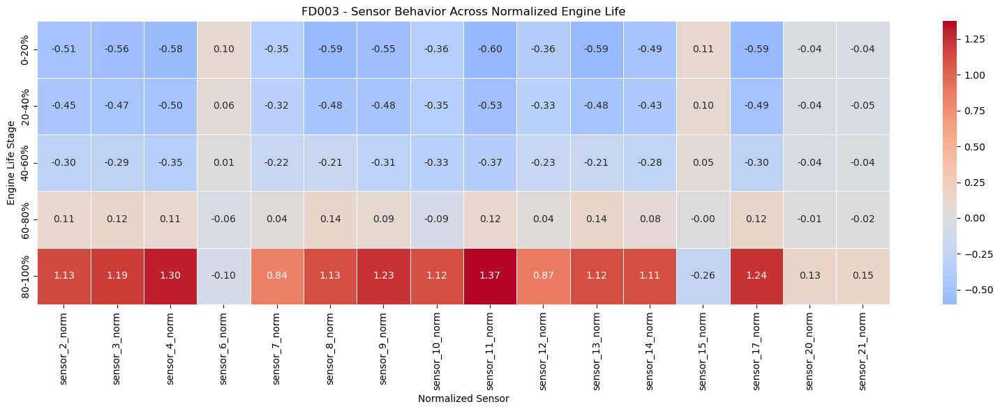

In [131]:
# ============================================================
# FD003 TEMPORAL DEGRADATION HEATMAP
# ============================================================

plt.figure(figsize=(16, 6))

sns.heatmap(
    fd003_life_stage_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "FD003 - Sensor Behavior Across Normalized Engine Life"
)

plt.xlabel("Normalized Sensor")
plt.ylabel("Engine Life Stage")

plt.tight_layout()
plt.show()

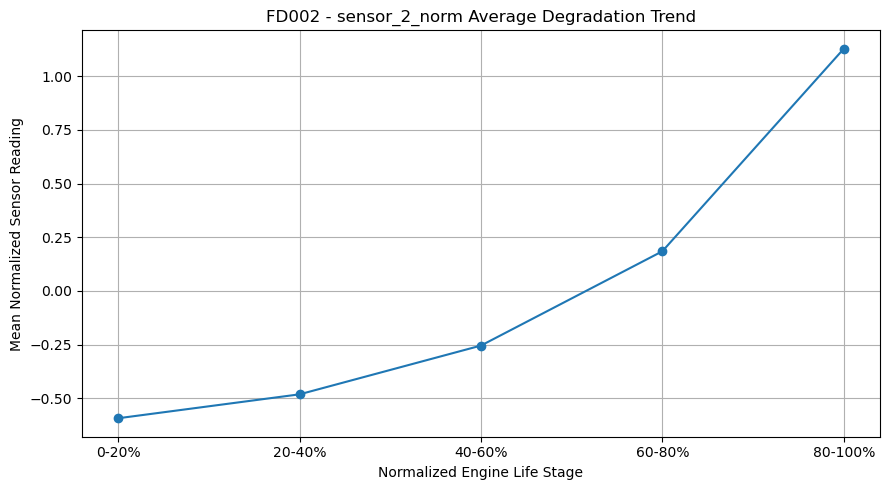

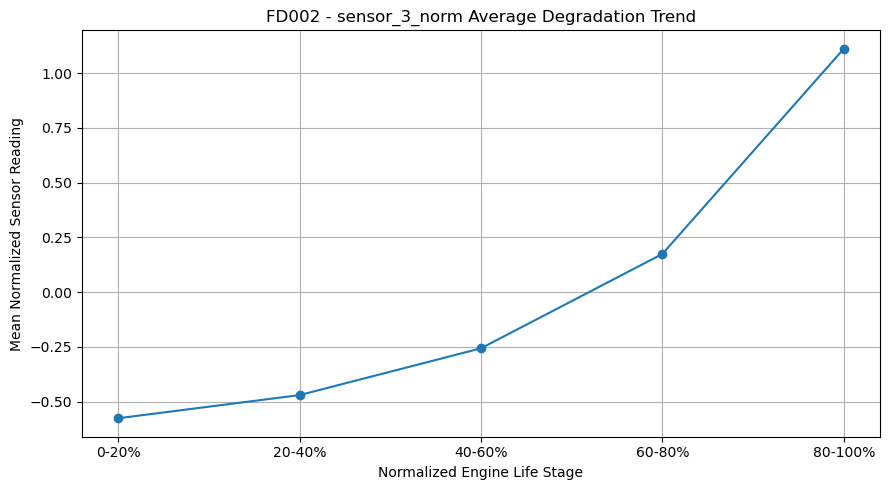

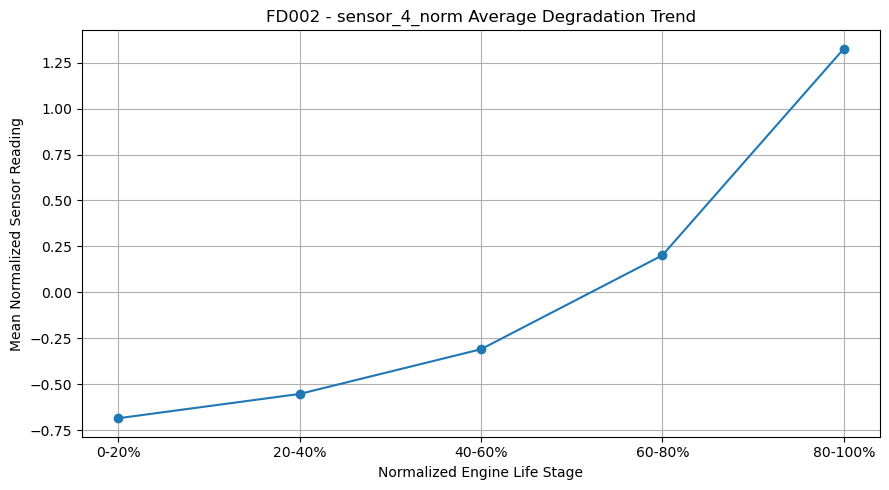

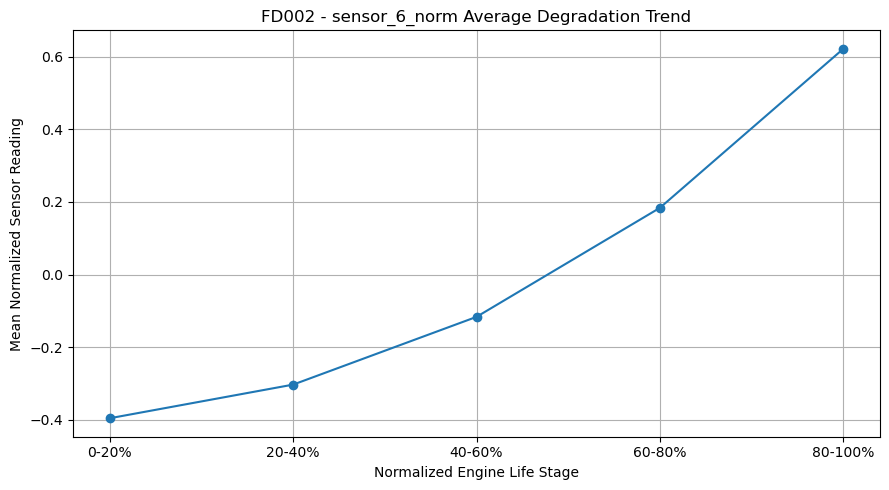

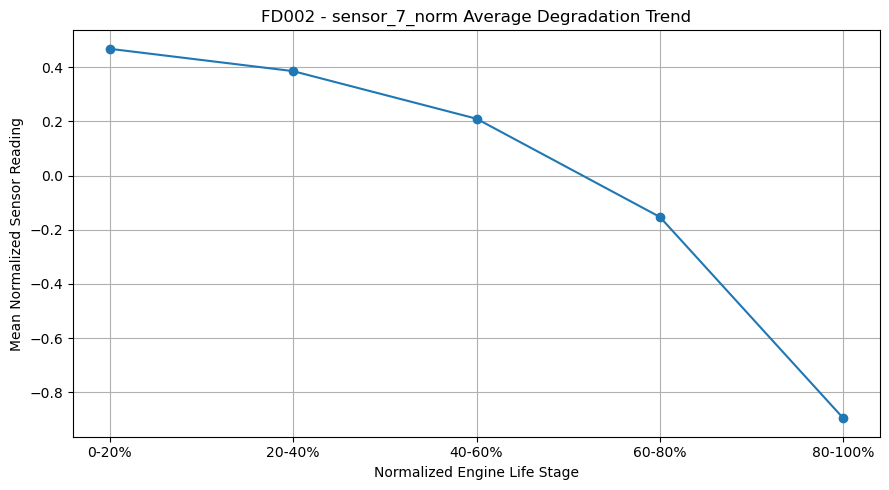

...

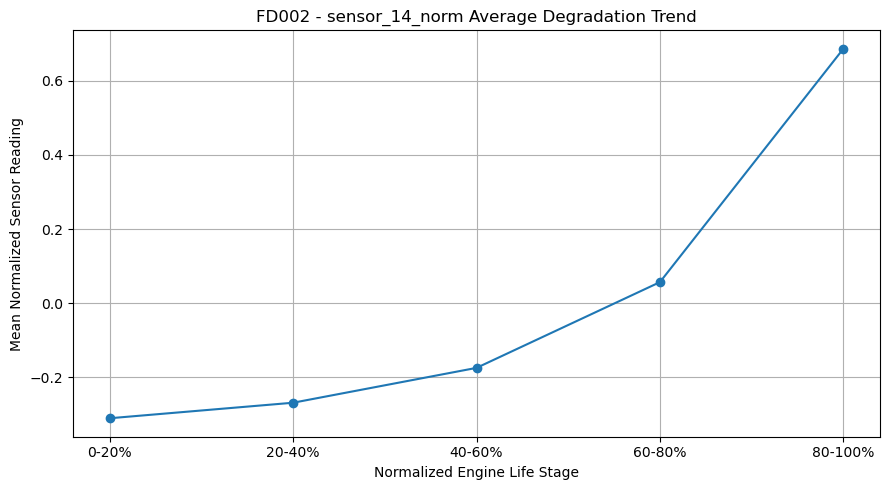

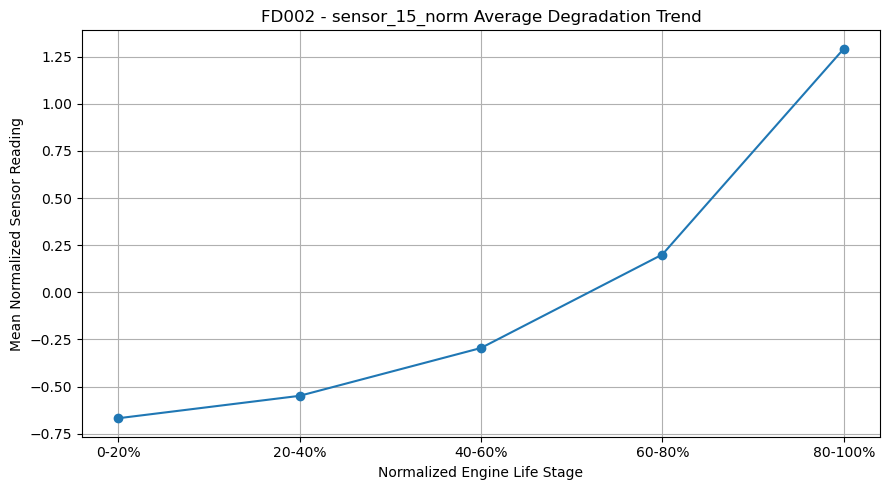

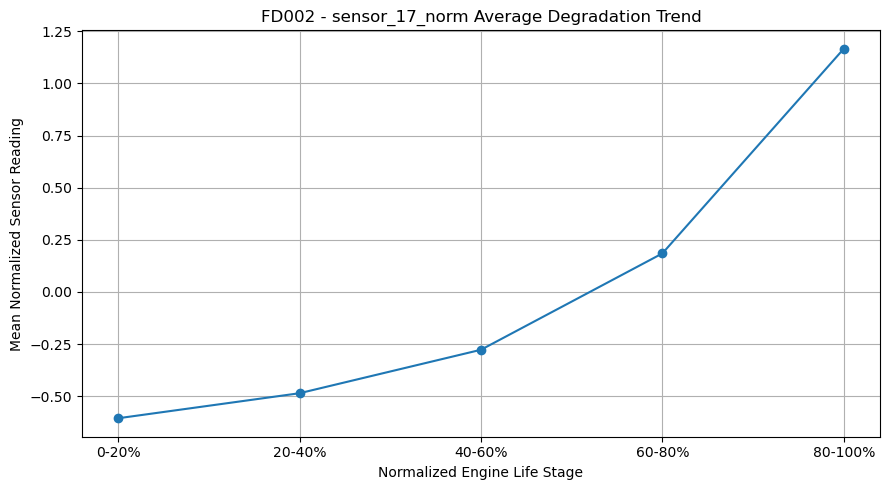

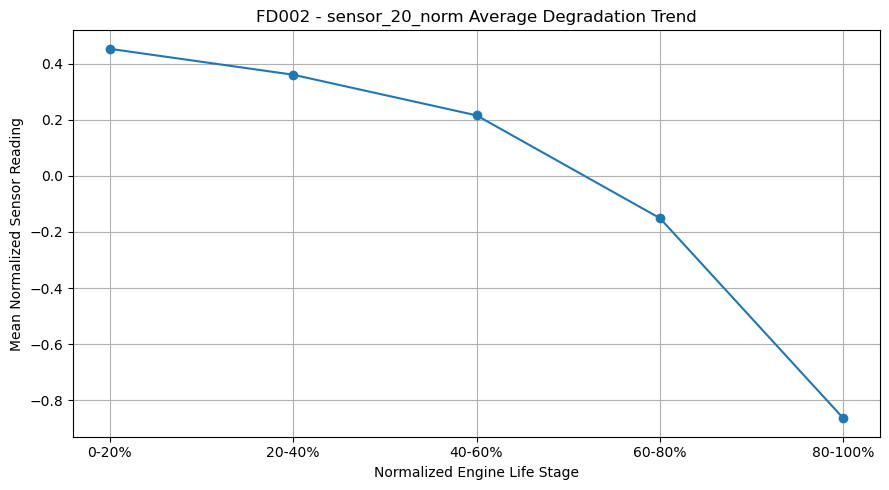

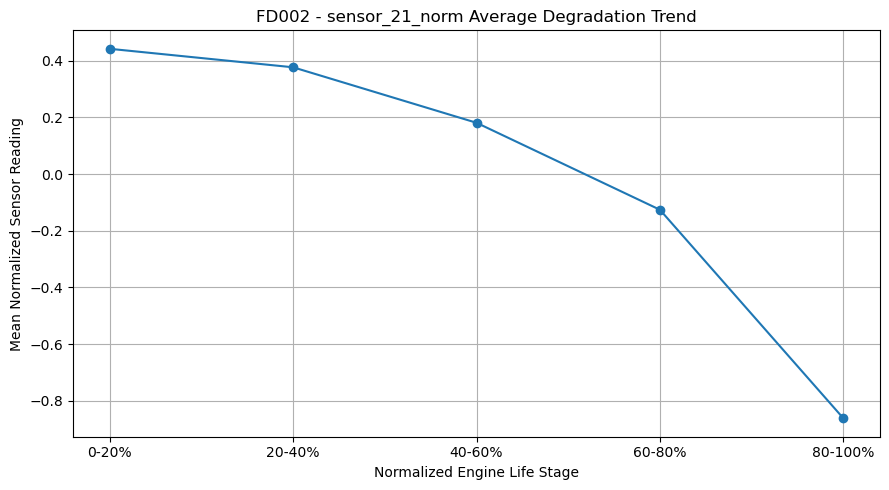

In [132]:
# ============================================================
# PLOT TEMPORAL DEGRADATION TREND FOR ALL CANDIDATE SENSORS
# ============================================================
# Purpose:
# For every candidate sensor, calculate its average reading
# at different stages of engine life and visualize the trend.
#
# This helps us identify sensors that change systematically
# as the engine moves from early life toward failure.
# ============================================================

for sensor in norm_sensor_cols:

    # Calculate mean sensor reading for each normalized-life bin
    fd002_sensor_trend = (
        train_fd002
        .groupby(
            "life_bin",
            observed=True
        )[sensor]
        .mean()
    )

    # Create a separate figure for each sensor
    plt.figure(figsize=(9, 5))

    # Plot average sensor reading across engine-life stages
    plt.plot(
        fd002_sensor_trend.index.astype(str),
        fd002_sensor_trend.values,
        marker="o"
    )

    # Axis labels
    plt.xlabel("Normalized Engine Life Stage")
    plt.ylabel("Mean Normalized Sensor Reading")

    # Dynamic title for each sensor
    plt.title(
        f"FD002 - {sensor} Average Degradation Trend"
    )

    # Grid makes the trend easier to read
    plt.grid()

    # Prevent labels from overlapping
    plt.tight_layout()

    plt.show()

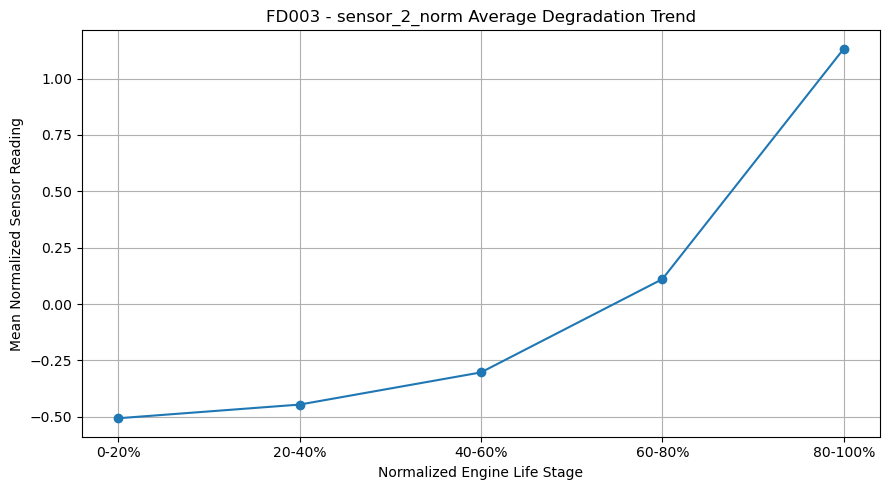

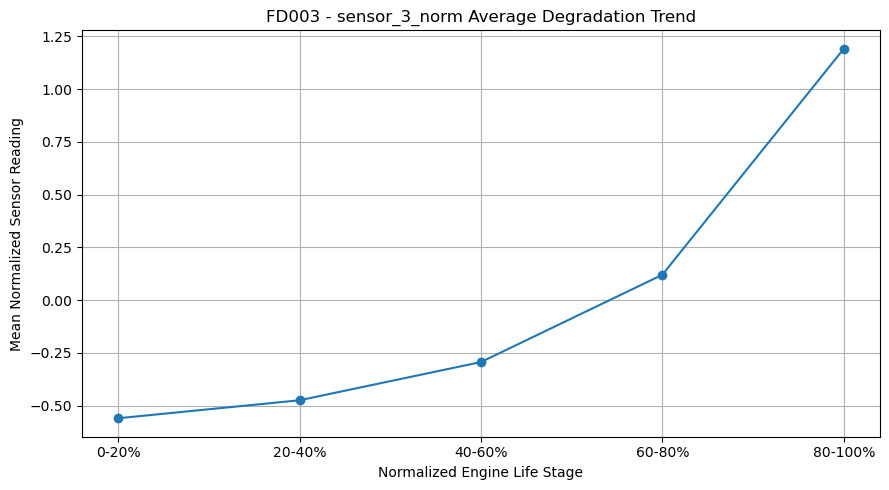

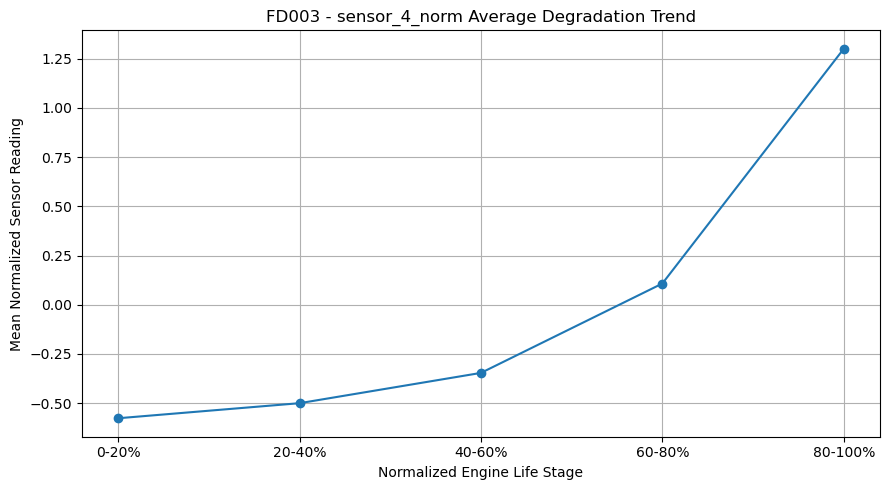

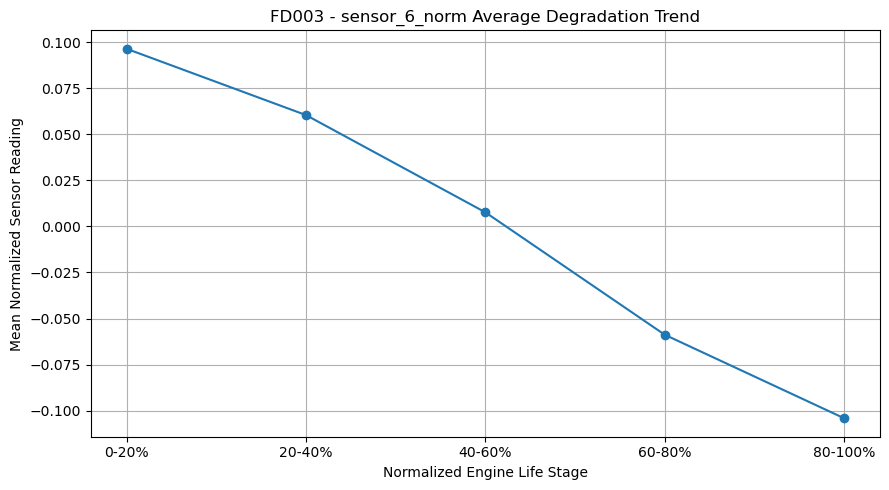

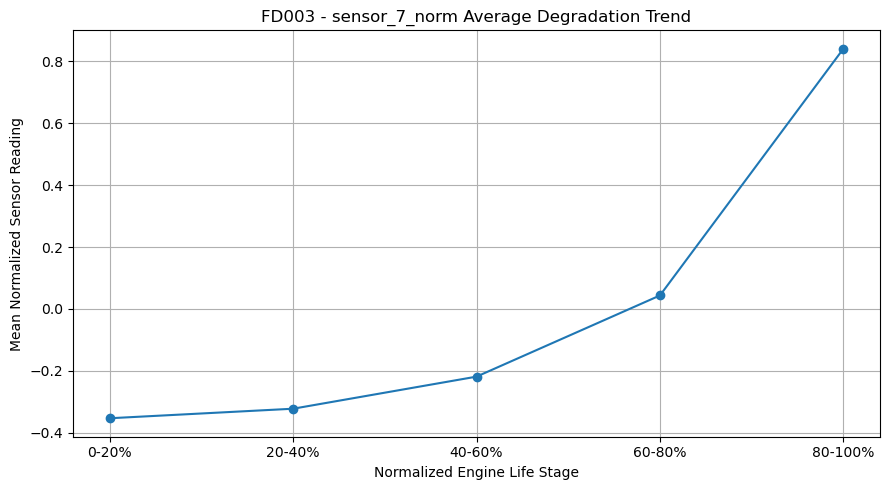

...

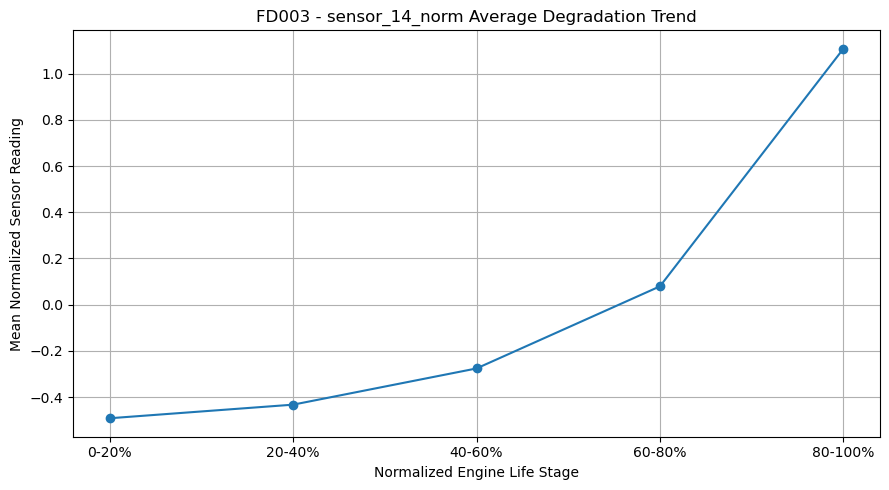

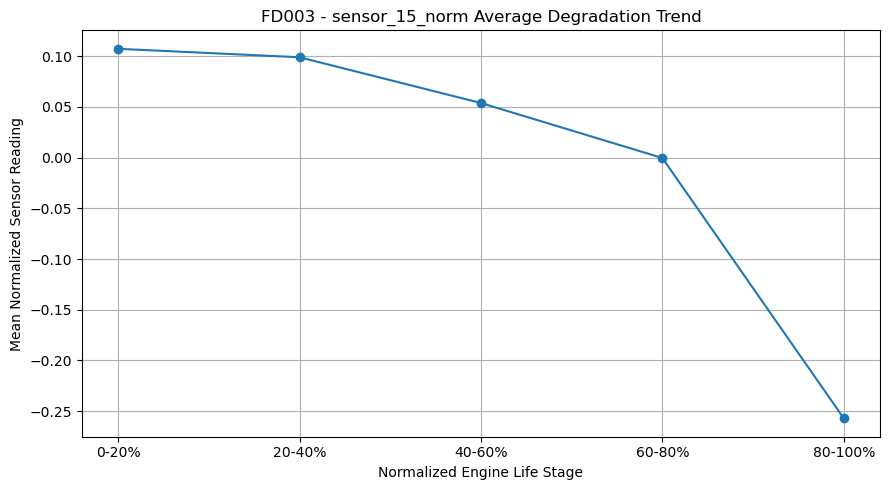

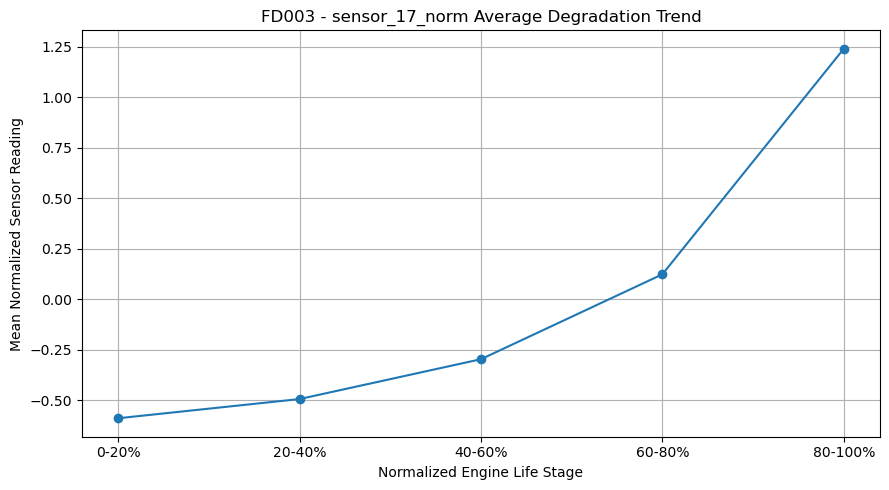

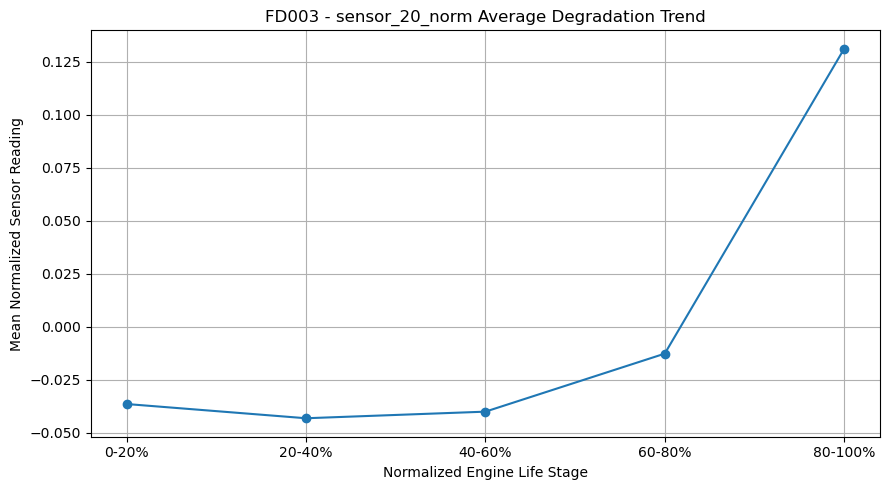

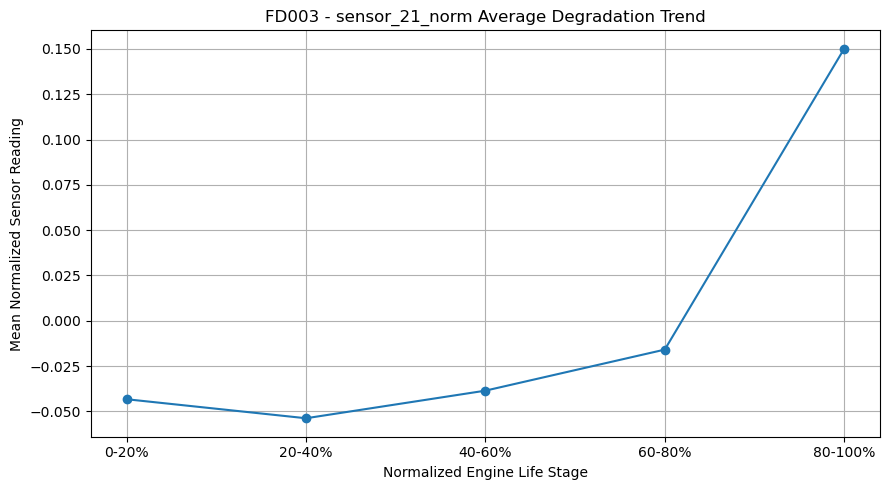

In [133]:
# ============================================================
# FD003 - TEMPORAL DEGRADATION TREND FOR ALL CANDIDATE SENSORS
# ============================================================

for sensor in norm_sensor_cols:

    # Calculate mean sensor value at each life stage
    fd003_sensor_trend = (
        train_fd003
        .groupby(
            "life_bin",
            observed=True
        )[sensor]
        .mean()
    )

    # Create separate plot for each sensor
    plt.figure(figsize=(9, 5))

    plt.plot(
        fd003_sensor_trend.index.astype(str),
        fd003_sensor_trend.values,
        marker="o"
    )

    plt.xlabel("Normalized Engine Life Stage")
    plt.ylabel("Mean Normalized Sensor Reading")

    plt.title(
        f"FD003 - {sensor} Average Degradation Trend"
    )

    plt.grid()
    plt.tight_layout()

    plt.show()

In [134]:
# ============================================================
# TEMPORAL DEGRADATION TREND STRENGTH
# ============================================================
# Purpose:
# Measure whether each sensor systematically changes as the
# engine moves from beginning-of-life toward failure.
#
# IMPORTANT:
# life_percentage is used ONLY for EDA / feature analysis.
# It must NOT be given to the predictive model because it uses
# max_cycle, which contains future failure information.
# ============================================================

# FD002: Spearman correlation between each sensor
# and normalized engine life percentage
fd002_temporal_corr = (
    train_fd002[
        norm_sensor_cols + ["life_percentage"]
    ]
    .corr(method="spearman")["life_percentage"]
    .drop("life_percentage")
)

# FD003: same temporal analysis
fd003_temporal_corr = (
    train_fd003[
        norm_sensor_cols + ["life_percentage"]
    ]
    .corr(method="spearman")["life_percentage"]
    .drop("life_percentage")
)

# Combine both datasets for comparison
temporal_trend_comparison = pd.DataFrame({
    "FD002_Temporal": fd002_temporal_corr,
    "FD003_Temporal": fd003_temporal_corr
})

# Absolute correlation represents trend strength.
# Sign only tells whether sensor rises or falls with degradation.
temporal_trend_comparison["Average_Temporal_Strength"] = (
    temporal_trend_comparison["FD002_Temporal"].abs()
    + temporal_trend_comparison["FD003_Temporal"].abs()
) / 2

# Strongest temporal sensors first
temporal_trend_comparison = (
    temporal_trend_comparison
    .sort_values(
        "Average_Temporal_Strength",
        ascending=False
    )
)

temporal_trend_comparison

,FD002_Temporal,FD003_Temporal,Average_Temporal_Strength
sensor_11_norm,0.710009,0.645717,0.677863
sensor_4_norm,0.682282,0.611726,0.647004
sensor_17_norm,0.603156,0.608429,0.605793
sensor_3_norm,0.576348,0.584842,0.580595
sensor_2_norm,0.589572,0.543220,0.566396
sensor_13_norm,0.420413,0.657237,0.538825
sensor_8_norm,0.419555,0.656574,0.538065
sensor_9_norm,0.357798,0.583943,0.470871
sensor_15_norm,0.667424,-0.080681,0.374053
sensor_14_norm,0.229902,0.513669,0.371785


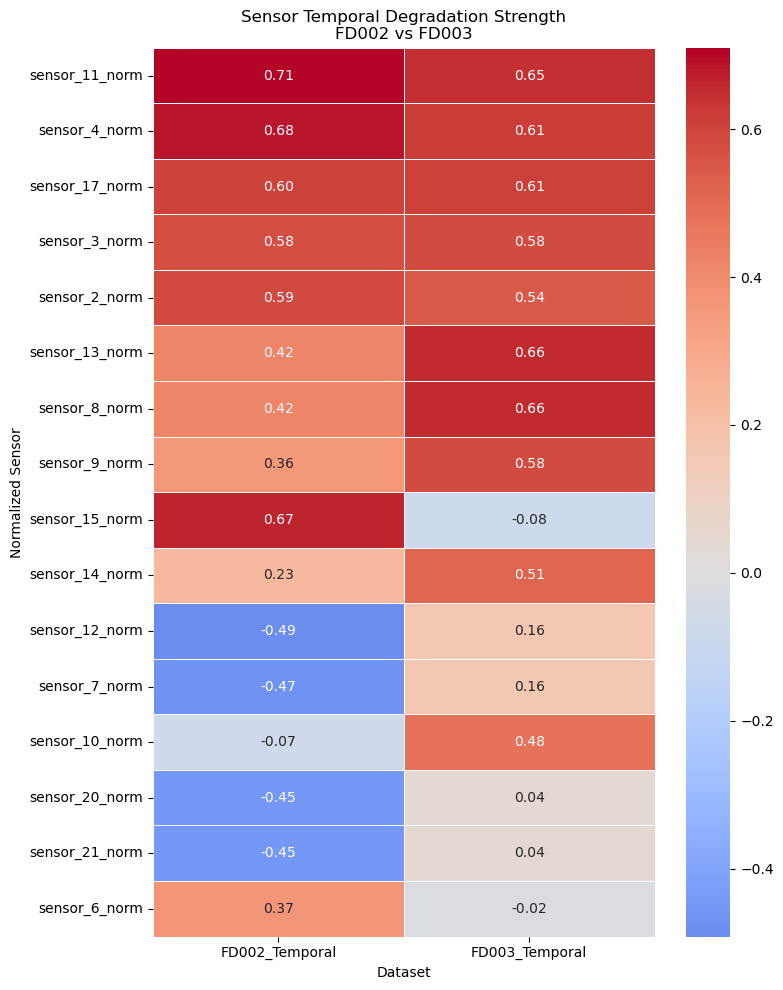

In [135]:
# ============================================================
# TEMPORAL TREND HEATMAP
# ============================================================

plt.figure(figsize=(8, 10))

sns.heatmap(
    temporal_trend_comparison[
        ["FD002_Temporal", "FD003_Temporal"]
    ],
    annot=True,          # Show numerical values
    fmt=".2f",           # Two decimal places
    cmap="coolwarm",     # Positive vs negative trend
    center=0,
    linewidths=0.5
)

plt.title(
    "Sensor Temporal Degradation Strength\nFD002 vs FD003"
)

plt.xlabel("Dataset")
plt.ylabel("Normalized Sensor")

plt.tight_layout()
plt.show()

In [136]:
# ============================================================
# BUILD COMPLETE SENSOR EVIDENCE TABLE
# ============================================================
# Each row = one candidate sensor
# Each column = one independent piece of evidence
# ============================================================

feature_evidence = pd.DataFrame(index=norm_sensor_cols)

# -------------------------
# Pearson RUL relationship
# -------------------------
feature_evidence["FD002_Pearson"] = (
    fd002_rul_corr.reindex(norm_sensor_cols)
)

feature_evidence["FD003_Pearson"] = (
    fd003_rul_corr.reindex(norm_sensor_cols)
)

# -------------------------
# Spearman RUL relationship
# -------------------------
feature_evidence["FD002_Spearman"] = (
    fd002_spearman_corr.reindex(norm_sensor_cols)
)

feature_evidence["FD003_Spearman"] = (
    fd003_spearman_corr.reindex(norm_sensor_cols)
)

# -------------------------
# Healthy vs Critical separation
# -------------------------
feature_evidence["FD002_Stage_Separation"] = (
    fd002_stage_separation.reindex(norm_sensor_cols)
)

feature_evidence["FD003_Stage_Separation"] = (
    fd003_stage_separation.reindex(norm_sensor_cols)
)

# -------------------------
# Temporal degradation trend
# -------------------------
feature_evidence["FD002_Temporal"] = (
    fd002_temporal_corr.reindex(norm_sensor_cols)
)

feature_evidence["FD003_Temporal"] = (
    fd003_temporal_corr.reindex(norm_sensor_cols)
)

feature_evidence

,FD002_Pearson,FD003_Pearson,FD002_Spearman,FD003_Spearman,FD002_Stage_Separation,FD003_Stage_Separation,FD002_Temporal,FD003_Temporal
sensor_2_norm,-0.630409,-0.681722,-0.591529,-0.636479,1.690499,1.860649,0.589572,0.543220
sensor_3_norm,-0.618035,-0.696364,-0.577793,-0.654640,1.661815,1.912212,0.576348,0.584842
sensor_4_norm,-0.737635,-0.770051,-0.684934,-0.708766,1.993306,2.132856,0.682282,0.611726
sensor_6_norm,-0.362654,-0.096395,-0.357926,-0.180895,0.914621,0.184332,0.370882,-0.020818
sensor_7_norm,0.509541,-0.356735,0.476816,-0.043719,1.367494,0.994656,-0.469757,0.156376
sensor_8_norm,-0.475319,-0.634102,-0.384773,-0.713620,1.308900,1.701168,0.419555,0.656574
sensor_9_norm,-0.422450,-0.643791,-0.292481,-0.565148,1.169852,1.817671,0.357798,0.583943
sensor_10_norm,0.038181,-0.494808,0.071912,-0.454520,0.073237,1.354031,-0.071081,0.475743
sensor_11_norm,-0.770679,-0.804532,-0.715043,-0.738877,2.077419,2.226262,0.710009,0.645717
sensor_12_norm,0.534934,-0.374957,0.499377,-0.053771,1.437122,1.049162,-0.491807,0.162871


In [137]:
# ============================================================
# CROSS-DATASET CONSISTENCY
# ============================================================

# Difference in absolute Pearson strength across datasets.
# Smaller difference means more consistent behavior.
feature_evidence["Pearson_Difference"] = (
    feature_evidence["FD002_Pearson"].abs()
    -
    feature_evidence["FD003_Pearson"].abs()
).abs()

# Difference in Spearman strength
feature_evidence["Spearman_Difference"] = (
    feature_evidence["FD002_Spearman"].abs()
    -
    feature_evidence["FD003_Spearman"].abs()
).abs()

# Lower value = more consistent sensor across FD002/FD003
feature_evidence[
    [
        "Pearson_Difference",
        "Spearman_Difference"
    ]
].sort_values("Pearson_Difference")

,Pearson_Difference,Spearman_Difference
sensor_4_norm,0.032416,0.023832
sensor_11_norm,0.033853,0.023835
sensor_2_norm,0.051312,0.044950
sensor_17_norm,0.076995,0.077357
sensor_3_norm,0.078330,0.076848
sensor_7_norm,0.152806,0.433096
sensor_13_norm,0.158153,0.330182
sensor_8_norm,0.158783,0.328846
sensor_12_norm,0.159977,0.445606
sensor_9_norm,0.221341,0.272667


In [138]:
# ============================================================
# AVERAGE FEATURE STRENGTH ACROSS BOTH DATASETS
# ============================================================

# Average absolute Pearson correlation
feature_evidence["Avg_Pearson_Strength"] = (
    feature_evidence["FD002_Pearson"].abs()
    +
    feature_evidence["FD003_Pearson"].abs()
) / 2

# Average absolute Spearman correlation
feature_evidence["Avg_Spearman_Strength"] = (
    feature_evidence["FD002_Spearman"].abs()
    +
    feature_evidence["FD003_Spearman"].abs()
) / 2

# Average healthy-critical separation
feature_evidence["Avg_Stage_Separation"] = (
    feature_evidence["FD002_Stage_Separation"]
    +
    feature_evidence["FD003_Stage_Separation"]
) / 2

# Average temporal degradation strength
feature_evidence["Avg_Temporal_Strength"] = (
    feature_evidence["FD002_Temporal"].abs()
    +
    feature_evidence["FD003_Temporal"].abs()
) / 2

In [139]:
# ============================================================
# RANK SENSORS USING MULTIPLE PIECES OF EVIDENCE
# ============================================================

# Rank 1 means strongest sensor for that criterion.

feature_evidence["Pearson_Rank"] = (
    feature_evidence["Avg_Pearson_Strength"]
    .rank(
        ascending=False,
        method="average"
    )
)

feature_evidence["Spearman_Rank"] = (
    feature_evidence["Avg_Spearman_Strength"]
    .rank(
        ascending=False,
        method="average"
    )
)

feature_evidence["Stage_Rank"] = (
    feature_evidence["Avg_Stage_Separation"]
    .rank(
        ascending=False,
        method="average"
    )
)

feature_evidence["Temporal_Rank"] = (
    feature_evidence["Avg_Temporal_Strength"]
    .rank(
        ascending=False,
        method="average"
    )
)

# Average all statistical/temporal ranks
feature_evidence["Preliminary_Average_Rank"] = (
    feature_evidence[
        [
            "Pearson_Rank",
            "Spearman_Rank",
            "Stage_Rank",
            "Temporal_Rank"
        ]
    ]
    .mean(axis=1)
)

# Lower rank = stronger overall preliminary sensor
preliminary_sensor_ranking = (
    feature_evidence
    .sort_values(
        "Preliminary_Average_Rank"
    )
)

preliminary_sensor_ranking[
    [
        "Avg_Pearson_Strength",
        "Avg_Spearman_Strength",
        "Avg_Stage_Separation",
        "Avg_Temporal_Strength",
        "Preliminary_Average_Rank"
    ]
]

,Avg_Pearson_Strength,Avg_Spearman_Strength,Avg_Stage_Separation,Avg_Temporal_Strength,Preliminary_Average_Rank
sensor_11_norm,0.787606,0.726960,2.151840,0.677863,1.00
sensor_4_norm,0.753843,0.696850,2.063081,0.647004,2.00
sensor_17_norm,0.687253,0.641648,1.866813,0.605793,3.00
sensor_3_norm,0.657200,0.616217,1.787013,0.580595,4.00
sensor_2_norm,0.656066,0.614004,1.775574,0.566396,5.00
sensor_13_norm,0.555488,0.549994,1.508285,0.538825,6.00
sensor_8_norm,0.554711,0.549196,1.505034,0.538065,7.00
sensor_9_norm,0.533121,0.428815,1.493761,0.470871,8.00
sensor_14_norm,0.442604,0.316690,1.251647,0.371785,9.75
sensor_12_norm,0.454945,0.276574,1.243142,0.327339,10.25


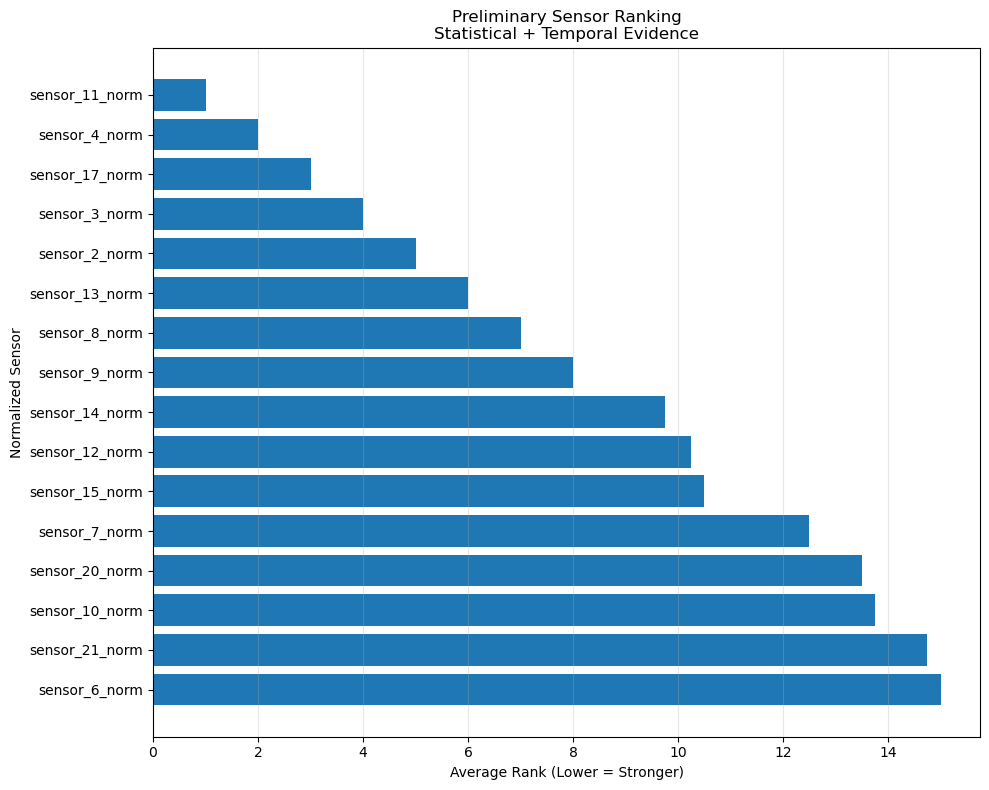

In [140]:
# ============================================================
# PRELIMINARY SENSOR RANKING BAR CHART
# ============================================================

# Extract the final preliminary rank
ranking_plot = (
    preliminary_sensor_ranking[
        "Preliminary_Average_Rank"
    ]
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 8))

# Horizontal bar chart makes sensor names easier to read
plt.barh(
    ranking_plot.index,
    ranking_plot.values
)

# Best rank should appear at the top
plt.gca().invert_yaxis()

plt.xlabel(
    "Average Rank (Lower = Stronger)"
)

plt.ylabel(
    "Normalized Sensor"
)

plt.title(
    "Preliminary Sensor Ranking\n"
    "Statistical + Temporal Evidence"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [141]:
# ============================================================
# ENGINE-WISE TRAIN / VALIDATION SPLIT - FD002
# ============================================================
# Purpose:
# Split complete engines instead of random rows.
#
# This prevents data leakage because all cycles of one engine
# remain entirely inside either training or validation data.
# ============================================================

from sklearn.model_selection import train_test_split

# Get unique engine IDs from FD002 training dataset
fd002_engine_ids = train_fd002["engine_id"].unique()

# Split engine IDs: 80% training engines, 20% validation engines
fd002_train_engines, fd002_val_engines = train_test_split(
    fd002_engine_ids,
    test_size=0.20,
    random_state=42
)

# Create training subset using complete engines
fd002_train = train_fd002[
    train_fd002["engine_id"].isin(fd002_train_engines)
].copy()

# Create validation subset using completely different engines
fd002_val = train_fd002[
    train_fd002["engine_id"].isin(fd002_val_engines)
].copy()

print("FD002 Training Engines:", fd002_train["engine_id"].nunique())
print("FD002 Validation Engines:", fd002_val["engine_id"].nunique())

print("FD002 Training Rows:", len(fd002_train))
print("FD002 Validation Rows:", len(fd002_val))

FD002 Training Engines: 208
FD002 Validation Engines: 52
FD002 Training Rows: 43464
FD002 Validation Rows: 10295


In [142]:
# ============================================================
# ENGINE-WISE TRAIN / VALIDATION SPLIT - FD003
# ============================================================

# Get unique FD003 engine IDs
fd003_engine_ids = train_fd003["engine_id"].unique()

# Split complete engines into training and validation groups
fd003_train_engines, fd003_val_engines = train_test_split(
    fd003_engine_ids,
    test_size=0.20,
    random_state=42
)

# Create training dataset
fd003_train = train_fd003[
    train_fd003["engine_id"].isin(fd003_train_engines)
].copy()

# Create validation dataset
fd003_val = train_fd003[
    train_fd003["engine_id"].isin(fd003_val_engines)
].copy()

print("FD003 Training Engines:", fd003_train["engine_id"].nunique())
print("FD003 Validation Engines:", fd003_val["engine_id"].nunique())

print("FD003 Training Rows:", len(fd003_train))
print("FD003 Validation Rows:", len(fd003_val))

FD003 Training Engines: 80
FD003 Validation Engines: 20
FD003 Training Rows: 20012
FD003 Validation Rows: 4708


In [143]:
# ============================================================
# VERIFY THAT TRAIN AND VALIDATION ENGINES DO NOT OVERLAP
# ============================================================

fd002_overlap = set(fd002_train_engines).intersection(
    set(fd002_val_engines)
)

fd003_overlap = set(fd003_train_engines).intersection(
    set(fd003_val_engines)
)

print("FD002 Overlapping Engines:", fd002_overlap)
print("FD003 Overlapping Engines:", fd003_overlap)

FD002 Overlapping Engines: set()
FD003 Overlapping Engines: set()


In [144]:
# ============================================================
# DEFINE COLUMNS FOR THE MODELING PIPELINE
# ============================================================
# We explicitly define which raw columns are allowed to enter
# the preprocessing pipeline.
#
# EDA-only columns such as:
# life_percentage, life_bin, health_stage, max_cycle
# will NOT be model input features.
# ============================================================

# Operational settings provided by C-MAPSS
op_cols = [
    "operational_setting_1",
    "operational_setting_2",
    "operational_setting_3"
]

# 16 sensors that survived the initial quality audit
candidate_sensor_cols = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_10",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

print("Operational settings:", len(op_cols))
print("Candidate sensors:", len(candidate_sensor_cols))

Operational settings: 3
Candidate sensors: 16


In [145]:
# ============================================================
# FD002 ENGINE-WISE TRAIN / VALIDATION SPLIT
# ============================================================
# Complete engines are kept together.
# No engine is allowed to appear in both sets.
# ============================================================

from sklearn.model_selection import train_test_split

# Unique engine IDs
fd002_engine_ids = train_fd002["engine_id"].unique()

# Split complete engines: 80% train, 20% validation
fd002_train_engines, fd002_val_engines = train_test_split(
    fd002_engine_ids,
    test_size=0.20,
    random_state=42
)

# Create sub-training dataset
fd002_train_model = train_fd002[
    train_fd002["engine_id"].isin(fd002_train_engines)
].copy()

# Create validation dataset
fd002_val_model = train_fd002[
    train_fd002["engine_id"].isin(fd002_val_engines)
].copy()

print(
    "FD002 Training Engines:",
    fd002_train_model["engine_id"].nunique()
)

print(
    "FD002 Validation Engines:",
    fd002_val_model["engine_id"].nunique()
)

FD002 Training Engines: 208
FD002 Validation Engines: 52


In [146]:
# ============================================================
# FD003 ENGINE-WISE TRAIN / VALIDATION SPLIT
# ============================================================

fd003_engine_ids = train_fd003["engine_id"].unique()

fd003_train_engines, fd003_val_engines = train_test_split(
    fd003_engine_ids,
    test_size=0.20,
    random_state=42
)

fd003_train_model = train_fd003[
    train_fd003["engine_id"].isin(fd003_train_engines)
].copy()

fd003_val_model = train_fd003[
    train_fd003["engine_id"].isin(fd003_val_engines)
].copy()

print(
    "FD003 Training Engines:",
    fd003_train_model["engine_id"].nunique()
)

print(
    "FD003 Validation Engines:",
    fd003_val_model["engine_id"].nunique()
)

FD003 Training Engines: 80
FD003 Validation Engines: 20


In [147]:
# ============================================================
# VERIFY ENGINE-LEVEL DATA LEAKAGE
# ============================================================

# Engines appearing in both train and validation would indicate
# severe temporal / identity leakage.
fd002_overlap = set(
    fd002_train_model["engine_id"].unique()
).intersection(
    set(fd002_val_model["engine_id"].unique())
)

fd003_overlap = set(
    fd003_train_model["engine_id"].unique()
).intersection(
    set(fd003_val_model["engine_id"].unique())
)

print("FD002 Engine Overlap:", fd002_overlap)
print("FD003 Engine Overlap:", fd003_overlap)

FD002 Engine Overlap: set()
FD003 Engine Overlap: set()


In [148]:
# ============================================================
# FD002 LEAKAGE-FREE OPERATING-CONDITION IDENTIFICATION
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Create a scaler for the 3 operational settings
fd002_op_scaler_model = StandardScaler()

# FIT only on sub-training engines
fd002_train_op_scaled = (
    fd002_op_scaler_model.fit_transform(
        fd002_train_model[op_cols]
    )
)

# Validation engines only use the already-fitted scaler
fd002_val_op_scaled = (
    fd002_op_scaler_model.transform(
        fd002_val_model[op_cols]
    )
)

In [149]:
# ============================================================
# FIT 6 OPERATING REGIMES USING ONLY FD002 TRAINING ENGINES
# ============================================================

fd002_kmeans_model = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=20
)

# Fit operating-regime clusters on training engines
fd002_train_model["operating_condition_model"] = (
    fd002_kmeans_model.fit_predict(
        fd002_train_op_scaled
    )
)

# Assign validation observations to the learned clusters
fd002_val_model["operating_condition_model"] = (
    fd002_kmeans_model.predict(
        fd002_val_op_scaled
    )
)

print(
    "Training Conditions:",
    sorted(
        fd002_train_model[
            "operating_condition_model"
        ].unique()
    )
)

print(
    "Validation Conditions:",
    sorted(
        fd002_val_model[
            "operating_condition_model"
        ].unique()
    )
)

Training Conditions: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]
Validation Conditions: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]


In [150]:
# ============================================================
# FD002 CONDITION-SPECIFIC SENSOR STATISTICS
# ============================================================
# For each operating condition, calculate sensor mean and std
# using ONLY the sub-training engines.
# ============================================================

fd002_model_condition_means = (
    fd002_train_model
    .groupby(
        "operating_condition_model"
    )[candidate_sensor_cols]
    .mean()
)

fd002_model_condition_stds = (
    fd002_train_model
    .groupby(
        "operating_condition_model"
    )[candidate_sensor_cols]
    .std()
)

fd002_model_condition_means

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
operating_condition_model,,,,,,,,,,,,,,,,
0,549.707857,1354.505945,1127.882649,5.715854,138.626759,2211.963441,8327.490087,1.020192,42.152029,130.545529,2388.043683,8089.023073,9.375560,331.071383,10.585396,6.350693
1,604.920569,1502.049285,1311.332585,15.493358,394.313620,2318.959595,8785.112727,1.259995,45.492118,371.440072,2388.163398,8134.785029,8.664983,369.716220,28.524207,17.114007
2,536.865617,1262.734571,1050.367819,9.027791,175.424293,1915.409132,8015.207016,0.939912,36.804485,164.567242,2028.307346,7878.149676,10.914220,307.349457,14.262561,8.558524
3,607.568317,1485.594323,1253.194144,13.656627,334.492660,2324.019299,8729.328220,1.077723,44.450118,314.868895,2388.151890,8065.466395,9.232778,365.384239,24.452946,14.671651
4,642.683223,1590.485643,1408.925302,21.609829,553.347503,2388.101675,9062.382872,1.300000,47.545987,521.393894,2388.100621,8141.227264,8.442605,393.214999,38.815849,23.288884
5,555.801453,1366.757630,1131.596308,8.000266,194.437443,2223.033902,8355.789612,1.020382,41.986508,183.017604,2388.131351,8071.806239,9.332896,334.244842,14.830000,8.897447


In [151]:
# ============================================================
# PROTECT AGAINST ZERO / NEAR-ZERO STANDARD DEVIATION
# ============================================================

EPSILON = 1e-8

# Copy the original standard deviations
fd002_model_safe_stds = (
    fd002_model_condition_stds.copy()
)

# Any extremely small standard deviation would cause unstable
# division during normalization, so replace it with 1.0
fd002_model_safe_stds[
    fd002_model_safe_stds.abs() < EPSILON
] = 1.0

print(
    "Unsafe condition-sensor combinations:",
    (
        fd002_model_condition_stds.abs()
        < EPSILON
    ).sum().sum()
)

Unsafe condition-sensor combinations: 1


In [152]:
# ============================================================
# CONDITION-AWARE NORMALIZATION FUNCTION FOR FD002
# ============================================================

def normalize_fd002_for_model(
    df,
    sensors,
    condition_means,
    condition_stds
):
    """
    Normalize sensor values according to the operating
    condition learned from training data.

    IMPORTANT:
    condition_means and condition_stds must come ONLY
    from the training partition.
    """

    # Work on a copy to protect the original DataFrame
    result = df.copy()

    # Process each learned operating regime separately
    for condition in condition_means.index:

        # Select rows belonging to the current condition
        mask = (
            result["operating_condition_model"]
            == condition
        )

        # Normalize every candidate sensor
        for sensor in sensors:

            mean_value = condition_means.loc[
                condition,
                sensor
            ]

            std_value = condition_stds.loc[
                condition,
                sensor
            ]

            result.loc[
                mask,
                f"{sensor}_model_norm"
            ] = (
                result.loc[mask, sensor]
                - mean_value
            ) / std_value

    return result

In [153]:
# ============================================================
# APPLY THE SAME TRAIN-FITTED NORMALIZATION
# ============================================================

fd002_train_model = normalize_fd002_for_model(
    fd002_train_model,
    candidate_sensor_cols,
    fd002_model_condition_means,
    fd002_model_safe_stds
)

fd002_val_model = normalize_fd002_for_model(
    fd002_val_model,
    candidate_sensor_cols,
    fd002_model_condition_means,
    fd002_model_safe_stds
)

In [154]:
# ============================================================
# FD003 TRAIN-ONLY NORMALIZATION STATISTICS
# ============================================================

# Calculate means using ONLY FD003 training engines
fd003_model_means = (
    fd003_train_model[
        candidate_sensor_cols
    ].mean()
)

# Calculate standard deviations using ONLY training engines
fd003_model_stds = (
    fd003_train_model[
        candidate_sensor_cols
    ].std()
)

# Protect against near-zero standard deviations
fd003_model_safe_stds = (
    fd003_model_stds.copy()
)

fd003_model_safe_stds[
    fd003_model_safe_stds.abs() < EPSILON
] = 1.0

In [155]:
# ============================================================
# FD003 NORMALIZATION FUNCTION
# ============================================================

def normalize_fd003_for_model(
    df,
    sensors,
    train_means,
    train_stds
):
    """
    Apply normalization using statistics calculated
    exclusively from FD003 training engines.
    """

    result = df.copy()

    for sensor in sensors:

        result[f"{sensor}_model_norm"] = (
            result[sensor]
            - train_means[sensor]
        ) / train_stds[sensor]

    return result

In [156]:
# ============================================================
# APPLY TRAIN-FITTED FD003 NORMALIZATION
# ============================================================

fd003_train_model = normalize_fd003_for_model(
    fd003_train_model,
    candidate_sensor_cols,
    fd003_model_means,
    fd003_model_safe_stds
)

fd003_val_model = normalize_fd003_for_model(
    fd003_val_model,
    candidate_sensor_cols,
    fd003_model_means,
    fd003_model_safe_stds
)

In [157]:
# ============================================================
# DEFINE NORMALIZED MODEL FEATURES
# ============================================================

model_sensor_cols = [
    f"{sensor}_model_norm"
    for sensor in candidate_sensor_cols
]

print("Total model sensor features:", len(model_sensor_cols))
print(model_sensor_cols)

Total model sensor features: 16
['sensor_2_model_norm', 'sensor_3_model_norm', 'sensor_4_model_norm', 'sensor_6_model_norm', 'sensor_7_model_norm', 'sensor_8_model_norm', 'sensor_9_model_norm', 'sensor_10_model_norm', 'sensor_11_model_norm', 'sensor_12_model_norm', 'sensor_13_model_norm', 'sensor_14_model_norm', 'sensor_15_model_norm', 'sensor_17_model_norm', 'sensor_20_model_norm', 'sensor_21_model_norm']


In [158]:
# ============================================================
# FD002 MODEL-DATA QUALITY CHECK
# ============================================================

print(
    "FD002 Train NaN:",
    fd002_train_model[
        model_sensor_cols
    ].isnull().sum().sum()
)

print(
    "FD002 Train Inf:",
    np.isinf(
        fd002_train_model[
            model_sensor_cols
        ]
    ).sum().sum()
)

print(
    "FD002 Validation NaN:",
    fd002_val_model[
        model_sensor_cols
    ].isnull().sum().sum()
)

print(
    "FD002 Validation Inf:",
    np.isinf(
        fd002_val_model[
            model_sensor_cols
        ]
    ).sum().sum()
)

FD002 Train NaN: 0
FD002 Train Inf: 0
FD002 Validation NaN: 0
FD002 Validation Inf: 0


In [159]:
# ============================================================
# FD003 MODEL-DATA QUALITY CHECK
# ============================================================

print(
    "FD003 Train NaN:",
    fd003_train_model[
        model_sensor_cols
    ].isnull().sum().sum()
)

print(
    "FD003 Train Inf:",
    np.isinf(
        fd003_train_model[
            model_sensor_cols
        ]
    ).sum().sum()
)

print(
    "FD003 Validation NaN:",
    fd003_val_model[
        model_sensor_cols
    ].isnull().sum().sum()
)

print(
    "FD003 Validation Inf:",
    np.isinf(
        fd003_val_model[
            model_sensor_cols
        ]
    ).sum().sum()
)

FD003 Train NaN: 0
FD003 Train Inf: 0
FD003 Validation NaN: 0
FD003 Validation Inf: 0


In [160]:
# ============================================================
# CREATE COPIES FOR TRADITIONAL ML FEATURE ENGINEERING
# ============================================================
# We keep the leakage-free preprocessed datasets unchanged.
# These copies will be modified specifically for:
# Random Forest, XGBoost and LightGBM.
# ============================================================

fd002_train_ml = fd002_train_model.copy()
fd002_val_ml = fd002_val_model.copy()

fd003_train_ml = fd003_train_model.copy()
fd003_val_ml = fd003_val_model.copy()

print("ML dataset copies created successfully.")

ML dataset copies created successfully.


In [161]:
# ============================================================
# CREATE LAG FEATURES
# ============================================================
# Lag features allow traditional ML models to access previous
# sensor readings without using any future information.
# ============================================================

def add_lag_features(df, sensor_columns, lags=(1, 5)):
    """
    Create lagged sensor features separately for every engine.

    Example:
    sensor_11_lag_1 = sensor_11 value from previous cycle
    sensor_11_lag_5 = sensor_11 value from 5 cycles earlier
    """

    # Work on a copy to avoid changing original DataFrame
    result = df.copy()

    # Important: make sure each engine is in chronological order
    result = result.sort_values(
        ["engine_id", "cycle"]
    ).reset_index(drop=True)

    # Generate each requested lag
    for lag in lags:

        for sensor in sensor_columns:

            result[f"{sensor}_lag_{lag}"] = (
                result
                .groupby("engine_id")[sensor]
                .shift(lag)
            )

    return result

In [162]:
# ============================================================
# APPLY LAG FEATURE ENGINEERING
# ============================================================

fd002_train_ml = add_lag_features(
    fd002_train_ml,
    model_sensor_cols,
    lags=(1, 5)
)

fd002_val_ml = add_lag_features(
    fd002_val_ml,
    model_sensor_cols,
    lags=(1, 5)
)

fd003_train_ml = add_lag_features(
    fd003_train_ml,
    model_sensor_cols,
    lags=(1, 5)
)

fd003_val_ml = add_lag_features(
    fd003_val_ml,
    model_sensor_cols,
    lags=(1, 5)
)

In [163]:
# ============================================================
# CREATE ROLLING MEAN FEATURES
# ============================================================

def add_rolling_mean_features(
    df,
    sensor_columns,
    windows=(5, 10, 20)
):
    """
    Calculate rolling average using only the current and
    previous cycles of the SAME engine.

    min_periods=1 allows early cycles to still have a value.
    """

    result = df.copy()

    result = result.sort_values(
        ["engine_id", "cycle"]
    ).reset_index(drop=True)

    for window in windows:

        for sensor in sensor_columns:

            result[
                f"{sensor}_roll_mean_{window}"
            ] = (
                result
                .groupby("engine_id")[sensor]
                .transform(
                    lambda x: x.rolling(
                        window=window,
                        min_periods=1
                    ).mean()
                )
            )

    return result

In [164]:
# ============================================================
# APPLY ROLLING MEAN FEATURES
# ============================================================

fd002_train_ml = add_rolling_mean_features(
    fd002_train_ml,
    model_sensor_cols
)

fd002_val_ml = add_rolling_mean_features(
    fd002_val_ml,
    model_sensor_cols
)

fd003_train_ml = add_rolling_mean_features(
    fd003_train_ml,
    model_sensor_cols
)

fd003_val_ml = add_rolling_mean_features(
    fd003_val_ml,
    model_sensor_cols
)

In [165]:
# ============================================================
# CREATE ROLLING STANDARD DEVIATION FEATURES
# ============================================================

def add_rolling_std_features(
    df,
    sensor_columns,
    windows=(5, 10, 20)
):
    """
    Measure short-term sensor variability within each engine.

    ddof=0 avoids NaN for a single observation when
    min_periods=1 is used.
    """

    result = df.copy()

    result = result.sort_values(
        ["engine_id", "cycle"]
    ).reset_index(drop=True)

    for window in windows:

        for sensor in sensor_columns:

            result[
                f"{sensor}_roll_std_{window}"
            ] = (
                result
                .groupby("engine_id")[sensor]
                .transform(
                    lambda x: x.rolling(
                        window=window,
                        min_periods=1
                    ).std(ddof=0)
                )
            )

    return result

In [166]:
# ============================================================
# APPLY ROLLING STD FEATURES
# ============================================================

fd002_train_ml = add_rolling_std_features(
    fd002_train_ml,
    model_sensor_cols
)

fd002_val_ml = add_rolling_std_features(
    fd002_val_ml,
    model_sensor_cols
)

fd003_train_ml = add_rolling_std_features(
    fd003_train_ml,
    model_sensor_cols
)

fd003_val_ml = add_rolling_std_features(
    fd003_val_ml,
    model_sensor_cols
)

In [167]:
# ============================================================
# CREATE SENSOR DIFFERENCE FEATURES
# ============================================================

def add_difference_features(df, sensor_columns):
    """
    Measure cycle-to-cycle change for every sensor.

    Positive or negative difference can indicate short-term
    degradation movement.
    """

    result = df.copy()

    result = result.sort_values(
        ["engine_id", "cycle"]
    ).reset_index(drop=True)

    for sensor in sensor_columns:

        result[f"{sensor}_diff_1"] = (
            result
            .groupby("engine_id")[sensor]
            .diff(1)
        )

    return result

In [168]:
# ============================================================
# APPLY SENSOR DIFFERENCE FEATURES
# ============================================================

fd002_train_ml = add_difference_features(
    fd002_train_ml,
    model_sensor_cols
)

fd002_val_ml = add_difference_features(
    fd002_val_ml,
    model_sensor_cols
)

fd003_train_ml = add_difference_features(
    fd003_train_ml,
    model_sensor_cols
)

fd003_val_ml = add_difference_features(
    fd003_val_ml,
    model_sensor_cols
)

In [169]:
# ============================================================
# CHECK DATASET SIZE AFTER FEATURE ENGINEERING
# ============================================================

print(
    "FD002 ML Train Shape:",
    fd002_train_ml.shape
)

print(
    "FD002 ML Validation Shape:",
    fd002_val_ml.shape
)

print(
    "FD003 ML Train Shape:",
    fd003_train_ml.shape
)

print(
    "FD003 ML Validation Shape:",
    fd003_val_ml.shape
)

FD002 ML Train Shape: (43464, 210)
FD002 ML Validation Shape: (10295, 210)
FD003 ML Train Shape: (20012, 209)
FD003 ML Validation Shape: (4708, 209)


In [170]:
# ============================================================
# CHECK NaN VALUES CREATED BY TEMPORAL FEATURES
# ============================================================

print(
    "FD002 Train Total NaNs:",
    fd002_train_ml.isnull().sum().sum()
)

print(
    "FD002 Validation Total NaNs:",
    fd002_val_ml.isnull().sum().sum()
)

print(
    "FD003 Train Total NaNs:",
    fd003_train_ml.isnull().sum().sum()
)

print(
    "FD003 Validation Total NaNs:",
    fd003_val_ml.isnull().sum().sum()
)

FD002 Train Total NaNs: 23296
FD002 Validation Total NaNs: 5824
FD003 Train Total NaNs: 8960
FD003 Validation Total NaNs: 2240


In [171]:
# ============================================================
# REMOVE EARLY ROWS WITHOUT COMPLETE LAG HISTORY
# ============================================================

MAX_LAG = 5

# Keep rows only after enough historical cycles are available
fd002_train_ml = fd002_train_ml[
    fd002_train_ml["cycle"] > MAX_LAG
].copy()

fd002_val_ml = fd002_val_ml[
    fd002_val_ml["cycle"] > MAX_LAG
].copy()

fd003_train_ml = fd003_train_ml[
    fd003_train_ml["cycle"] > MAX_LAG
].copy()

fd003_val_ml = fd003_val_ml[
    fd003_val_ml["cycle"] > MAX_LAG
].copy()

In [172]:
# ============================================================
# RECHECK MISSING VALUES AFTER REMOVING EARLY CYCLES
# ============================================================

print(
    "FD002 Train NaN:",
    fd002_train_ml.isnull().sum().sum()
)

print(
    "FD002 Validation NaN:",
    fd002_val_ml.isnull().sum().sum()
)

print(
    "FD003 Train NaN:",
    fd003_train_ml.isnull().sum().sum()
)

print(
    "FD003 Validation NaN:",
    fd003_val_ml.isnull().sum().sum()
)

FD002 Train NaN: 0
FD002 Validation NaN: 0
FD003 Train NaN: 0
FD003 Validation NaN: 0


In [173]:
# ============================================================
# COLLECT TEMPORAL ML FEATURE COLUMNS
# ============================================================
# Purpose:
# Select only the engineered features that are valid model inputs.
# We include:
# - current normalized sensor values
# - lag features
# - rolling mean features
# - rolling std features
# - first-difference features
#
# We deliberately exclude:
# - RUL targets
# - max_cycle
# - life_percentage
# - life_bin
# - health_stage
# because these contain target/future information or are EDA-only.
# ============================================================

# Current normalized sensor features
current_sensor_features = model_sensor_cols.copy()

# Lag features
lag_features = [
    col for col in fd002_train_ml.columns
    if "_lag_" in col
]

# Rolling mean features
rolling_mean_features = [
    col for col in fd002_train_ml.columns
    if "_roll_mean_" in col
]

# Rolling standard deviation features
rolling_std_features = [
    col for col in fd002_train_ml.columns
    if "_roll_std_" in col
]

# First-difference features
difference_features = [
    col for col in fd002_train_ml.columns
    if col.endswith("_diff_1")
]

# Combine all temporal sensor-derived features
base_ml_features = (
    current_sensor_features
    + lag_features
    + rolling_mean_features
    + rolling_std_features
    + difference_features
)

print("Current sensor features :", len(current_sensor_features))
print("Lag features            :", len(lag_features))
print("Rolling mean features   :", len(rolling_mean_features))
print("Rolling std features    :", len(rolling_std_features))
print("Difference features     :", len(difference_features))
print("Total base ML features  :", len(base_ml_features))

Current sensor features : 16
Lag features            : 32
Rolling mean features   : 48
Rolling std features    : 48
Difference features     : 16
Total base ML features  : 160


In [174]:
# ============================================================
# ONE-HOT ENCODE FD002 OPERATING CONDITIONS
# ============================================================
# Each operating condition becomes a separate binary feature.
#
# Example:
# condition_0 = 1/0
# condition_1 = 1/0
# ...
# ============================================================

fd002_train_ml = pd.get_dummies(
    fd002_train_ml,
    columns=["operating_condition_model"],
    prefix="condition",
    dtype=int
)

fd002_val_ml = pd.get_dummies(
    fd002_val_ml,
    columns=["operating_condition_model"],
    prefix="condition",
    dtype=int
)

In [175]:
# ============================================================
# IDENTIFY ONE-HOT CONDITION FEATURES
# ============================================================

condition_features_fd002 = [
    col for col in fd002_train_ml.columns
    if col.startswith("condition_")
]

print("FD002 Condition Features:")
print(condition_features_fd002)

FD002 Condition Features:
['condition_0', 'condition_1', 'condition_2', 'condition_3', 'condition_4', 'condition_5']


In [176]:
# ============================================================
# ALIGN FD002 TRAIN AND VALIDATION ONE-HOT COLUMNS
# ============================================================
# This ensures that train and validation contain exactly
# the same condition columns in the same structure.
# ============================================================

for col in condition_features_fd002:

    if col not in fd002_val_ml.columns:
        fd002_val_ml[col] = 0

In [177]:
# ============================================================
# RECHECK CONDITION COLUMN CONSISTENCY
# ============================================================

condition_features_val_fd002 = [
    col for col in fd002_val_ml.columns
    if col.startswith("condition_")
]

print("Train condition columns:")
print(sorted(condition_features_fd002))

print("\nValidation condition columns:")
print(sorted(condition_features_val_fd002))

Train condition columns:
['condition_0', 'condition_1', 'condition_2', 'condition_3', 'condition_4', 'condition_5']

Validation condition columns:
['condition_0', 'condition_1', 'condition_2', 'condition_3', 'condition_4', 'condition_5']


In [178]:
# ============================================================
# FINAL FD002 FEATURE LIST
# ============================================================
# Traditional ML receives:
# temporal sensor features + one-hot operating conditions.
# ============================================================

fd002_feature_cols = (
    base_ml_features
    + condition_features_fd002
)

print("FD002 Total Model Features:", len(fd002_feature_cols))

FD002 Total Model Features: 166


In [179]:
# ============================================================
# FINAL FD003 FEATURE LIST
# ============================================================

fd003_feature_cols = base_ml_features.copy()

print("FD003 Total Model Features:", len(fd003_feature_cols))

FD003 Total Model Features: 160


In [180]:
# ============================================================
# CREATE FD002 TRAINING AND VALIDATION MATRICES
# ============================================================

X_train_fd002 = fd002_train_ml[
    fd002_feature_cols
].copy()

y_train_fd002 = fd002_train_ml[
    "RUL_capped"
].copy()

X_val_fd002 = fd002_val_ml[
    fd002_feature_cols
].copy()

y_val_fd002 = fd002_val_ml[
    "RUL_capped"
].copy()

In [181]:
# ============================================================
# CREATE FD003 TRAINING AND VALIDATION MATRICES
# ============================================================

X_train_fd003 = fd003_train_ml[
    fd003_feature_cols
].copy()

y_train_fd003 = fd003_train_ml[
    "RUL_capped"
].copy()

X_val_fd003 = fd003_val_ml[
    fd003_feature_cols
].copy()

y_val_fd003 = fd003_val_ml[
    "RUL_capped"
].copy()

In [182]:
# ============================================================
# CHECK FINAL FEATURE-MATRIX SHAPES
# ============================================================

print("FD002:")
print("X_train:", X_train_fd002.shape)
print("y_train:", y_train_fd002.shape)
print("X_val  :", X_val_fd002.shape)
print("y_val  :", y_val_fd002.shape)

print("\nFD003:")
print("X_train:", X_train_fd003.shape)
print("y_train:", y_train_fd003.shape)
print("X_val  :", X_val_fd003.shape)
print("y_val  :", y_val_fd003.shape)

FD002:
X_train: (42424, 166)
y_train: (42424,)
X_val  : (10035, 166)
y_val  : (10035,)

FD003:
X_train: (19612, 160)
y_train: (19612,)
X_val  : (4608, 160)
y_val  : (4608,)


In [183]:
# ============================================================
# FINAL DATA-QUALITY CHECK BEFORE MODEL TRAINING
# ============================================================

print("FD002 X_train NaN:",
      X_train_fd002.isnull().sum().sum())

print("FD002 X_train Inf:",
      np.isinf(X_train_fd002).sum().sum())

print("FD002 X_val NaN:",
      X_val_fd002.isnull().sum().sum())

print("FD002 X_val Inf:",
      np.isinf(X_val_fd002).sum().sum())

print()

print("FD003 X_train NaN:",
      X_train_fd003.isnull().sum().sum())

print("FD003 X_train Inf:",
      np.isinf(X_train_fd003).sum().sum())

print("FD003 X_val NaN:",
      X_val_fd003.isnull().sum().sum())

print("FD003 X_val Inf:",
      np.isinf(X_val_fd003).sum().sum())

FD002 X_train NaN: 0
FD002 X_train Inf: 0
FD002 X_val NaN: 0
FD002 X_val Inf: 0

FD003 X_train NaN: 0
FD003 X_train Inf: 0
FD003 X_val NaN: 0
FD003 X_val Inf: 0


In [184]:
# ============================================================
# FEATURE-LEAKAGE AUDIT
# ============================================================
# These columns must NEVER be model inputs.
# ============================================================

forbidden_features = [
    "RUL",
    "RUL_original",
    "RUL_capped",
    "max_cycle",
    "life_percentage",
    "life_bin",
    "health_stage"
]

fd002_leaked_features = [
    col for col in fd002_feature_cols
    if col in forbidden_features
]

fd003_leaked_features = [
    col for col in fd003_feature_cols
    if col in forbidden_features
]

print("FD002 Leaked Features:", fd002_leaked_features)
print("FD003 Leaked Features:", fd003_leaked_features)

FD002 Leaked Features: []
FD003 Leaked Features: []


In [185]:
# ============================================================
# INSPECT FIRST 25 FINAL FEATURES
# ============================================================

print("FD002 First 25 Features:")
print(fd002_feature_cols[:25])

print("\nFD003 First 25 Features:")
print(fd003_feature_cols[:25])

FD002 First 25 Features:
['sensor_2_model_norm', 'sensor_3_model_norm', 'sensor_4_model_norm', 'sensor_6_model_norm', 'sensor_7_model_norm', 'sensor_8_model_norm', 'sensor_9_model_norm', 'sensor_10_model_norm', 'sensor_11_model_norm', 'sensor_12_model_norm', 'sensor_13_model_norm', 'sensor_14_model_norm', 'sensor_15_model_norm', 'sensor_17_model_norm', 'sensor_20_model_norm', 'sensor_21_model_norm', 'sensor_2_model_norm_lag_1', 'sensor_3_model_norm_lag_1', 'sensor_4_model_norm_lag_1', 'sensor_6_model_norm_lag_1', 'sensor_7_model_norm_lag_1', 'sensor_8_model_norm_lag_1', 'sensor_9_model_norm_lag_1', 'sensor_10_model_norm_lag_1', 'sensor_11_model_norm_lag_1']

FD003 First 25 Features:
['sensor_2_model_norm', 'sensor_3_model_norm', 'sensor_4_model_norm', 'sensor_6_model_norm', 'sensor_7_model_norm', 'sensor_8_model_norm', 'sensor_9_model_norm', 'sensor_10_model_norm', 'sensor_11_model_norm', 'sensor_12_model_norm', 'sensor_13_model_norm', 'sensor_14_model_norm', 'sensor_15_model_norm', 's

In [186]:
# ============================================================
# RANDOM FOREST - REQUIRED LIBRARIES
# ============================================================
# RandomForestRegressor:
# Used to predict continuous Remaining Useful Life (RUL).
#
# Metrics:
# MAE  -> average absolute prediction error
# MSE  -> squared prediction error
# RMSE -> error in original RUL-cycle units
# R2   -> proportion of target variation explained by model
#
# time:
# Used to measure training and prediction speed.
# ============================================================

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import time

print("Random Forest libraries imported successfully.")

Random Forest libraries imported successfully.


In [187]:
# ============================================================
# CREATE RANDOM FOREST BASELINE
# ============================================================
# This is our first baseline configuration.
#
# n_estimators=300:
# Build 300 decision trees for a stable ensemble.
#
# random_state=42:
# Makes the experiment reproducible.
#
# n_jobs=-1:
# Uses all available CPU cores to speed up training.
#
# min_samples_leaf=2:
# Prevents trees from creating extremely specific leaf nodes,
# which can help reduce overfitting.
#
# max_features="sqrt":
# Each tree considers only a subset of features at each split.
# This increases diversity among trees.
# ============================================================

rf_fd002 = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2,
    max_features="sqrt"
)

rf_fd003 = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2,
    max_features="sqrt"
)

print("Random Forest models created.")

Random Forest models created.


In [188]:
# ============================================================
# TRAIN RANDOM FOREST ON FD002
# ============================================================

# Record training start time
start_time = time.time()

# Train model using FD002 training-engine observations
rf_fd002.fit(
    X_train_fd002,
    y_train_fd002
)

# Calculate total training time
rf_fd002_train_time = (
    time.time() - start_time
)

print(
    f"FD002 Random Forest Training Time: "
    f"{rf_fd002_train_time:.2f} seconds"
)

FD002 Random Forest Training Time: 106.32 seconds


In [189]:
# ============================================================
# FD002 VALIDATION PREDICTION
# ============================================================

# Measure prediction/inference time
start_time = time.time()

# Predict RUL for completely unseen validation engines
y_pred_fd002_rf = rf_fd002.predict(
    X_val_fd002
)

# Calculate inference time
rf_fd002_inference_time = (
    time.time() - start_time
)

print(
    f"FD002 Prediction Time: "
    f"{rf_fd002_inference_time:.4f} seconds"
)

print(
    "Number of predictions:",
    len(y_pred_fd002_rf)
)

FD002 Prediction Time: 0.4422 seconds
Number of predictions: 10035


In [190]:
# ============================================================
# FD002 RANDOM FOREST PERFORMANCE
# ============================================================

# Mean Absolute Error:
# Average absolute difference between actual and predicted RUL.
fd002_rf_mae = mean_absolute_error(
    y_val_fd002,
    y_pred_fd002_rf
)

# Mean Squared Error
fd002_rf_mse = mean_squared_error(
    y_val_fd002,
    y_pred_fd002_rf
)

# Root Mean Squared Error:
# Square root returns error back into "cycles".
fd002_rf_rmse = np.sqrt(
    fd002_rf_mse
)

# R-squared score:
# Higher is generally better.
fd002_rf_r2 = r2_score(
    y_val_fd002,
    y_pred_fd002_rf
)

print("========== FD002 RANDOM FOREST ==========")

print(f"MAE  : {fd002_rf_mae:.4f}")
print(f"MSE  : {fd002_rf_mse:.4f}")
print(f"RMSE : {fd002_rf_rmse:.4f}")
print(f"R²   : {fd002_rf_r2:.4f}")

========== FD002 RANDOM FOREST ==========
MAE  : 13.5646
MSE  : 345.8346
RMSE : 18.5966
R²   : 0.8023


In [191]:
# ============================================================
# TRAIN RANDOM FOREST ON FD003
# ============================================================

start_time = time.time()

rf_fd003.fit(
    X_train_fd003,
    y_train_fd003
)

rf_fd003_train_time = (
    time.time() - start_time
)

print(
    f"FD003 Random Forest Training Time: "
    f"{rf_fd003_train_time:.2f} seconds"
)

FD003 Random Forest Training Time: 33.06 seconds


In [192]:
# ============================================================
# FD003 VALIDATION PREDICTION
# ============================================================

start_time = time.time()

y_pred_fd003_rf = rf_fd003.predict(
    X_val_fd003
)

rf_fd003_inference_time = (
    time.time() - start_time
)

print(
    f"FD003 Prediction Time: "
    f"{rf_fd003_inference_time:.4f} seconds"
)

FD003 Prediction Time: 0.1974 seconds


In [193]:
# ============================================================
# FD003 VALIDATION PREDICTION
# ============================================================

start_time = time.time()

y_pred_fd003_rf = rf_fd003.predict(
    X_val_fd003
)

rf_fd003_inference_time = (
    time.time() - start_time
)

print(
    f"FD003 Prediction Time: "
    f"{rf_fd003_inference_time:.4f} seconds"
)

FD003 Prediction Time: 0.1964 seconds


In [194]:
# ============================================================
# FD003 RANDOM FOREST PERFORMANCE
# ============================================================

fd003_rf_mae = mean_absolute_error(
    y_val_fd003,
    y_pred_fd003_rf
)

fd003_rf_mse = mean_squared_error(
    y_val_fd003,
    y_pred_fd003_rf
)

fd003_rf_rmse = np.sqrt(
    fd003_rf_mse
)

fd003_rf_r2 = r2_score(
    y_val_fd003,
    y_pred_fd003_rf
)

print("========== FD003 RANDOM FOREST ==========")

print(f"MAE  : {fd003_rf_mae:.4f}")
print(f"MSE  : {fd003_rf_mse:.4f}")
print(f"RMSE : {fd003_rf_rmse:.4f}")
print(f"R²   : {fd003_rf_r2:.4f}")

========== FD003 RANDOM FOREST ==========
MAE  : 10.0615
MSE  : 210.9654
RMSE : 14.5246
R²   : 0.8753


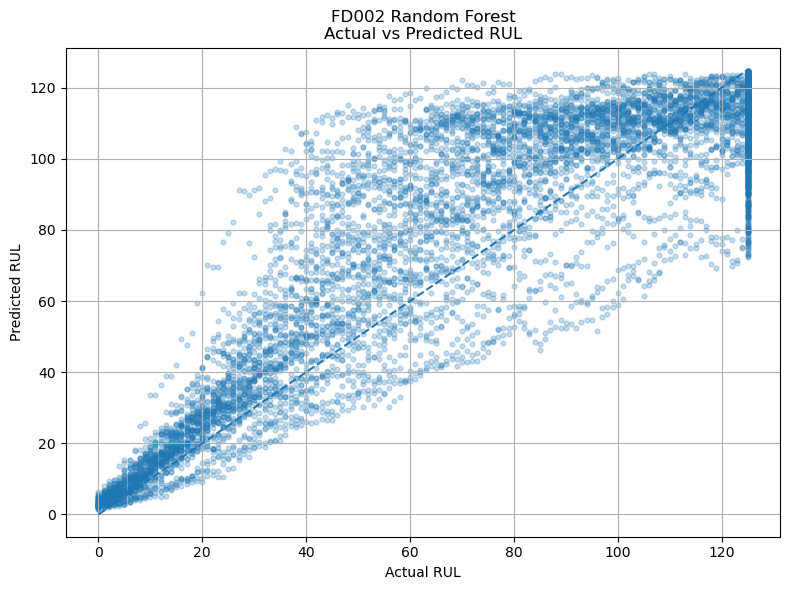

In [195]:
# ============================================================
# FD002 ACTUAL VS PREDICTED RUL
# ============================================================
# A good model should place points near the diagonal line:
#
# Actual RUL ≈ Predicted RUL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_fd002,
    y_pred_fd002_rf,
    alpha=0.25,
    s=12
)

# Perfect-prediction reference line
min_rul = min(
    y_val_fd002.min(),
    y_pred_fd002_rf.min()
)

max_rul = max(
    y_val_fd002.max(),
    y_pred_fd002_rf.max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD002 Random Forest\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

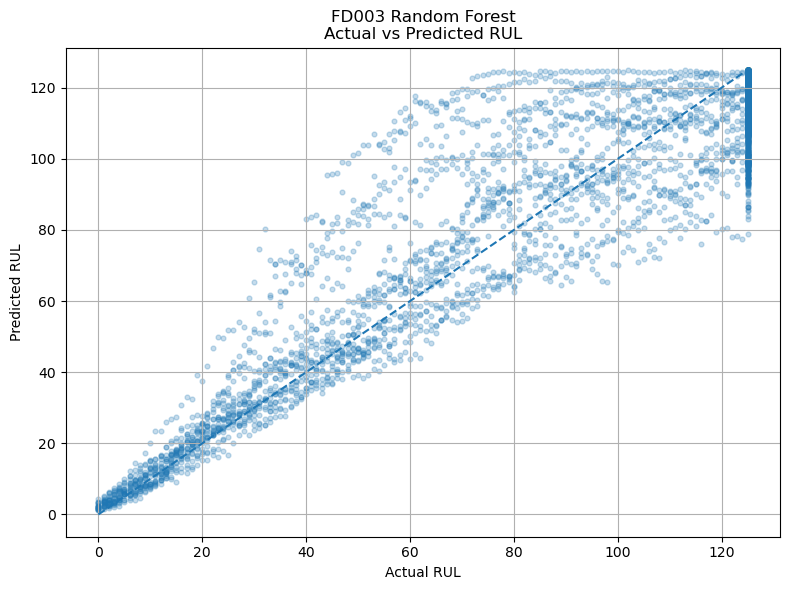

In [196]:
# ============================================================
# FD003 ACTUAL VS PREDICTED RUL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_fd003,
    y_pred_fd003_rf,
    alpha=0.25,
    s=12
)

min_rul = min(
    y_val_fd003.min(),
    y_pred_fd003_rf.min()
)

max_rul = max(
    y_val_fd003.max(),
    y_pred_fd003_rf.max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD003 Random Forest\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

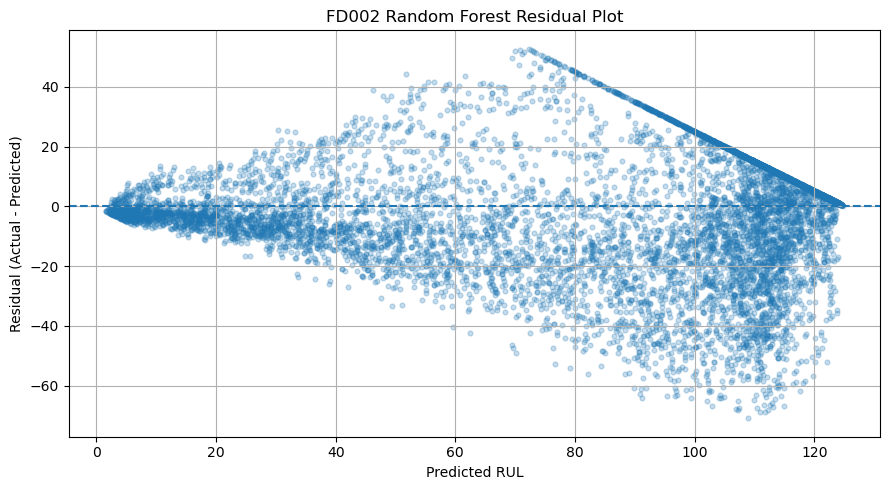

In [197]:
# ============================================================
# FD002 RESIDUAL ANALYSIS
# ============================================================

# Calculate prediction errors
fd002_rf_residuals = (
    y_val_fd002.to_numpy()
    - y_pred_fd002_rf
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_fd002_rf,
    fd002_rf_residuals,
    alpha=0.25,
    s=12
)

# Zero-error reference
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD002 Random Forest Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

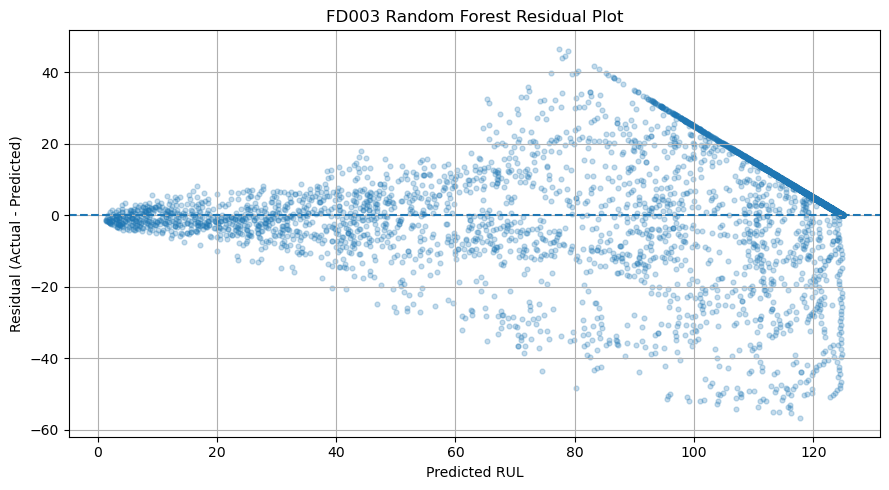

In [198]:
# ============================================================
# FD003 RESIDUAL ANALYSIS
# ============================================================

fd003_rf_residuals = (
    y_val_fd003.to_numpy()
    - y_pred_fd003_rf
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_fd003_rf,
    fd003_rf_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD003 Random Forest Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

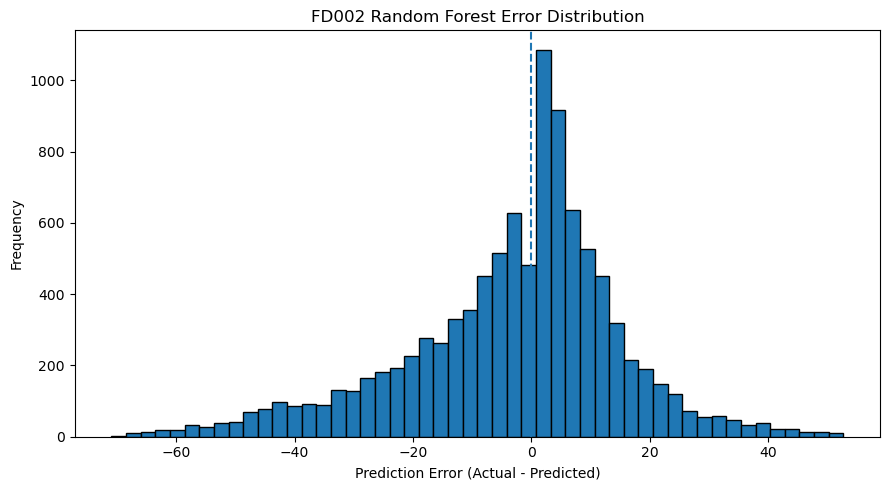

In [199]:
# ============================================================
# FD002 ERROR DISTRIBUTION
# ============================================================
# This shows whether prediction errors are centered around zero
# or systematically biased in one direction.
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    fd002_rf_residuals,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")

plt.title(
    "FD002 Random Forest Error Distribution"
)

plt.tight_layout()
plt.show()

In [200]:
# ============================================================
# FD002 ENGINE-LEVEL LAST-CYCLE EVALUATION
# ============================================================
# Add row-level predictions back to the validation DataFrame.
# ============================================================

fd002_val_rf_results = fd002_val_ml.copy()

fd002_val_rf_results["RF_Predicted_RUL"] = (
    y_pred_fd002_rf
)

# Select only the LAST available cycle of each validation engine
fd002_last_cycle_results = (
    fd002_val_rf_results
    .sort_values(
        ["engine_id", "cycle"]
    )
    .groupby("engine_id")
    .tail(1)
)

print(
    "FD002 Validation Engines Evaluated:",
    len(fd002_last_cycle_results)
)

FD002 Validation Engines Evaluated: 52


In [201]:
# ============================================================
# FD002 LAST-CYCLE METRICS
# ============================================================

fd002_engine_mae = mean_absolute_error(
    fd002_last_cycle_results["RUL_capped"],
    fd002_last_cycle_results["RF_Predicted_RUL"]
)

fd002_engine_rmse = np.sqrt(
    mean_squared_error(
        fd002_last_cycle_results["RUL_capped"],
        fd002_last_cycle_results["RF_Predicted_RUL"]
    )
)

print("FD002 Last-Cycle Engine-Level Metrics")
print(f"MAE  : {fd002_engine_mae:.4f}")
print(f"RMSE : {fd002_engine_rmse:.4f}")

FD002 Last-Cycle Engine-Level Metrics
MAE  : 3.3756
RMSE : 3.5687


In [202]:
# ============================================================
# FD002 RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

fd002_rf_importance = pd.DataFrame({
    "Feature": X_train_fd002.columns,
    "Importance": rf_fd002.feature_importances_
})

# Sort most important features first
fd002_rf_importance = (
    fd002_rf_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

fd002_rf_importance.head(20)

,Feature,Importance
0,sensor_11_model_norm_roll_mean_10,0.069488
1,sensor_4_model_norm_roll_mean_10,0.055371
2,sensor_11_model_norm_roll_mean_5,0.055230
3,sensor_17_model_norm_roll_mean_10,0.040042
4,sensor_4_model_norm_roll_mean_20,0.039064
5,sensor_4_model_norm_roll_mean_5,0.038786
6,sensor_2_model_norm_roll_mean_10,0.037097
7,sensor_15_model_norm_roll_mean_5,0.036254
8,sensor_17_model_norm_roll_mean_20,0.029925
9,sensor_15_model_norm_roll_mean_10,0.029789


In [203]:
# ============================================================
# STORE BASELINE RESULTS
# ============================================================

model_results = pd.DataFrame([
    {
        "Dataset": "FD002",
        "Model": "Random Forest",
        "MAE": fd002_rf_mae,
        "RMSE": fd002_rf_rmse,
        "R2": fd002_rf_r2,
        "Training_Time_sec": rf_fd002_train_time,
        "Inference_Time_sec": rf_fd002_inference_time
    },
    {
        "Dataset": "FD003",
        "Model": "Random Forest",
        "MAE": fd003_rf_mae,
        "RMSE": fd003_rf_rmse,
        "R2": fd003_rf_r2,
        "Training_Time_sec": rf_fd003_train_time,
        "Inference_Time_sec": rf_fd003_inference_time
    }
])

model_results

,Dataset,Model,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD002,Random Forest,13.564615,18.596628,0.802265,106.320242,0.442242
1,FD003,Random Forest,10.061509,14.524648,0.875275,33.055903,0.196373


In [204]:
# ============================================================
# XGBOOST - REQUIRED LIBRARY
# ============================================================
# XGBRegressor is used for continuous RUL prediction.
# ============================================================

from xgboost import XGBRegressor

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [205]:
# ============================================================
# CREATE XGBOOST BASELINE MODELS
# ============================================================
# n_estimators:
# Number of boosting trees.
#
# learning_rate:
# Controls how strongly each new tree corrects previous errors.
#
# max_depth:
# Maximum depth of each decision tree.
#
# subsample:
# Uses a fraction of training rows for each boosting round.
# Helps reduce overfitting.
#
# colsample_bytree:
# Uses a fraction of features in each tree.
#
# objective="reg:squarederror":
# Standard regression objective.
#
# n_jobs=-1:
# Uses available CPU cores.
# ============================================================

xgb_fd002 = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_fd003 = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("XGBoost baseline models created.")

XGBoost baseline models created.


In [206]:
# ============================================================
# TRAIN XGBOOST ON FD002
# ============================================================

# Start training timer
start_time = time.time()

# Train using exactly the same FD002 feature matrix
# that Random Forest used.
xgb_fd002.fit(
    X_train_fd002,
    y_train_fd002
)

# Calculate training time
xgb_fd002_train_time = (
    time.time() - start_time
)

print(
    f"FD002 XGBoost Training Time: "
    f"{xgb_fd002_train_time:.2f} seconds"
)

FD002 XGBoost Training Time: 34.78 seconds


In [207]:
# ============================================================
# FD002 XGBOOST VALIDATION PREDICTIONS
# ============================================================

start_time = time.time()

# Predict RUL for unseen validation engines
y_pred_fd002_xgb = xgb_fd002.predict(
    X_val_fd002
)

# Measure inference time
xgb_fd002_inference_time = (
    time.time() - start_time
)

print(
    f"FD002 XGBoost Prediction Time: "
    f"{xgb_fd002_inference_time:.4f} seconds"
)

print(
    "Number of predictions:",
    len(y_pred_fd002_xgb)
)

FD002 XGBoost Prediction Time: 0.0958 seconds
Number of predictions: 10035


In [208]:
# ============================================================
# FD002 XGBOOST PERFORMANCE METRICS
# ============================================================

# Mean Absolute Error
fd002_xgb_mae = mean_absolute_error(
    y_val_fd002,
    y_pred_fd002_xgb
)

# Mean Squared Error
fd002_xgb_mse = mean_squared_error(
    y_val_fd002,
    y_pred_fd002_xgb
)

# Root Mean Squared Error
fd002_xgb_rmse = np.sqrt(
    fd002_xgb_mse
)

# R-squared
fd002_xgb_r2 = r2_score(
    y_val_fd002,
    y_pred_fd002_xgb
)

print("========== FD002 XGBOOST ==========")

print(f"MAE  : {fd002_xgb_mae:.4f}")
print(f"MSE  : {fd002_xgb_mse:.4f}")
print(f"RMSE : {fd002_xgb_rmse:.4f}")
print(f"R²   : {fd002_xgb_r2:.4f}")

========== FD002 XGBOOST ==========
MAE  : 12.7794
MSE  : 324.5958
RMSE : 18.0165
R²   : 0.8144


In [209]:
# ============================================================
# TRAIN XGBOOST ON FD003
# ============================================================

start_time = time.time()

xgb_fd003.fit(
    X_train_fd003,
    y_train_fd003
)

xgb_fd003_train_time = (
    time.time() - start_time
)

print(
    f"FD003 XGBoost Training Time: "
    f"{xgb_fd003_train_time:.2f} seconds"
)

FD003 XGBoost Training Time: 18.27 seconds


In [210]:
# ============================================================
# FD003 XGBOOST VALIDATION PREDICTIONS
# ============================================================

start_time = time.time()

y_pred_fd003_xgb = xgb_fd003.predict(
    X_val_fd003
)

xgb_fd003_inference_time = (
    time.time() - start_time
)

print(
    f"FD003 XGBoost Prediction Time: "
    f"{xgb_fd003_inference_time:.4f} seconds"
)

FD003 XGBoost Prediction Time: 0.0563 seconds


In [211]:
# ============================================================
# FD003 XGBOOST PERFORMANCE METRICS
# ============================================================

fd003_xgb_mae = mean_absolute_error(
    y_val_fd003,
    y_pred_fd003_xgb
)

fd003_xgb_mse = mean_squared_error(
    y_val_fd003,
    y_pred_fd003_xgb
)

fd003_xgb_rmse = np.sqrt(
    fd003_xgb_mse
)

fd003_xgb_r2 = r2_score(
    y_val_fd003,
    y_pred_fd003_xgb
)

print("========== FD003 XGBOOST ==========")

print(f"MAE  : {fd003_xgb_mae:.4f}")
print(f"MSE  : {fd003_xgb_mse:.4f}")
print(f"RMSE : {fd003_xgb_rmse:.4f}")
print(f"R²   : {fd003_xgb_r2:.4f}")

========== FD003 XGBOOST ==========
MAE  : 9.7221
MSE  : 212.1394
RMSE : 14.5650
R²   : 0.8746


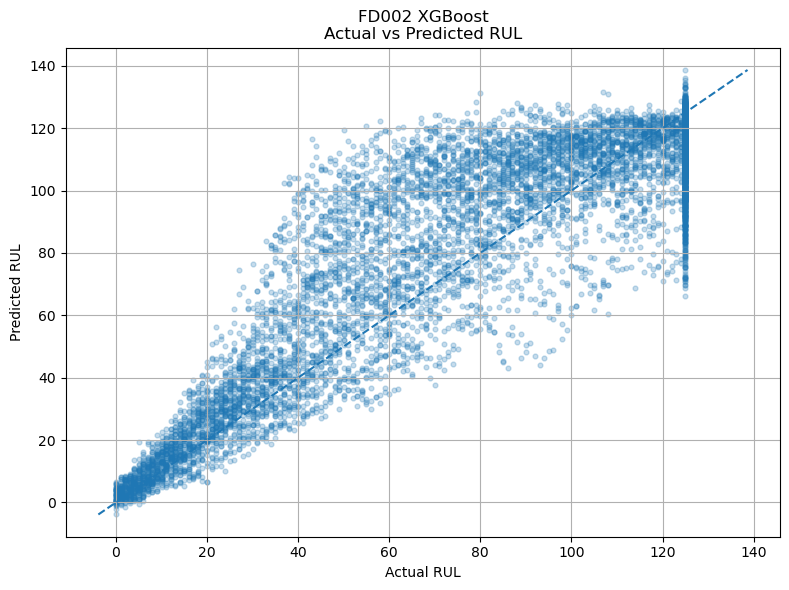

In [212]:
# ============================================================
# FD002 XGBOOST - ACTUAL VS PREDICTED RUL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_fd002,
    y_pred_fd002_xgb,
    alpha=0.25,
    s=12
)

# Create ideal prediction line
min_rul = min(
    y_val_fd002.min(),
    y_pred_fd002_xgb.min()
)

max_rul = max(
    y_val_fd002.max(),
    y_pred_fd002_xgb.max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD002 XGBoost\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

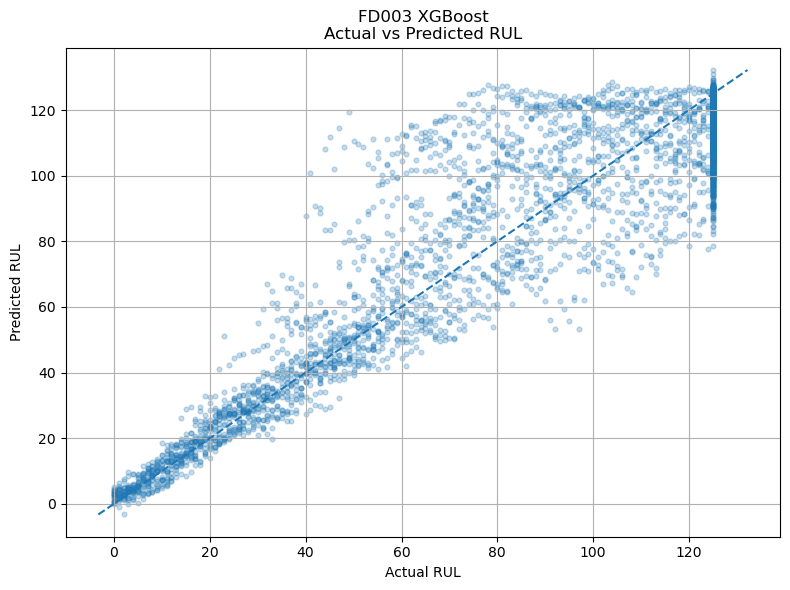

In [213]:
# ============================================================
# FD003 XGBOOST - ACTUAL VS PREDICTED RUL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_fd003,
    y_pred_fd003_xgb,
    alpha=0.25,
    s=12
)

min_rul = min(
    y_val_fd003.min(),
    y_pred_fd003_xgb.min()
)

max_rul = max(
    y_val_fd003.max(),
    y_pred_fd003_xgb.max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD003 XGBoost\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

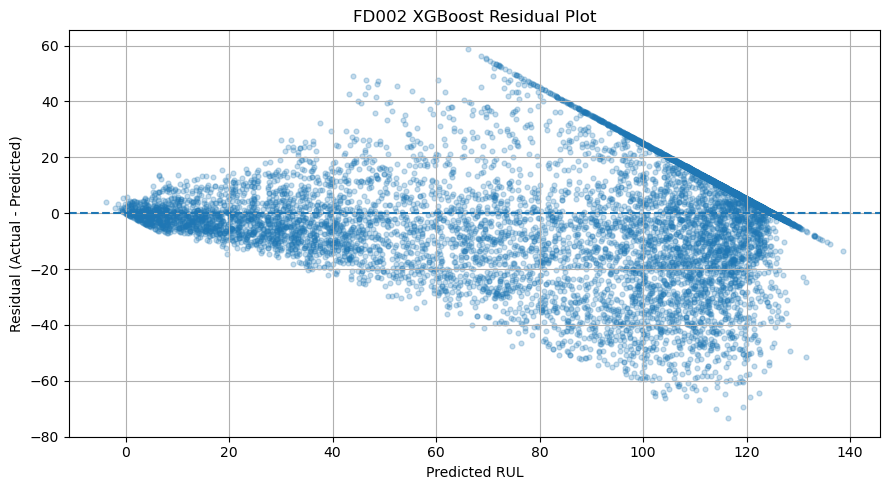

In [214]:
# ============================================================
# FD002 XGBOOST RESIDUAL ANALYSIS
# ============================================================

# Residual = Actual RUL - Predicted RUL
fd002_xgb_residuals = (
    y_val_fd002.to_numpy()
    - y_pred_fd002_xgb
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_fd002_xgb,
    fd002_xgb_residuals,
    alpha=0.25,
    s=12
)

# Perfect prediction reference
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD002 XGBoost Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

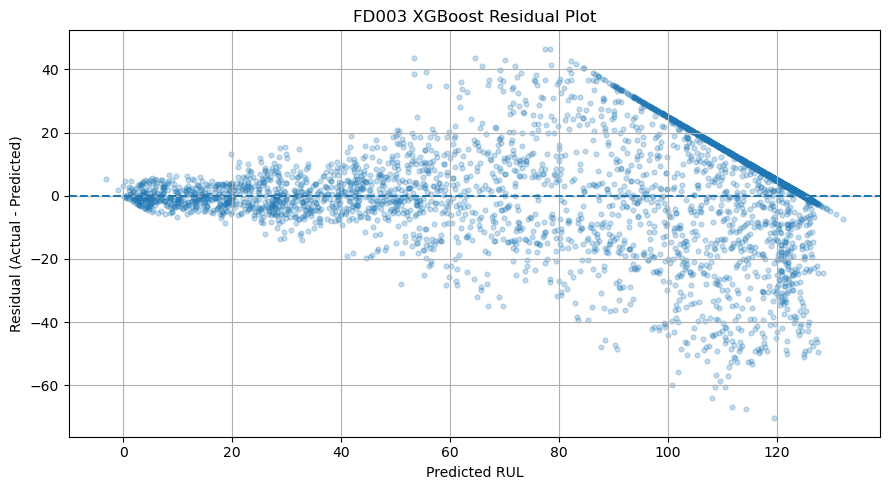

In [215]:
# ============================================================
# FD003 XGBOOST RESIDUAL ANALYSIS
# ============================================================

fd003_xgb_residuals = (
    y_val_fd003.to_numpy()
    - y_pred_fd003_xgb
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_fd003_xgb,
    fd003_xgb_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD003 XGBoost Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

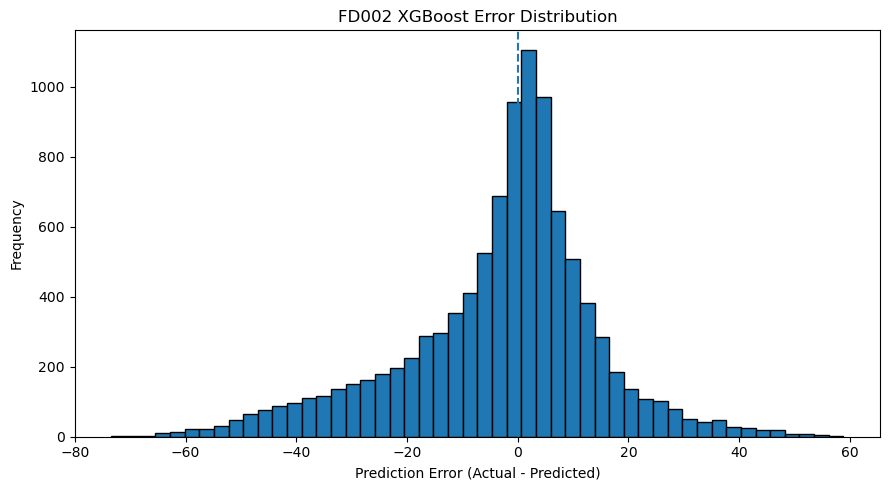

In [216]:
# ============================================================
# FD002 XGBOOST ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    fd002_xgb_residuals,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error (Actual - Predicted)"
)

plt.ylabel("Frequency")

plt.title(
    "FD002 XGBoost Error Distribution"
)

plt.tight_layout()
plt.show()

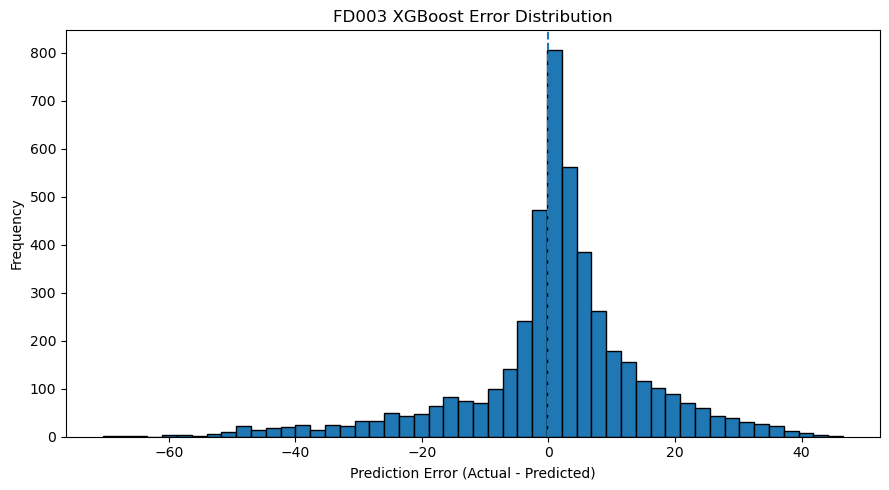

In [217]:
# ============================================================
# FD003 XGBOOST ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    fd003_xgb_residuals,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error (Actual - Predicted)"
)

plt.ylabel("Frequency")

plt.title(
    "FD003 XGBoost Error Distribution"
)

plt.tight_layout()
plt.show()

In [218]:
# ============================================================
# FD002 XGBOOST FEATURE IMPORTANCE
# ============================================================

fd002_xgb_importance = pd.DataFrame({
    "Feature": X_train_fd002.columns,
    "Importance": xgb_fd002.feature_importances_
})

# Highest importance first
fd002_xgb_importance = (
    fd002_xgb_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

fd002_xgb_importance.head(20)

,Feature,Importance
0,sensor_11_model_norm_roll_mean_10,0.322946
1,sensor_11_model_norm_roll_mean_5,0.145751
2,sensor_4_model_norm_roll_mean_5,0.078312
3,sensor_4_model_norm_roll_mean_10,0.075032
4,sensor_13_model_norm_roll_mean_20,0.026166
5,sensor_15_model_norm_roll_mean_5,0.020757
6,sensor_13_model_norm_roll_mean_10,0.019379
7,sensor_17_model_norm_roll_mean_10,0.016500
8,sensor_17_model_norm_roll_mean_5,0.011409
9,sensor_3_model_norm_roll_mean_10,0.010165


In [219]:
# ============================================================
# FD003 XGBOOST FEATURE IMPORTANCE
# ============================================================

fd003_xgb_importance = pd.DataFrame({
    "Feature": X_train_fd003.columns,
    "Importance": xgb_fd003.feature_importances_
})

fd003_xgb_importance = (
    fd003_xgb_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

fd003_xgb_importance.head(20)

,Feature,Importance
0,sensor_11_model_norm_roll_mean_5,0.242314
1,sensor_3_model_norm_roll_mean_10,0.164457
2,sensor_17_model_norm_roll_mean_5,0.142952
3,sensor_17_model_norm_roll_mean_10,0.111210
4,sensor_9_model_norm_roll_mean_5,0.055190
5,sensor_3_model_norm_roll_mean_5,0.047288
6,sensor_9_model_norm_roll_mean_10,0.030172
7,sensor_11_model_norm_roll_mean_10,0.012083
8,sensor_12_model_norm_roll_std_20,0.011717
9,sensor_7_model_norm_roll_mean_5,0.007052


In [220]:
# ============================================================
# ADD XGBOOST RESULTS TO MODEL COMPARISON TABLE
# ============================================================

xgb_results = pd.DataFrame([
    {
        "Dataset": "FD002",
        "Model": "XGBoost",
        "MAE": fd002_xgb_mae,
        "RMSE": fd002_xgb_rmse,
        "R2": fd002_xgb_r2,
        "Training_Time_sec": xgb_fd002_train_time,
        "Inference_Time_sec": xgb_fd002_inference_time
    },
    {
        "Dataset": "FD003",
        "Model": "XGBoost",
        "MAE": fd003_xgb_mae,
        "RMSE": fd003_xgb_rmse,
        "R2": fd003_xgb_r2,
        "Training_Time_sec": xgb_fd003_train_time,
        "Inference_Time_sec": xgb_fd003_inference_time
    }
])

# Append XGBoost results under Random Forest results
model_results = pd.concat(
    [
        model_results,
        xgb_results
    ],
    ignore_index=True
)

model_results

,Dataset,Model,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD002,Random Forest,13.564615,18.596628,0.802265,106.320242,0.442242
1,FD003,Random Forest,10.061509,14.524648,0.875275,33.055903,0.196373
2,FD002,XGBoost,12.779441,18.016542,0.814409,34.777834,0.095755
3,FD003,XGBoost,9.722129,14.565006,0.874581,18.268160,0.056294


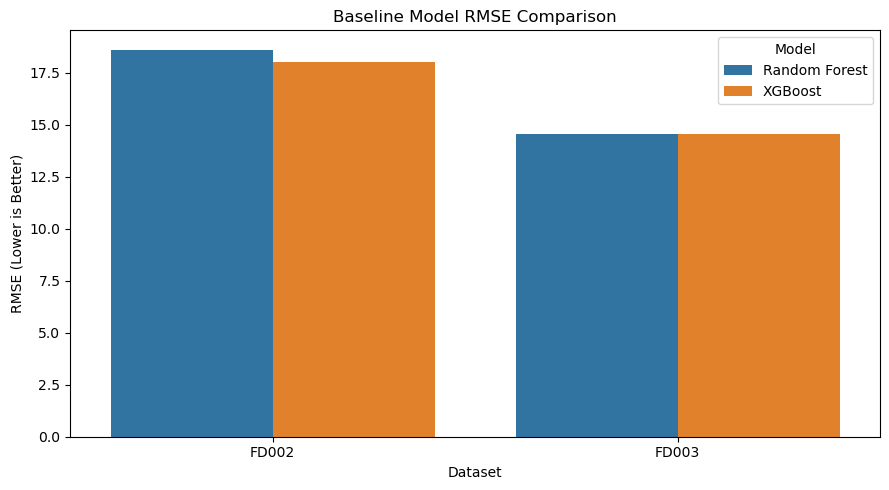

In [221]:
# ============================================================
# RANDOM FOREST VS XGBOOST - RMSE COMPARISON
# ============================================================

plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_results,
    x="Dataset",
    y="RMSE",
    hue="Model"
)

plt.title(
    "Baseline Model RMSE Comparison"
)

plt.ylabel("RMSE (Lower is Better)")
plt.xlabel("Dataset")

plt.tight_layout()
plt.show()

In [222]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [223]:
# ============================================================
# LIGHTGBM - REQUIRED LIBRARY
# ============================================================

from lightgbm import LGBMRegressor

print("LightGBM imported successfully.")


LightGBM imported successfully.


In [224]:
# ============================================================
# CREATE LIGHTGBM BASELINE MODELS
# ============================================================
# n_estimators:
# Total boosting trees.
#
# learning_rate:
# Controls how much each new tree contributes.
#
# num_leaves:
# Controls tree complexity in LightGBM.
#
# max_depth:
# Restricts excessive tree growth.
#
# subsample:
# Uses a portion of rows per boosting iteration.
#
# colsample_bytree:
# Uses a subset of features per tree.
#
# random_state:
# Makes results reproducible.
# ============================================================

lgbm_fd002 = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgbm_fd003 = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

print("LightGBM baseline models created.")

LightGBM baseline models created.


In [225]:
# ============================================================
# TRAIN LIGHTGBM ON FD002
# ============================================================

start_time = time.time()

lgbm_fd002.fit(
    X_train_fd002,
    y_train_fd002
)

lgbm_fd002_train_time = (
    time.time() - start_time
)

print(
    f"FD002 LightGBM Training Time: "
    f"{lgbm_fd002_train_time:.2f} seconds"
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.050197 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 38475
[LightGBM] [Info] Number of data points in the train set: 42424, number of used features: 166
[LightGBM] [Info] Start training from score 86.389850
FD002 LightGBM Training Time: 10.35 seconds


In [226]:
# ============================================================
# FD002 LIGHTGBM VALIDATION PREDICTION
# ============================================================

start_time = time.time()

y_pred_fd002_lgbm = lgbm_fd002.predict(
    X_val_fd002
)

lgbm_fd002_inference_time = (
    time.time() - start_time
)

print(
    f"FD002 LightGBM Prediction Time: "
    f"{lgbm_fd002_inference_time:.4f} seconds"
)

print(
    "Number of predictions:",
    len(y_pred_fd002_lgbm)
)

FD002 LightGBM Prediction Time: 0.1661 seconds
Number of predictions: 10035


In [227]:
# ============================================================
# FD002 LIGHTGBM PERFORMANCE
# ============================================================

fd002_lgbm_mae = mean_absolute_error(
    y_val_fd002,
    y_pred_fd002_lgbm
)

fd002_lgbm_mse = mean_squared_error(
    y_val_fd002,
    y_pred_fd002_lgbm
)

fd002_lgbm_rmse = np.sqrt(
    fd002_lgbm_mse
)

fd002_lgbm_r2 = r2_score(
    y_val_fd002,
    y_pred_fd002_lgbm
)

print("========== FD002 LIGHTGBM ==========")

print(f"MAE  : {fd002_lgbm_mae:.4f}")
print(f"MSE  : {fd002_lgbm_mse:.4f}")
print(f"RMSE : {fd002_lgbm_rmse:.4f}")
print(f"R²   : {fd002_lgbm_r2:.4f}")

========== FD002 LIGHTGBM ==========
MAE  : 12.8498
MSE  : 327.1390
RMSE : 18.0870
R²   : 0.8130


In [228]:
# ============================================================
# TRAIN LIGHTGBM ON FD003
# ============================================================

start_time = time.time()

lgbm_fd003.fit(
    X_train_fd003,
    y_train_fd003
)

lgbm_fd003_train_time = (
    time.time() - start_time
)

print(
    f"FD003 LightGBM Training Time: "
    f"{lgbm_fd003_train_time:.2f} seconds"
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.047432 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 34079
[LightGBM] [Info] Number of data points in the train set: 19612, number of used features: 160
[LightGBM] [Info] Start training from score 92.876810
FD003 LightGBM Training Time: 11.60 seconds


In [229]:
# ============================================================
# FD003 LIGHTGBM VALIDATION PREDICTION
# ============================================================

start_time = time.time()

y_pred_fd003_lgbm = lgbm_fd003.predict(
    X_val_fd003
)

lgbm_fd003_inference_time = (
    time.time() - start_time
)

print(
    f"FD003 LightGBM Prediction Time: "
    f"{lgbm_fd003_inference_time:.4f} seconds"
)

FD003 LightGBM Prediction Time: 0.0847 seconds


In [230]:
# ============================================================
# FD003 LIGHTGBM PERFORMANCE
# ============================================================

fd003_lgbm_mae = mean_absolute_error(
    y_val_fd003,
    y_pred_fd003_lgbm
)

fd003_lgbm_mse = mean_squared_error(
    y_val_fd003,
    y_pred_fd003_lgbm
)

fd003_lgbm_rmse = np.sqrt(
    fd003_lgbm_mse
)

fd003_lgbm_r2 = r2_score(
    y_val_fd003,
    y_pred_fd003_lgbm
)

print("========== FD003 LIGHTGBM ==========")

print(f"MAE  : {fd003_lgbm_mae:.4f}")
print(f"MSE  : {fd003_lgbm_mse:.4f}")
print(f"RMSE : {fd003_lgbm_rmse:.4f}")
print(f"R²   : {fd003_lgbm_r2:.4f}")

========== FD003 LIGHTGBM ==========
MAE  : 9.6838
MSE  : 213.7370
RMSE : 14.6197
R²   : 0.8736


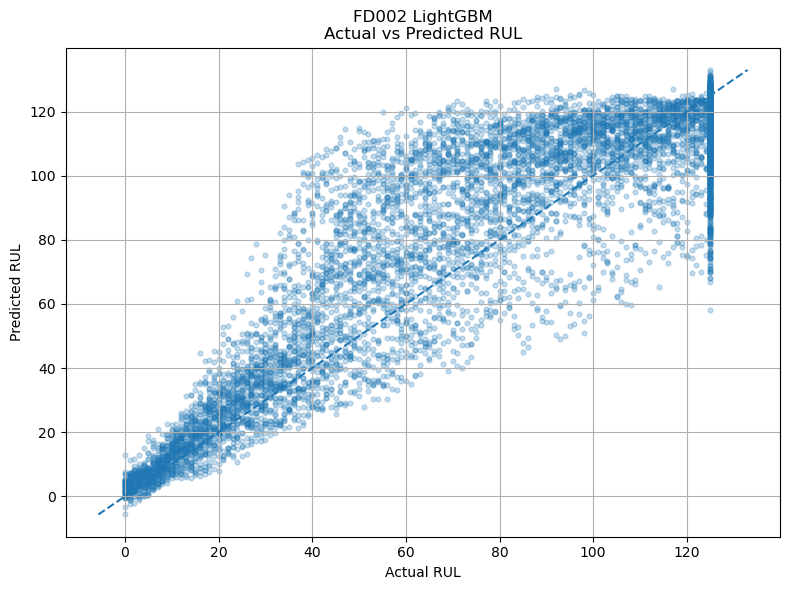

In [231]:
# ============================================================
# FD002 LIGHTGBM - ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_fd002,
    y_pred_fd002_lgbm,
    alpha=0.25,
    s=12
)

# Perfect prediction reference line
min_rul = min(
    y_val_fd002.min(),
    y_pred_fd002_lgbm.min()
)

max_rul = max(
    y_val_fd002.max(),
    y_pred_fd002_lgbm.max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD002 LightGBM\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

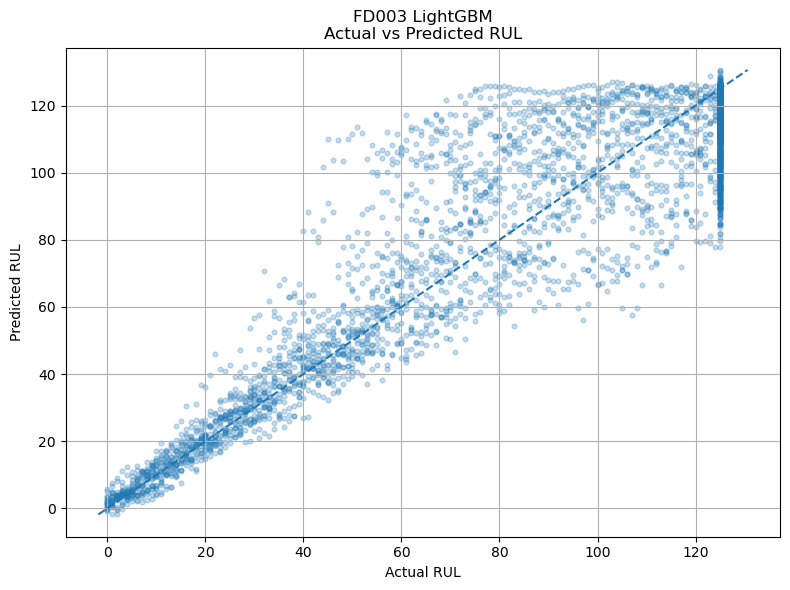

In [232]:
# ============================================================
# FD003 LIGHTGBM - ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_fd003,
    y_pred_fd003_lgbm,
    alpha=0.25,
    s=12
)

min_rul = min(
    y_val_fd003.min(),
    y_pred_fd003_lgbm.min()
)

max_rul = max(
    y_val_fd003.max(),
    y_pred_fd003_lgbm.max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD003 LightGBM\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

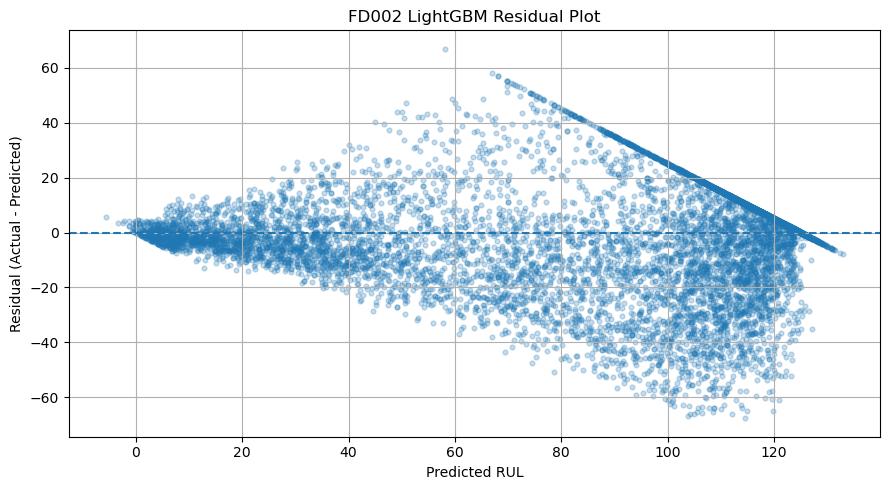

In [233]:
# ============================================================
# FD002 LIGHTGBM RESIDUAL ANALYSIS
# ============================================================

fd002_lgbm_residuals = (
    y_val_fd002.to_numpy()
    - y_pred_fd002_lgbm
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_fd002_lgbm,
    fd002_lgbm_residuals,
    alpha=0.25,
    s=12
)

# Zero residual = perfect prediction
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD002 LightGBM Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

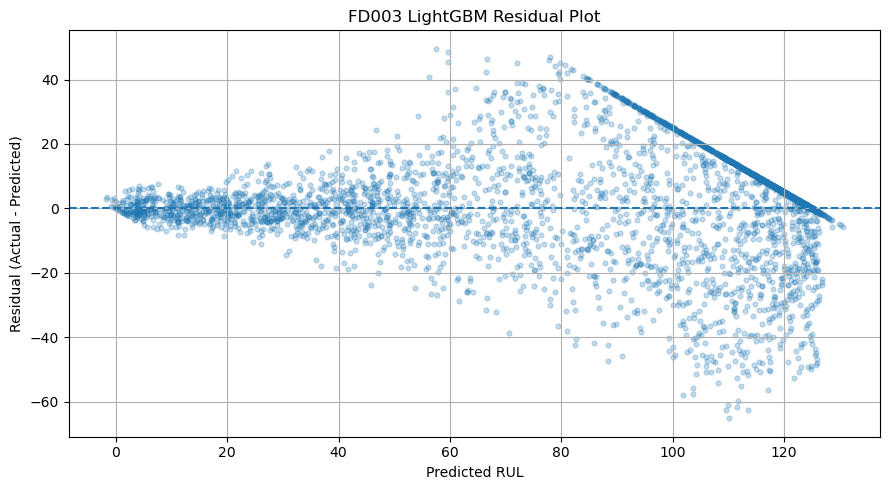

In [234]:
# ============================================================
# FD003 LIGHTGBM RESIDUAL ANALYSIS
# ============================================================

fd003_lgbm_residuals = (
    y_val_fd003.to_numpy()
    - y_pred_fd003_lgbm
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_fd003_lgbm,
    fd003_lgbm_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD003 LightGBM Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

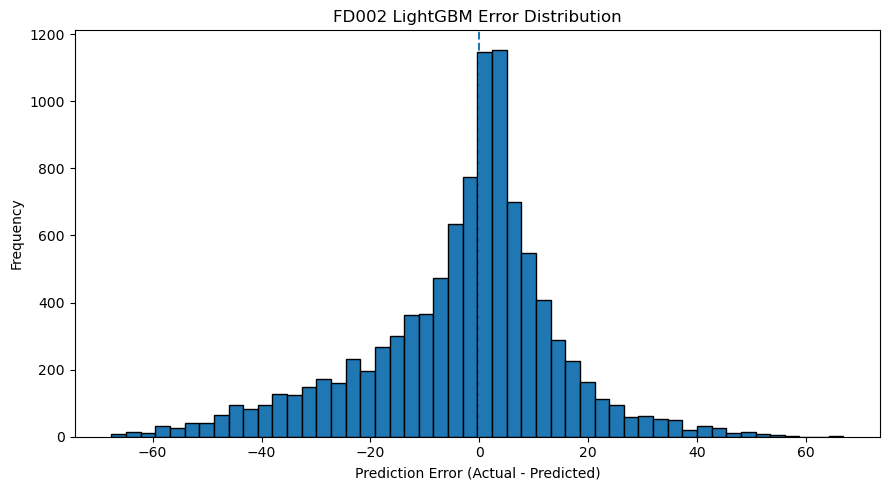

In [235]:
# ============================================================
# FD002 LIGHTGBM ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    fd002_lgbm_residuals,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error (Actual - Predicted)"
)

plt.ylabel("Frequency")

plt.title(
    "FD002 LightGBM Error Distribution"
)

plt.tight_layout()
plt.show()

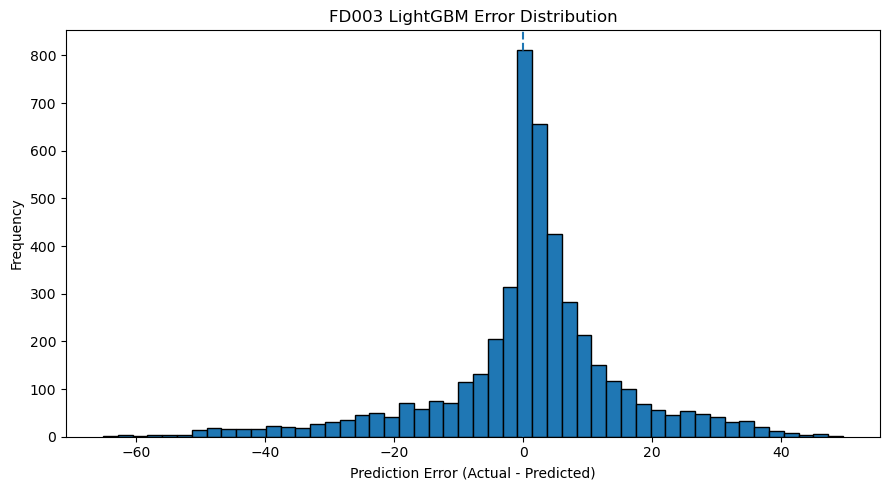

In [236]:
# ============================================================
# FD003 LIGHTGBM ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    fd003_lgbm_residuals,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error (Actual - Predicted)"
)

plt.ylabel("Frequency")

plt.title(
    "FD003 LightGBM Error Distribution"
)

plt.tight_layout()
plt.show()

In [237]:
# ============================================================
# FD002 LIGHTGBM FEATURE IMPORTANCE
# ============================================================

fd002_lgbm_importance = pd.DataFrame({
    "Feature": X_train_fd002.columns,
    "Importance": lgbm_fd002.feature_importances_
})

fd002_lgbm_importance = (
    fd002_lgbm_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

fd002_lgbm_importance.head(20)

,Feature,Importance
0,sensor_14_model_norm_roll_mean_20,402
1,sensor_9_model_norm_roll_mean_20,393
2,sensor_13_model_norm_roll_std_20,380
3,sensor_10_model_norm_roll_std_20,367
4,sensor_4_model_norm_roll_mean_20,358
5,sensor_11_model_norm_roll_mean_20,326
6,sensor_8_model_norm_roll_std_20,318
7,sensor_9_model_norm_roll_std_20,313
8,sensor_14_model_norm_roll_std_20,308
9,sensor_11_model_norm_roll_std_20,288


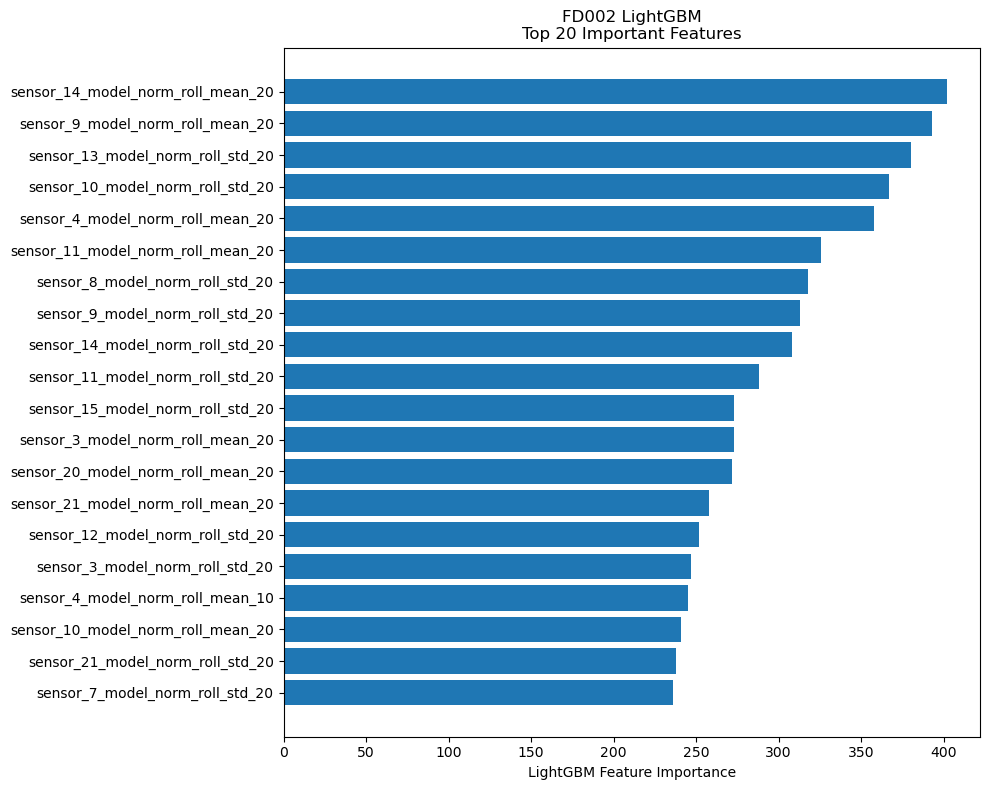

In [238]:
# ============================================================
# TOP 20 FD002 LIGHTGBM FEATURES
# ============================================================

top_n = 20

plt.figure(figsize=(10, 8))

plt.barh(
    fd002_lgbm_importance["Feature"][:top_n],
    fd002_lgbm_importance["Importance"][:top_n]
)

# Highest feature on top
plt.gca().invert_yaxis()

plt.xlabel("LightGBM Feature Importance")

plt.title(
    "FD002 LightGBM\nTop 20 Important Features"
)

plt.tight_layout()
plt.show()

In [239]:
# ============================================================
# FD003 LIGHTGBM FEATURE IMPORTANCE
# ============================================================

fd003_lgbm_importance = pd.DataFrame({
    "Feature": X_train_fd003.columns,
    "Importance": lgbm_fd003.feature_importances_
})

fd003_lgbm_importance = (
    fd003_lgbm_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

fd003_lgbm_importance.head(20)

,Feature,Importance
0,sensor_12_model_norm_roll_std_20,508
1,sensor_14_model_norm_roll_mean_20,388
2,sensor_8_model_norm_roll_std_20,388
3,sensor_7_model_norm_roll_std_20,382
4,sensor_9_model_norm_roll_mean_20,376
5,sensor_14_model_norm_roll_std_20,333
6,sensor_21_model_norm_roll_std_20,314
7,sensor_9_model_norm_roll_std_20,308
8,sensor_13_model_norm_roll_std_20,284
9,sensor_2_model_norm_roll_std_20,280


In [240]:
# ============================================================
# ADD LIGHTGBM RESULTS TO BASELINE COMPARISON
# ============================================================

lgbm_results = pd.DataFrame([
    {
        "Dataset": "FD002",
        "Model": "LightGBM",
        "MAE": fd002_lgbm_mae,
        "RMSE": fd002_lgbm_rmse,
        "R2": fd002_lgbm_r2,
        "Training_Time_sec": lgbm_fd002_train_time,
        "Inference_Time_sec": lgbm_fd002_inference_time
    },
    {
        "Dataset": "FD003",
        "Model": "LightGBM",
        "MAE": fd003_lgbm_mae,
        "RMSE": fd003_lgbm_rmse,
        "R2": fd003_lgbm_r2,
        "Training_Time_sec": lgbm_fd003_train_time,
        "Inference_Time_sec": lgbm_fd003_inference_time
    }
])

# Append LightGBM results to previous RF + XGBoost table
model_results = pd.concat(
    [
        model_results,
        lgbm_results
    ],
    ignore_index=True
)

model_results

,Dataset,Model,MAE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD002,Random Forest,13.564615,18.596628,0.802265,106.320242,0.442242
1,FD003,Random Forest,10.061509,14.524648,0.875275,33.055903,0.196373
2,FD002,XGBoost,12.779441,18.016542,0.814409,34.777834,0.095755
3,FD003,XGBoost,9.722129,14.565006,0.874581,18.268160,0.056294
4,FD002,LightGBM,12.849766,18.086984,0.812955,10.350715,0.166093
5,FD003,LightGBM,9.683799,14.619746,0.873637,11.600616,0.084714


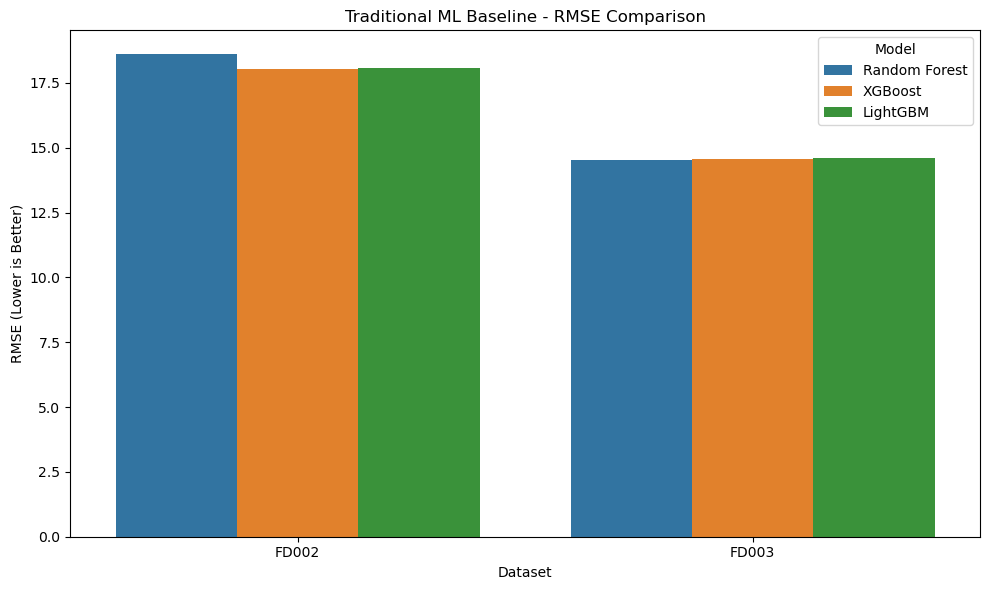

In [241]:
# ============================================================
# RF VS XGBOOST VS LIGHTGBM - RMSE
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_results,
    x="Dataset",
    y="RMSE",
    hue="Model"
)

plt.title(
    "Traditional ML Baseline - RMSE Comparison"
)

plt.xlabel("Dataset")
plt.ylabel("RMSE (Lower is Better)")

plt.tight_layout()
plt.show()

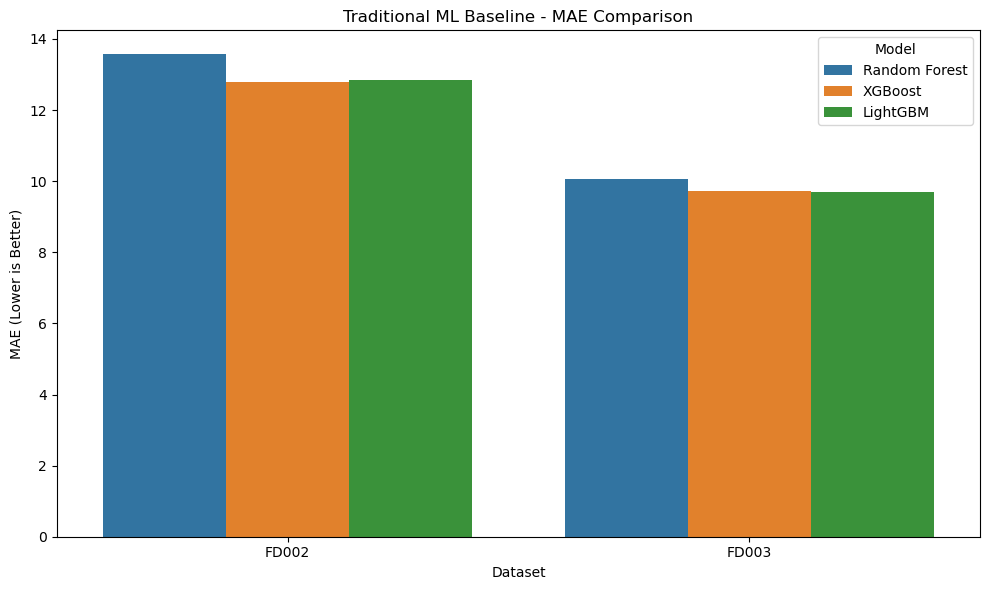

In [242]:
# ============================================================
# RF VS XGBOOST VS LIGHTGBM - MAE
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_results,
    x="Dataset",
    y="MAE",
    hue="Model"
)

plt.title(
    "Traditional ML Baseline - MAE Comparison"
)

plt.xlabel("Dataset")
plt.ylabel("MAE (Lower is Better)")

plt.tight_layout()
plt.show()

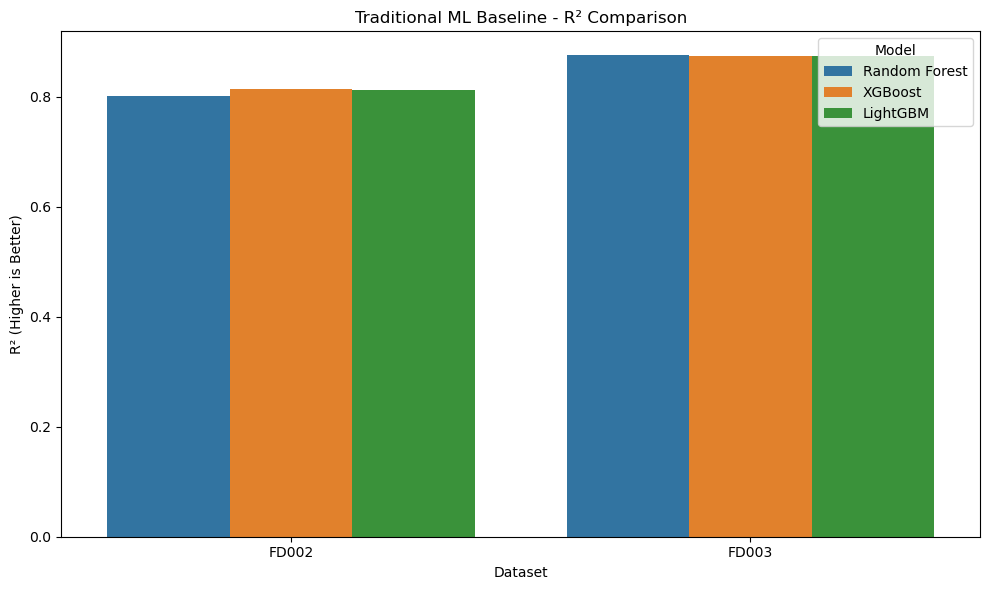

In [243]:
# ============================================================
# RF VS XGBOOST VS LIGHTGBM - R²
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_results,
    x="Dataset",
    y="R2",
    hue="Model"
)

plt.title(
    "Traditional ML Baseline - R² Comparison"
)

plt.xlabel("Dataset")
plt.ylabel("R² (Higher is Better)")

plt.tight_layout()
plt.show()

In [244]:
# ============================================================
# COMBINE FEATURE IMPORTANCE FROM THREE ML MODELS - FD002
# ============================================================
# Purpose:
# Compare which engineered features are consistently important
# across Random Forest, XGBoost, and LightGBM.
# ============================================================

# Rename importance columns so every model is clearly identified
rf_imp_fd002 = fd002_rf_importance.rename(
    columns={"Importance": "RF_Importance"}
)

xgb_imp_fd002 = fd002_xgb_importance.rename(
    columns={"Importance": "XGB_Importance"}
)

lgbm_imp_fd002 = fd002_lgbm_importance.rename(
    columns={"Importance": "LGBM_Importance"}
)

# Merge all three importance tables by feature name
combined_importance_fd002 = (
    rf_imp_fd002
    .merge(
        xgb_imp_fd002,
        on="Feature",
        how="outer"
    )
    .merge(
        lgbm_imp_fd002,
        on="Feature",
        how="outer"
    )
)

# Replace any missing values with zero
combined_importance_fd002 = (
    combined_importance_fd002.fillna(0)
)

combined_importance_fd002.head()

,Feature,RF_Importance,XGB_Importance,LGBM_Importance
0,condition_0,0.000057,0.000782,0
1,condition_1,0.000047,0.000832,0
2,condition_2,0.000051,0.000424,0
3,condition_3,0.000047,0.001361,0
4,condition_4,0.000038,0.000350,0


In [245]:
# ============================================================
# CREATE RANDOM FOREST FEATURE IMPORTANCE TABLES
# FD002 + FD003
# ============================================================
# Purpose:
# Step 16 mein RF, XGBoost aur LightGBM ki feature importance
# combine karni hai.
#
# Isliye dono datasets ke Random Forest feature importance
# tables explicitly create/save kar rahe hain.
# ============================================================


# ----------------------------
# FD002 RANDOM FOREST
# ----------------------------

fd002_rf_importance = pd.DataFrame({
    "Feature": X_train_fd002.columns,
    "Importance": rf_fd002.feature_importances_
})

# Highest importance first
fd002_rf_importance = (
    fd002_rf_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


# ----------------------------
# FD003 RANDOM FOREST
# ----------------------------

fd003_rf_importance = pd.DataFrame({
    "Feature": X_train_fd003.columns,
    "Importance": rf_fd003.feature_importances_
})

# Highest importance first
fd003_rf_importance = (
    fd003_rf_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


print("FD002 RF Importance Shape:", fd002_rf_importance.shape)
print("FD003 RF Importance Shape:", fd003_rf_importance.shape)

print("\nTop 5 FD003 Random Forest Features:")
display(fd003_rf_importance.head())# Check whether Random Forest model variables exist
print("rf_fd002 exists:", "rf_fd002" in globals())
print("rf_fd003 exists:", "rf_fd003" in globals())

FD002 RF Importance Shape: (166, 2)
FD003 RF Importance Shape: (160, 2)

Top 5 FD003 Random Forest Features:


,Feature,Importance
0,sensor_17_model_norm_roll_mean_10,0.054386
1,sensor_3_model_norm_roll_mean_10,0.052353
2,sensor_11_model_norm_roll_mean_5,0.051898
3,sensor_17_model_norm_roll_mean_5,0.051282
4,sensor_11_model_norm_roll_mean_10,0.046761


rf_fd002 exists: True
rf_fd003 exists: True


In [246]:
# Check whether Random Forest model variables exist
print("rf_fd002 exists:", "rf_fd002" in globals())
print("rf_fd003 exists:", "rf_fd003" in globals())

rf_fd002 exists: True
rf_fd003 exists: True


In [247]:
# ============================================================
# COMBINE FEATURE IMPORTANCE FROM THREE ML MODELS - FD003
# ============================================================

# Random Forest importance
rf_imp_fd003 = fd003_rf_importance.rename(
    columns={
        "Importance": "RF_Importance"
    }
)

# XGBoost importance
xgb_imp_fd003 = fd003_xgb_importance.rename(
    columns={
        "Importance": "XGB_Importance"
    }
)

# LightGBM importance
lgbm_imp_fd003 = fd003_lgbm_importance.rename(
    columns={
        "Importance": "LGBM_Importance"
    }
)

# Merge all three models using feature name
combined_importance_fd003 = (
    rf_imp_fd003
    .merge(
        xgb_imp_fd003,
        on="Feature",
        how="outer"
    )
    .merge(
        lgbm_imp_fd003,
        on="Feature",
        how="outer"
    )
)

# Safety: replace missing importance values with zero
combined_importance_fd003 = (
    combined_importance_fd003.fillna(0)
)

display(combined_importance_fd003.head())

,Feature,RF_Importance,XGB_Importance,LGBM_Importance
0,sensor_10_model_norm,0.000068,0.000023,0
1,sensor_10_model_norm_diff_1,0.000006,0.000067,1
2,sensor_10_model_norm_lag_1,0.000449,0.000010,0
3,sensor_10_model_norm_lag_5,0.000007,0.000000,0
4,sensor_10_model_norm_roll_mean_10,0.000250,0.000123,5


In [248]:
# ============================================================
# RANK FEATURES ACROSS RF + XGBOOST + LIGHTGBM - FD002
# ============================================================
# Rank 1 = most important feature
# Smaller average rank = more consistently important feature
# ============================================================

# Random Forest ranking
combined_importance_fd002["RF_Rank"] = (
    combined_importance_fd002["RF_Importance"]
    .rank(ascending=False, method="average")
)

# XGBoost ranking
combined_importance_fd002["XGB_Rank"] = (
    combined_importance_fd002["XGB_Importance"]
    .rank(ascending=False, method="average")
)

# LightGBM ranking
combined_importance_fd002["LGBM_Rank"] = (
    combined_importance_fd002["LGBM_Importance"]
    .rank(ascending=False, method="average")
)

# Average ranking across all three models
combined_importance_fd002["Average_Model_Rank"] = (
    combined_importance_fd002[
        ["RF_Rank", "XGB_Rank", "LGBM_Rank"]
    ].mean(axis=1)
)

# Best features first
combined_importance_fd002 = (
    combined_importance_fd002
    .sort_values("Average_Model_Rank")
    .reset_index(drop=True)
)

display(
    combined_importance_fd002[
        [
            "Feature",
            "RF_Rank",
            "XGB_Rank",
            "LGBM_Rank",
            "Average_Model_Rank"
        ]
    ].head(20)
)

,Feature,RF_Rank,XGB_Rank,LGBM_Rank,Average_Model_Rank
0,sensor_4_model_norm_roll_mean_10,2.0,4.0,17.0,7.666667
1,sensor_11_model_norm_roll_mean_10,1.0,1.0,29.0,10.333333
2,sensor_11_model_norm_roll_mean_5,3.0,2.0,31.0,12.000000
3,sensor_4_model_norm_roll_mean_20,5.0,31.0,5.0,13.666667
4,sensor_11_model_norm_roll_mean_20,11.0,27.0,6.0,14.666667
5,sensor_15_model_norm_roll_mean_10,10.0,14.0,25.0,16.333333
6,sensor_9_model_norm_roll_mean_20,38.0,11.0,2.0,17.000000
7,sensor_2_model_norm_roll_mean_20,13.0,20.0,21.0,18.000000
8,sensor_17_model_norm_roll_mean_10,4.0,8.0,43.5,18.500000
9,sensor_2_model_norm_roll_mean_10,7.0,13.0,36.0,18.666667


In [249]:
# ============================================================
# RANK FEATURES ACROSS RF + XGBOOST + LIGHTGBM - FD003
# ============================================================

combined_importance_fd003["RF_Rank"] = (
    combined_importance_fd003["RF_Importance"]
    .rank(ascending=False, method="average")
)

combined_importance_fd003["XGB_Rank"] = (
    combined_importance_fd003["XGB_Importance"]
    .rank(ascending=False, method="average")
)

combined_importance_fd003["LGBM_Rank"] = (
    combined_importance_fd003["LGBM_Importance"]
    .rank(ascending=False, method="average")
)

combined_importance_fd003["Average_Model_Rank"] = (
    combined_importance_fd003[
        ["RF_Rank", "XGB_Rank", "LGBM_Rank"]
    ].mean(axis=1)
)

combined_importance_fd003 = (
    combined_importance_fd003
    .sort_values("Average_Model_Rank")
    .reset_index(drop=True)
)

display(
    combined_importance_fd003[
        [
            "Feature",
            "RF_Rank",
            "XGB_Rank",
            "LGBM_Rank",
            "Average_Model_Rank"
        ]
    ].head(20)
)

,Feature,RF_Rank,XGB_Rank,LGBM_Rank,Average_Model_Rank
0,sensor_12_model_norm_roll_std_20,23.0,9.0,1.0,11.000000
1,sensor_11_model_norm_roll_mean_5,3.0,1.0,34.0,12.666667
2,sensor_3_model_norm_roll_mean_10,2.0,2.0,34.0,12.666667
3,sensor_14_model_norm_roll_mean_10,20.0,13.0,11.0,14.666667
4,sensor_9_model_norm_roll_mean_20,24.0,17.0,5.0,15.333333
5,sensor_3_model_norm_roll_mean_20,6.0,25.0,16.0,15.666667
6,sensor_11_model_norm_roll_mean_10,5.0,8.0,34.0,15.666667
7,sensor_14_model_norm_roll_mean_20,32.0,14.0,2.5,16.166667
8,sensor_17_model_norm_roll_mean_10,1.0,4.0,44.0,16.333333
9,sensor_7_model_norm_roll_std_20,30.0,15.0,4.0,16.333333


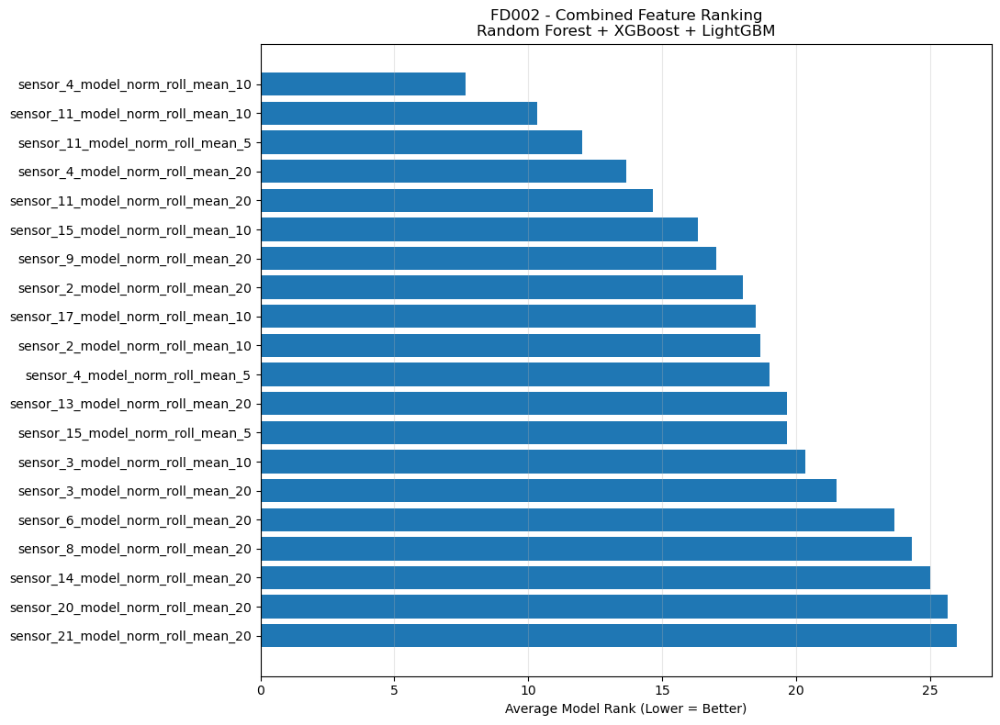

In [250]:
# ============================================================
# TOP 20 CONSISTENT ENGINEERED FEATURES - FD002
# ============================================================

# Select top 20 features
top20_fd002_combined = (
    combined_importance_fd002.head(20).copy()
)

# Reverse order so strongest appears at top in barh plot
top20_fd002_combined = (
    top20_fd002_combined
    .sort_values(
        "Average_Model_Rank",
        ascending=False
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    top20_fd002_combined["Feature"],
    top20_fd002_combined["Average_Model_Rank"]
)

plt.xlabel("Average Model Rank (Lower = Better)")

plt.title(
    "FD002 - Combined Feature Ranking\n"
    "Random Forest + XGBoost + LightGBM"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

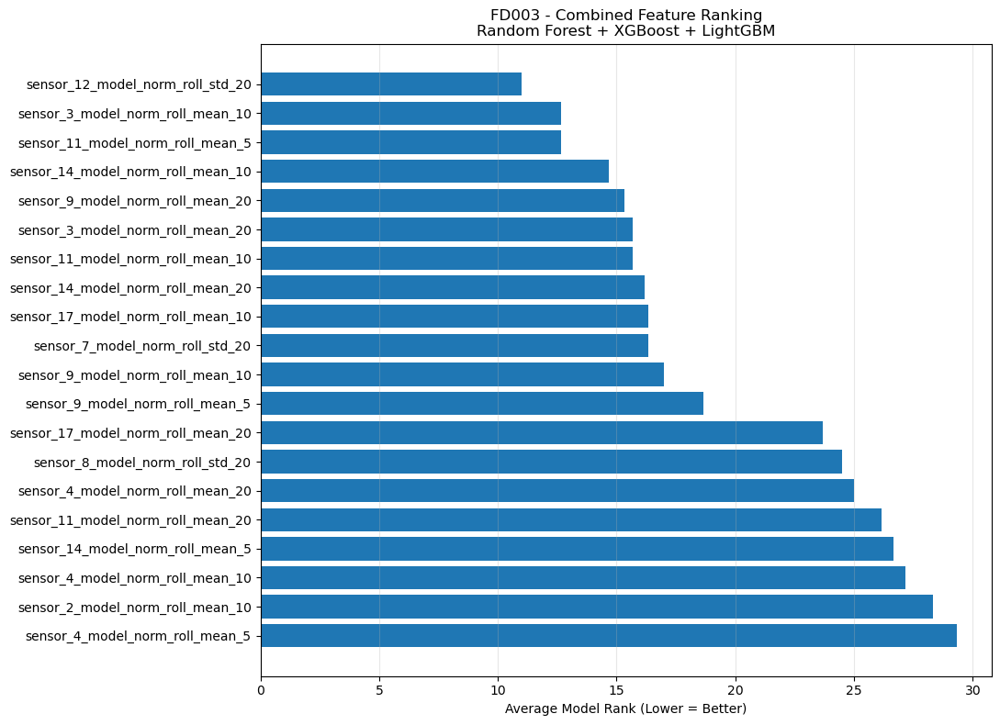

In [251]:
# ============================================================
# TOP 20 CONSISTENT ENGINEERED FEATURES - FD003
# ============================================================

top20_fd003_combined = (
    combined_importance_fd003.head(20).copy()
)

top20_fd003_combined = (
    top20_fd003_combined
    .sort_values(
        "Average_Model_Rank",
        ascending=False
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    top20_fd003_combined["Feature"],
    top20_fd003_combined["Average_Model_Rank"]
)

plt.xlabel("Average Model Rank (Lower = Better)")

plt.title(
    "FD003 - Combined Feature Ranking\n"
    "Random Forest + XGBoost + LightGBM"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [252]:
# ============================================================
# MAP ENGINEERED FEATURE BACK TO ORIGINAL SENSOR
# ============================================================

def get_original_sensor(feature_name):
    """
    Extract the original sensor name from an engineered feature.

    Example:
    sensor_11_model_norm_roll_mean_10
    -> sensor_11
    """

    # Check all 16 candidate sensors
    for sensor in candidate_sensor_cols:

        # Engineered sensor feature
        if feature_name.startswith(sensor + "_"):
            return sensor

        # Raw sensor feature, if ever present
        if feature_name == sensor:
            return sensor

    # Operating-condition features etc.
    return "Other"

In [253]:
# ============================================================
# MAP FD002 + FD003 FEATURES TO ORIGINAL SENSORS
# ============================================================

combined_importance_fd002["Original_Sensor"] = (
    combined_importance_fd002["Feature"]
    .apply(get_original_sensor)
)

combined_importance_fd003["Original_Sensor"] = (
    combined_importance_fd003["Feature"]
    .apply(get_original_sensor)
)

display(
    combined_importance_fd002[
        ["Feature", "Original_Sensor"]
    ].head(15)
)

,Feature,Original_Sensor
0,sensor_4_model_norm_roll_mean_10,sensor_4
1,sensor_11_model_norm_roll_mean_10,sensor_11
2,sensor_11_model_norm_roll_mean_5,sensor_11
3,sensor_4_model_norm_roll_mean_20,sensor_4
4,sensor_11_model_norm_roll_mean_20,sensor_11
5,sensor_15_model_norm_roll_mean_10,sensor_15
6,sensor_9_model_norm_roll_mean_20,sensor_9
7,sensor_2_model_norm_roll_mean_20,sensor_2
8,sensor_17_model_norm_roll_mean_10,sensor_17
9,sensor_2_model_norm_roll_mean_10,sensor_2


In [254]:
# ============================================================
# NORMALIZE FEATURE IMPORTANCE WITHIN EACH MODEL - FD002
# ============================================================
# Purpose:
# RF, XGBoost and LightGBM feature importance scales can differ.
# We normalize each model's importance so its total becomes 1.
# ============================================================

combined_importance_fd002["RF_Importance_Norm"] = (
    combined_importance_fd002["RF_Importance"]
    / combined_importance_fd002["RF_Importance"].sum()
)

combined_importance_fd002["XGB_Importance_Norm"] = (
    combined_importance_fd002["XGB_Importance"]
    / combined_importance_fd002["XGB_Importance"].sum()
)

combined_importance_fd002["LGBM_Importance_Norm"] = (
    combined_importance_fd002["LGBM_Importance"]
    / combined_importance_fd002["LGBM_Importance"].sum()
)


# ============================================================
# AGGREGATE ENGINEERED FEATURES BACK TO ORIGINAL SENSOR - FD002
# ============================================================
# Example:
# sensor_11 current
# sensor_11 lag
# sensor_11 rolling mean
# sensor_11 rolling std
#
# All belong to the same original sensor_11.
# We SUM their normalized importance to get sensor-level evidence.
# ============================================================

fd002_sensor_importance = (
    combined_importance_fd002[
        combined_importance_fd002["Original_Sensor"] != "Other"
    ]
    .groupby("Original_Sensor")[
        [
            "RF_Importance_Norm",
            "XGB_Importance_Norm",
            "LGBM_Importance_Norm"
        ]
    ]
    .sum()
)

# Average importance across the three traditional models
fd002_sensor_importance["Average_Model_Importance"] = (
    fd002_sensor_importance[
        [
            "RF_Importance_Norm",
            "XGB_Importance_Norm",
            "LGBM_Importance_Norm"
        ]
    ].mean(axis=1)
)

# Rank only the 16 original sensors
# Rank 1 = strongest
fd002_sensor_importance["FD002_Model_Rank"] = (
    fd002_sensor_importance["Average_Model_Importance"]
    .rank(
        ascending=False,
        method="average"
    )
)

fd002_sensor_importance = (
    fd002_sensor_importance
    .sort_values("FD002_Model_Rank")
)

display(fd002_sensor_importance)

,RF_Importance_Norm,XGB_Importance_Norm,LGBM_Importance_Norm,Average_Model_Importance,FD002_Model_Rank
Original_Sensor,,,,,
sensor_11,0.193030,0.483180,0.081267,0.252492,1.0
sensor_4,0.152936,0.163407,0.075733,0.130692,2.0
sensor_15,0.100869,0.040556,0.067200,0.069542,3.0
sensor_17,0.097500,0.036309,0.053267,0.062359,4.0
sensor_2,0.090193,0.027213,0.057733,0.058380,5.0
sensor_13,0.033707,0.063978,0.066400,0.054695,6.0
sensor_3,0.073645,0.024289,0.063067,0.053667,7.0
sensor_9,0.030726,0.030409,0.075800,0.045645,8.0
sensor_14,0.024101,0.019155,0.079067,0.040774,9.0


In [255]:
# ============================================================
# NORMALIZE FEATURE IMPORTANCE WITHIN EACH MODEL - FD003
# ============================================================

combined_importance_fd003["RF_Importance_Norm"] = (
    combined_importance_fd003["RF_Importance"]
    / combined_importance_fd003["RF_Importance"].sum()
)

combined_importance_fd003["XGB_Importance_Norm"] = (
    combined_importance_fd003["XGB_Importance"]
    / combined_importance_fd003["XGB_Importance"].sum()
)

combined_importance_fd003["LGBM_Importance_Norm"] = (
    combined_importance_fd003["LGBM_Importance"]
    / combined_importance_fd003["LGBM_Importance"].sum()
)


# ============================================================
# AGGREGATE ENGINEERED FEATURES BACK TO ORIGINAL SENSOR - FD003
# ============================================================

fd003_sensor_importance = (
    combined_importance_fd003[
        combined_importance_fd003["Original_Sensor"] != "Other"
    ]
    .groupby("Original_Sensor")[
        [
            "RF_Importance_Norm",
            "XGB_Importance_Norm",
            "LGBM_Importance_Norm"
        ]
    ]
    .sum()
)

# Average importance across RF, XGBoost and LightGBM
fd003_sensor_importance["Average_Model_Importance"] = (
    fd003_sensor_importance[
        [
            "RF_Importance_Norm",
            "XGB_Importance_Norm",
            "LGBM_Importance_Norm"
        ]
    ].mean(axis=1)
)

# Rank only the 16 original sensors
fd003_sensor_importance["FD003_Model_Rank"] = (
    fd003_sensor_importance["Average_Model_Importance"]
    .rank(
        ascending=False,
        method="average"
    )
)

fd003_sensor_importance = (
    fd003_sensor_importance
    .sort_values("FD003_Model_Rank")
)

display(fd003_sensor_importance)

,RF_Importance_Norm,XGB_Importance_Norm,LGBM_Importance_Norm,Average_Model_Importance,FD003_Model_Rank
Original_Sensor,,,,,
sensor_11,0.198525,0.263274,0.070267,0.177355,1.0
sensor_17,0.159618,0.258764,0.052600,0.156994,2.0
sensor_3,0.144986,0.217754,0.063667,0.142135,3.0
sensor_9,0.079664,0.100324,0.083800,0.087929,4.0
sensor_14,0.060444,0.024880,0.093867,0.059730,5.0
sensor_4,0.091493,0.016925,0.066467,0.058295,6.0
sensor_8,0.056868,0.010967,0.071067,0.046301,7.0
sensor_12,0.029918,0.023357,0.074400,0.042559,8.0
sensor_2,0.051333,0.011058,0.059867,0.040753,9.0


In [256]:
# ============================================================
# PREPARE PREVIOUS STATISTICAL SENSOR RANKING
# ============================================================

statistical_sensor_rank = (
    preliminary_sensor_ranking[
        "Preliminary_Average_Rank"
    ].copy()
)

# Convert:
# sensor_11_norm -> sensor_11
statistical_sensor_rank.index = (
    statistical_sensor_rank.index
    .str.replace("_norm", "", regex=False)
)

display(
    statistical_sensor_rank.to_frame(
        name="Statistical_Rank"
    )
)

,Statistical_Rank
sensor_11,1.00
sensor_4,2.00
sensor_17,3.00
sensor_3,4.00
sensor_2,5.00
sensor_13,6.00
sensor_8,7.00
sensor_9,8.00
sensor_14,9.75
sensor_12,10.25


In [257]:
# ============================================================
# COMBINE FD002 + FD003 SENSOR-LEVEL MODEL RANKINGS
# ============================================================
# Now all model ranks are on the same 1-16 sensor scale.
# ============================================================

sensor_model_evidence = pd.DataFrame({
    "FD002_Model_Rank":
        fd002_sensor_importance["FD002_Model_Rank"],

    "FD003_Model_Rank":
        fd003_sensor_importance["FD003_Model_Rank"]
})

# Average model ranking across both datasets
sensor_model_evidence["Average_Model_Rank"] = (
    sensor_model_evidence["FD002_Model_Rank"]
    +
    sensor_model_evidence["FD003_Model_Rank"]
) / 2


# ============================================================
# FINAL STATISTICAL + MODEL SENSOR EVIDENCE
# ============================================================
# Statistical_Rank: also approximately 1-16
# Average_Model_Rank: exactly based on the 16 original sensors
#
# Equal weighting:
# 50% statistical evidence
# 50% traditional ML evidence
# ============================================================

final_sensor_evidence = pd.DataFrame({
    "Statistical_Rank":
        statistical_sensor_rank,

    "FD002_Model_Rank":
        sensor_model_evidence["FD002_Model_Rank"],

    "FD003_Model_Rank":
        sensor_model_evidence["FD003_Model_Rank"],

    "Average_Model_Rank":
        sensor_model_evidence["Average_Model_Rank"]
})

final_sensor_evidence["Combined_Evidence_Rank"] = (
    final_sensor_evidence["Statistical_Rank"]
    +
    final_sensor_evidence["Average_Model_Rank"]
) / 2

# Lower combined rank = stronger sensor
final_sensor_evidence = (
    final_sensor_evidence
    .sort_values("Combined_Evidence_Rank")
)

display(final_sensor_evidence)

,Statistical_Rank,FD002_Model_Rank,FD003_Model_Rank,Average_Model_Rank,Combined_Evidence_Rank
sensor_11,1.00,1.0,1.0,1.0,1.000
sensor_17,3.00,4.0,2.0,3.0,3.000
sensor_4,2.00,2.0,6.0,4.0,3.000
sensor_3,4.00,7.0,3.0,5.0,4.500
sensor_2,5.00,5.0,9.0,7.0,6.000
sensor_9,8.00,8.0,4.0,6.0,7.000
sensor_13,6.00,6.0,11.0,8.5,7.250
sensor_8,7.00,10.0,7.0,8.5,7.750
sensor_14,9.75,9.0,5.0,7.0,8.375
sensor_15,10.50,3.0,12.0,7.5,9.000


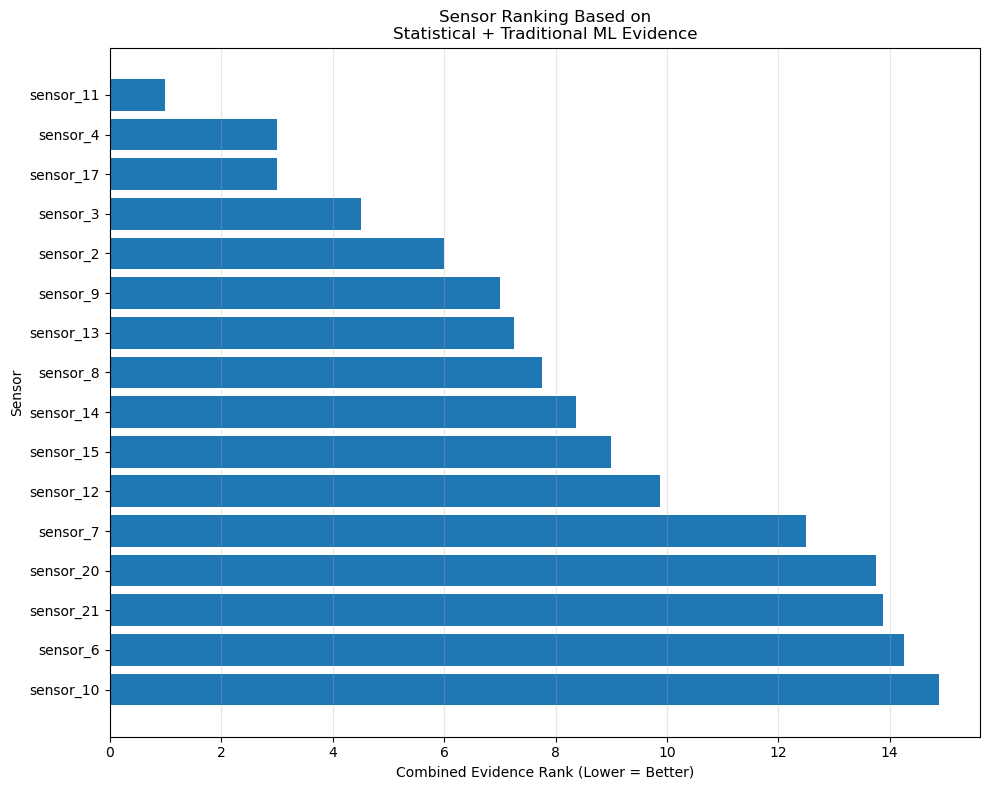

In [258]:
# ============================================================
# FINAL CORRECTED SENSOR EVIDENCE RANKING GRAPH
# ============================================================

sensor_ranking_plot = (
    final_sensor_evidence[
        "Combined_Evidence_Rank"
    ]
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 8))

plt.barh(
    sensor_ranking_plot.index,
    sensor_ranking_plot.values
)

plt.xlabel(
    "Combined Evidence Rank (Lower = Better)"
)

plt.ylabel("Sensor")

plt.title(
    "Sensor Ranking Based on\n"
    "Statistical + Traditional ML Evidence"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [259]:
# ============================================================
# COMMON MODEL EVALUATION FUNCTION
# ============================================================
# Purpose:
# Train a model, predict on validation data,
# and return MAE, RMSE, R2, training time,
# and inference time.
# ============================================================

def evaluate_regression_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val
):
    """
    Train and evaluate a regression model
    using the same validation protocol.
    """

    # -------------------------
    # Training
    # -------------------------
    train_start = time.time()

    model.fit(
        X_train,
        y_train
    )

    training_time = (
        time.time() - train_start
    )

    # -------------------------
    # Prediction
    # -------------------------
    pred_start = time.time()

    predictions = model.predict(
        X_val
    )

    inference_time = (
        time.time() - pred_start
    )

    # -------------------------
    # Metrics
    # -------------------------
    mae = mean_absolute_error(
        y_val,
        predictions
    )

    mse = mean_squared_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_val,
        predictions
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training_Time": training_time,
        "Inference_Time": inference_time
    }

In [260]:
# ============================================================
# XGBOOST TUNING CANDIDATES
# ============================================================
# These are controlled candidate configurations.
# We avoid a huge brute-force grid to keep computation practical.
# ============================================================

xgb_param_candidates = [
    {
        "n_estimators": 500,
        "learning_rate": 0.05,
        "max_depth": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 1
    },

    {
        "n_estimators": 700,
        "learning_rate": 0.03,
        "max_depth": 6,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "min_child_weight": 1
    },

    {
        "n_estimators": 600,
        "learning_rate": 0.04,
        "max_depth": 4,
        "subsample": 0.9,
        "colsample_bytree": 0.8,
        "min_child_weight": 3
    },

    {
        "n_estimators": 800,
        "learning_rate": 0.025,
        "max_depth": 5,
        "subsample": 0.85,
        "colsample_bytree": 0.9,
        "min_child_weight": 2
    }
]

In [261]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH - FD002
# ============================================================

xgb_tuning_results_fd002 = []

for i, params in enumerate(
    xgb_param_candidates,
    start=1
):

    print(
        f"Testing XGBoost configuration {i}"
    )

    # Create model using current parameter set
    model = XGBRegressor(
        **params,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    # Evaluate using SAME engine-wise validation set
    result = evaluate_regression_model(
        model,
        X_train_fd002,
        y_train_fd002,
        X_val_fd002,
        y_val_fd002
    )

    # Store parameters and metrics together
    result["Config"] = i
    result["Parameters"] = params

    xgb_tuning_results_fd002.append(
        result
    )

Testing XGBoost configuration 1
Testing XGBoost configuration 2
Testing XGBoost configuration 3
Testing XGBoost configuration 4


In [262]:
# ============================================================
# XGBOOST FD002 TUNING RESULTS TABLE
# ============================================================

xgb_tuning_df_fd002 = pd.DataFrame(
    xgb_tuning_results_fd002
)

# Sort by lowest RMSE
xgb_tuning_df_fd002 = (
    xgb_tuning_df_fd002
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(
    xgb_tuning_df_fd002[
        [
            "Config",
            "MAE",
            "RMSE",
            "R2",
            "Training_Time",
            "Inference_Time",
            "Parameters"
        ]
    ]
)

,Config,MAE,RMSE,R2,Training_Time,Inference_Time,Parameters
0,2,12.826661,17.983665,0.815086,47.306571,0.109625,"{'n_estimators': 700, 'learning_rate': 0.03, '..."
1,4,12.864258,18.002990,0.814688,39.950820,0.126936,"{'n_estimators': 800, 'learning_rate': 0.025, ..."
2,1,12.816940,18.004971,0.814647,23.792966,0.099450,"{'n_estimators': 500, 'learning_rate': 0.05, '..."
3,3,12.956415,18.021969,0.814297,19.398066,0.077025,"{'n_estimators': 600, 'learning_rate': 0.04, '..."


In [263]:
# ============================================================
# SELECT BEST XGBOOST CONFIGURATION - FD002
# ============================================================

best_xgb_params_fd002 = (
    xgb_tuning_df_fd002
    .iloc[0]["Parameters"]
)

print(
    "Best XGBoost Parameters for FD002:"
)

print(best_xgb_params_fd002)

Best XGBoost Parameters for FD002:
{'n_estimators': 700, 'learning_rate': 0.03, 'max_depth': 6, 'subsample': 0.85, 'colsample_bytree': 0.85, 'min_child_weight': 1}


In [264]:
# ============================================================
# TRAIN FINAL TUNED XGBOOST - FD002
# ============================================================

xgb_fd002_tuned = XGBRegressor(
    **best_xgb_params_fd002,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_fd002_tuned.fit(
    X_train_fd002,
    y_train_fd002
)

y_pred_fd002_xgb_tuned = (
    xgb_fd002_tuned.predict(
        X_val_fd002
    )
)

In [265]:
# ============================================================
# TUNED XGBOOST PERFORMANCE - FD002
# ============================================================

fd002_xgb_tuned_mae = (
    mean_absolute_error(
        y_val_fd002,
        y_pred_fd002_xgb_tuned
    )
)

fd002_xgb_tuned_rmse = np.sqrt(
    mean_squared_error(
        y_val_fd002,
        y_pred_fd002_xgb_tuned
    )
)

fd002_xgb_tuned_r2 = (
    r2_score(
        y_val_fd002,
        y_pred_fd002_xgb_tuned
    )
)

print("FD002 Tuned XGBoost")

print(
    f"MAE  : {fd002_xgb_tuned_mae:.4f}"
)

print(
    f"RMSE : {fd002_xgb_tuned_rmse:.4f}"
)

print(
    f"R²   : {fd002_xgb_tuned_r2:.4f}"
)

FD002 Tuned XGBoost
MAE  : 12.8267
RMSE : 17.9837
R²   : 0.8151


In [266]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH - FD003
# ============================================================

xgb_tuning_results_fd003 = []

for i, params in enumerate(
    xgb_param_candidates,
    start=1
):

    print(
        f"Testing FD003 XGBoost configuration {i}"
    )

    model = XGBRegressor(
        **params,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    result = evaluate_regression_model(
        model,
        X_train_fd003,
        y_train_fd003,
        X_val_fd003,
        y_val_fd003
    )

    result["Config"] = i
    result["Parameters"] = params

    xgb_tuning_results_fd003.append(
        result
    )

Testing FD003 XGBoost configuration 1
Testing FD003 XGBoost configuration 2
Testing FD003 XGBoost configuration 3
Testing FD003 XGBoost configuration 4


In [267]:
# ============================================================
# FD003 XGBOOST TUNING RESULTS
# ============================================================

xgb_tuning_df_fd003 = pd.DataFrame(
    xgb_tuning_results_fd003
)

xgb_tuning_df_fd003 = (
    xgb_tuning_df_fd003
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(
    xgb_tuning_df_fd003[
        [
            "Config",
            "MAE",
            "RMSE",
            "R2",
            "Training_Time",
            "Inference_Time",
            "Parameters"
        ]
    ]
)

,Config,MAE,RMSE,R2,Training_Time,Inference_Time,Parameters
0,4,9.561207,14.320447,0.878758,21.290271,0.051486,"{'n_estimators': 800, 'learning_rate': 0.025, ..."
1,1,9.614928,14.406612,0.877294,13.190776,0.048751,"{'n_estimators': 500, 'learning_rate': 0.05, '..."
2,3,9.756622,14.471878,0.876180,11.947965,0.041955,"{'n_estimators': 600, 'learning_rate': 0.04, '..."
3,2,9.642478,14.495286,0.875779,29.206025,0.059921,"{'n_estimators': 700, 'learning_rate': 0.03, '..."


In [268]:
# ============================================================
# RANDOM FOREST TUNING CANDIDATES
# ============================================================

rf_param_candidates = [
    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "n_estimators": 500,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "n_estimators": 400,
        "max_depth": 25,
        "min_samples_leaf": 1,
        "max_features": 0.6
    },

    {
        "n_estimators": 500,
        "max_depth": 18,
        "min_samples_leaf": 3,
        "max_features": 0.8
    }
]

In [270]:
# ============================================================
# LIGHTER RANDOM FOREST TUNING CANDIDATES
# ============================================================
# FD002 is relatively large and contains many engineered
# features, so we use computationally practical configurations.
# ============================================================

rf_param_candidates = [
    {
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "n_estimators": 250,
        "max_depth": 25,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 1,
        "max_features": 0.5
    },

    {
        "n_estimators": 250,
        "max_depth": 18,
        "min_samples_leaf": 3,
        "max_features": 0.6
    }
]

In [272]:
# ============================================================
# FAST RANDOM FOREST TUNING - FD002
# ============================================================
# Purpose:
# Test only a few lightweight configurations.
# This keeps tuning computationally practical while still
# checking whether RF can improve over the baseline.
# ============================================================

rf_fast_candidates = [
    {
        "n_estimators": 100,
        "max_depth": 18,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "n_estimators": 150,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "max_features": "sqrt"
    },

    {
        "n_estimators": 120,
        "max_depth": 18,
        "min_samples_leaf": 3,
        "max_features": 0.5
    }
]


rf_tuning_results_fd002 = []

for i, params in enumerate(rf_fast_candidates, start=1):

    print(f"\nStarting RF Configuration {i}/3")
    print(params)

    # Create model using current candidate parameters
    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    # Evaluate on the SAME leakage-free validation set
    result = evaluate_regression_model(
        model,
        X_train_fd002,
        y_train_fd002,
        X_val_fd002,
        y_val_fd002
    )

    # Store configuration details
    result["Config"] = i
    result["Parameters"] = params

    rf_tuning_results_fd002.append(result)

    # Immediately show result after each model finishes
    print(
        f"Completed Config {i} | "
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"R²: {result['R2']:.4f} | "
        f"Training Time: {result['Training_Time']:.2f}s"
    )


# Convert results into comparison table
rf_tuning_df_fd002 = pd.DataFrame(
    rf_tuning_results_fd002
).sort_values(
    "RMSE"
).reset_index(drop=True)

display(rf_tuning_df_fd002)


Starting RF Configuration 1/3
{'n_estimators': 100, 'max_depth': 18, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Completed Config 1 | MAE: 13.5218 | RMSE: 18.6598 | R²: 0.8009 | Training Time: 33.27s

Starting RF Configuration 2/3
{'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Completed Config 2 | MAE: 13.5201 | RMSE: 18.6252 | R²: 0.8017 | Training Time: 50.44s

Starting RF Configuration 3/3
{'n_estimators': 120, 'max_depth': 18, 'min_samples_leaf': 3, 'max_features': 0.5}
Completed Config 3 | MAE: 13.4052 | RMSE: 18.6920 | R²: 0.8002 | Training Time: 241.57s


,MAE,RMSE,R2,Training_Time,Inference_Time,Config,Parameters
0,13.520114,18.625200,0.801657,50.443816,0.205675,2,"{'n_estimators': 150, 'max_depth': 20, 'min_sa..."
1,13.521805,18.659809,0.800919,33.273095,0.154463,1,"{'n_estimators': 100, 'max_depth': 18, 'min_sa..."
2,13.405155,18.692014,0.800232,241.569462,0.137154,3,"{'n_estimators': 120, 'max_depth': 18, 'min_sa..."


In [273]:
# ============================================================
# FAST RANDOM FOREST TUNING - FD003
# ============================================================
# Purpose:
# Test the same lightweight RF configurations on FD003.
#
# IMPORTANT:
# We use the SAME leakage-free validation protocol.
# The goal is to check whether RF can improve over the
# original FD003 baseline RMSE = 14.5246.
# ============================================================

rf_tuning_results_fd003 = []

for i, params in enumerate(rf_fast_candidates, start=1):

    print(f"\nStarting FD003 RF Configuration {i}/3")
    print(params)

    # Create Random Forest with current parameter configuration
    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    # Train and evaluate using the already-created
    # engine-wise train/validation split
    result = evaluate_regression_model(
        model,
        X_train_fd003,
        y_train_fd003,
        X_val_fd003,
        y_val_fd003
    )

    # Save configuration information
    result["Config"] = i
    result["Parameters"] = params

    rf_tuning_results_fd003.append(result)

    # Immediately show performance after every configuration
    print(
        f"Completed Config {i} | "
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"R²: {result['R2']:.4f} | "
        f"Training Time: {result['Training_Time']:.2f}s"
    )


# Convert tuning results into a DataFrame
rf_tuning_df_fd003 = pd.DataFrame(
    rf_tuning_results_fd003
)

# Lowest RMSE should appear first
rf_tuning_df_fd003 = (
    rf_tuning_df_fd003
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(rf_tuning_df_fd003)


Starting FD003 RF Configuration 1/3
{'n_estimators': 100, 'max_depth': 18, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Completed Config 1 | MAE: 10.0272 | RMSE: 14.4949 | R²: 0.8758 | Training Time: 12.50s

Starting FD003 RF Configuration 2/3
{'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Completed Config 2 | MAE: 9.9470 | RMSE: 14.4510 | R²: 0.8765 | Training Time: 18.46s

Starting FD003 RF Configuration 3/3
{'n_estimators': 120, 'max_depth': 18, 'min_samples_leaf': 3, 'max_features': 0.5}
Completed Config 3 | MAE: 9.8603 | RMSE: 14.6823 | R²: 0.8726 | Training Time: 85.42s


,MAE,RMSE,R2,Training_Time,Inference_Time,Config,Parameters
0,9.947030,14.450970,0.876538,18.464025,0.131530,2,"{'n_estimators': 150, 'max_depth': 20, 'min_sa..."
1,10.027211,14.494883,0.875786,12.498808,0.067856,1,"{'n_estimators': 100, 'max_depth': 18, 'min_sa..."
2,9.860349,14.682350,0.872552,85.418745,0.113689,3,"{'n_estimators': 120, 'max_depth': 18, 'min_sa..."


In [274]:
# ============================================================
# CHECK WHETHER FD002 RF TUNING IMPROVED THE BASELINE
# ============================================================

fd002_rf_baseline_rmse = 18.596628

fd002_rf_best_tuned_rmse = (
    rf_tuning_df_fd002.iloc[0]["RMSE"]
)

print(
    "FD002 Baseline RF RMSE:",
    fd002_rf_baseline_rmse
)

print(
    "FD002 Best Tuned RF RMSE:",
    fd002_rf_best_tuned_rmse
)

if fd002_rf_best_tuned_rmse < fd002_rf_baseline_rmse:
    print("Use tuned RF for FD002.")
else:
    print("Keep baseline RF for FD002.")

FD002 Baseline RF RMSE: 18.596628
FD002 Best Tuned RF RMSE: 18.625200392568868
Keep baseline RF for FD002.


In [275]:
# ============================================================
# CHECK WHETHER FD003 RF TUNING IMPROVED THE BASELINE
# ============================================================

fd003_rf_baseline_rmse = 14.524648

fd003_rf_best_tuned_rmse = (
    rf_tuning_df_fd003.iloc[0]["RMSE"]
)

print(
    "FD003 Baseline RF RMSE:",
    fd003_rf_baseline_rmse
)

print(
    "FD003 Best Tuned RF RMSE:",
    fd003_rf_best_tuned_rmse
)

if fd003_rf_best_tuned_rmse < fd003_rf_baseline_rmse:
    print("Use tuned RF for FD003.")
else:
    print("Keep baseline RF for FD003.")

FD003 Baseline RF RMSE: 14.524648
FD003 Best Tuned RF RMSE: 14.4509703881132
Use tuned RF for FD003.


In [276]:
# ============================================================
# LIGHTGBM TUNING CANDIDATES
# ============================================================
# These configurations vary:
#
# - number of boosting trees
# - learning rate
# - number of leaves
# - tree depth
# - row sampling
# - feature sampling
#
# Goal:
# Improve generalization without performing an unnecessarily
# huge brute-force search.
# ============================================================

lgbm_param_candidates = [
    {
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": -1,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },

    {
        "n_estimators": 700,
        "learning_rate": 0.03,
        "num_leaves": 31,
        "max_depth": 12,
        "subsample": 0.85,
        "colsample_bytree": 0.85
    },

    {
        "n_estimators": 600,
        "learning_rate": 0.04,
        "num_leaves": 20,
        "max_depth": 10,
        "subsample": 0.9,
        "colsample_bytree": 0.8
    },

    {
        "n_estimators": 800,
        "learning_rate": 0.025,
        "num_leaves": 40,
        "max_depth": 15,
        "subsample": 0.85,
        "colsample_bytree": 0.9
    }
]

In [277]:
# ============================================================
# LIGHTGBM HYPERPARAMETER TUNING - FD002
# ============================================================

lgbm_tuning_results_fd002 = []

for i, params in enumerate(
    lgbm_param_candidates,
    start=1
):

    print(
        f"\nStarting FD002 LightGBM Configuration {i}/4"
    )

    print(params)

    # Build LightGBM model using current parameter set
    model = LGBMRegressor(
        **params,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    # Evaluate using the SAME FD002 validation engines
    result = evaluate_regression_model(
        model,
        X_train_fd002,
        y_train_fd002,
        X_val_fd002,
        y_val_fd002
    )

    result["Config"] = i
    result["Parameters"] = params

    lgbm_tuning_results_fd002.append(
        result
    )

    # Show result immediately
    print(
        f"Completed Config {i} | "
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"R²: {result['R2']:.4f} | "
        f"Training Time: {result['Training_Time']:.2f}s"
    )


# Convert results to DataFrame
lgbm_tuning_df_fd002 = pd.DataFrame(
    lgbm_tuning_results_fd002
)

# Best RMSE first
lgbm_tuning_df_fd002 = (
    lgbm_tuning_df_fd002
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(lgbm_tuning_df_fd002)


Starting FD002 LightGBM Configuration 1/4
{'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'subsample': 0.8, 'colsample_bytree': 0.8}
Completed Config 1 | MAE: 12.8498 | RMSE: 18.0870 | R²: 0.8130 | Training Time: 15.30s

Starting FD002 LightGBM Configuration 2/4
{'n_estimators': 700, 'learning_rate': 0.03, 'num_leaves': 31, 'max_depth': 12, 'subsample': 0.85, 'colsample_bytree': 0.85}
Completed Config 2 | MAE: 12.8237 | RMSE: 18.0478 | R²: 0.8138 | Training Time: 22.16s

Starting FD002 LightGBM Configuration 3/4
{'n_estimators': 600, 'learning_rate': 0.04, 'num_leaves': 20, 'max_depth': 10, 'subsample': 0.9, 'colsample_bytree': 0.8}
Completed Config 3 | MAE: 12.9384 | RMSE: 18.1234 | R²: 0.8122 | Training Time: 12.17s

Starting FD002 LightGBM Configuration 4/4
{'n_estimators': 800, 'learning_rate': 0.025, 'num_leaves': 40, 'max_depth': 15, 'subsample': 0.85, 'colsample_bytree': 0.9}
Completed Config 4 | MAE: 12.8209 | RMSE: 18.0560 | R²: 0.8136 | Traini

,MAE,RMSE,R2,Training_Time,Inference_Time,Config,Parameters
0,12.823693,18.047752,0.813765,22.155776,0.292710,2,"{'n_estimators': 700, 'learning_rate': 0.03, '..."
1,12.820884,18.055955,0.813596,23.227916,0.357534,4,"{'n_estimators': 800, 'learning_rate': 0.025, ..."
2,12.849766,18.086984,0.812955,15.298920,0.266420,1,"{'n_estimators': 500, 'learning_rate': 0.05, '..."
3,12.938414,18.123442,0.812200,12.172334,0.173493,3,"{'n_estimators': 600, 'learning_rate': 0.04, '..."


In [278]:
# ============================================================
# LIGHTGBM HYPERPARAMETER TUNING - FD003
# ============================================================

lgbm_tuning_results_fd003 = []

for i, params in enumerate(
    lgbm_param_candidates,
    start=1
):

    print(
        f"\nStarting FD003 LightGBM Configuration {i}/4"
    )

    print(params)

    # Create model for current configuration
    model = LGBMRegressor(
        **params,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    # Evaluate on unseen FD003 validation engines
    result = evaluate_regression_model(
        model,
        X_train_fd003,
        y_train_fd003,
        X_val_fd003,
        y_val_fd003
    )

    result["Config"] = i
    result["Parameters"] = params

    lgbm_tuning_results_fd003.append(
        result
    )

    print(
        f"Completed Config {i} | "
        f"MAE: {result['MAE']:.4f} | "
        f"RMSE: {result['RMSE']:.4f} | "
        f"R²: {result['R2']:.4f} | "
        f"Training Time: {result['Training_Time']:.2f}s"
    )


lgbm_tuning_df_fd003 = pd.DataFrame(
    lgbm_tuning_results_fd003
)

lgbm_tuning_df_fd003 = (
    lgbm_tuning_df_fd003
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(lgbm_tuning_df_fd003)


Starting FD003 LightGBM Configuration 1/4
{'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'subsample': 0.8, 'colsample_bytree': 0.8}
Completed Config 1 | MAE: 9.6838 | RMSE: 14.6197 | R²: 0.8736 | Training Time: 8.55s

Starting FD003 LightGBM Configuration 2/4
{'n_estimators': 700, 'learning_rate': 0.03, 'num_leaves': 31, 'max_depth': 12, 'subsample': 0.85, 'colsample_bytree': 0.85}
Completed Config 2 | MAE: 9.6958 | RMSE: 14.6358 | R²: 0.8734 | Training Time: 12.11s

Starting FD003 LightGBM Configuration 3/4
{'n_estimators': 600, 'learning_rate': 0.04, 'num_leaves': 20, 'max_depth': 10, 'subsample': 0.9, 'colsample_bytree': 0.8}
Completed Config 3 | MAE: 9.6298 | RMSE: 14.5837 | R²: 0.8743 | Training Time: 6.24s

Starting FD003 LightGBM Configuration 4/4
{'n_estimators': 800, 'learning_rate': 0.025, 'num_leaves': 40, 'max_depth': 15, 'subsample': 0.85, 'colsample_bytree': 0.9}
Completed Config 4 | MAE: 9.7060 | RMSE: 14.7399 | R²: 0.8716 | Training Tim

,MAE,RMSE,R2,Training_Time,Inference_Time,Config,Parameters
0,9.629798,14.583727,0.874259,6.237951,0.119279,3,"{'n_estimators': 600, 'learning_rate': 0.04, '..."
1,9.683799,14.619746,0.873637,8.550189,0.088151,1,"{'n_estimators': 500, 'learning_rate': 0.05, '..."
2,9.695821,14.635771,0.873360,12.106985,0.121848,2,"{'n_estimators': 700, 'learning_rate': 0.03, '..."
3,9.706022,14.739854,0.871552,15.031229,0.155469,4,"{'n_estimators': 800, 'learning_rate': 0.025, ..."


In [279]:
# ============================================================
# BEST LIGHTGBM PARAMETERS - FD002
# ============================================================

best_lgbm_params_fd002 = (
    lgbm_tuning_df_fd002
    .iloc[0]["Parameters"]
)

print(
    "Best LightGBM Parameters - FD002:"
)

print(best_lgbm_params_fd002)

Best LightGBM Parameters - FD002:
{'n_estimators': 700, 'learning_rate': 0.03, 'num_leaves': 31, 'max_depth': 12, 'subsample': 0.85, 'colsample_bytree': 0.85}


In [280]:
# ============================================================
# BEST LIGHTGBM PARAMETERS - FD003
# ============================================================

best_lgbm_params_fd003 = (
    lgbm_tuning_df_fd003
    .iloc[0]["Parameters"]
)

print(
    "Best LightGBM Parameters - FD003:"
)

print(best_lgbm_params_fd003)

Best LightGBM Parameters - FD003:
{'n_estimators': 600, 'learning_rate': 0.04, 'num_leaves': 20, 'max_depth': 10, 'subsample': 0.9, 'colsample_bytree': 0.8}


In [281]:
# ============================================================
# HYPERPARAMETER TUNING SUMMARY
# ============================================================
# Shows baseline vs best tuned RMSE for each model/dataset.
# ============================================================

tuning_summary = pd.DataFrame([
    {
        "Dataset": "FD002",
        "Model": "Random Forest",
        "Baseline_RMSE": 18.596628,
        "Best_Tuned_RMSE":
            rf_tuning_df_fd002.iloc[0]["RMSE"]
    },

    {
        "Dataset": "FD003",
        "Model": "Random Forest",
        "Baseline_RMSE": 14.524648,
        "Best_Tuned_RMSE":
            rf_tuning_df_fd003.iloc[0]["RMSE"]
    },

    {
        "Dataset": "FD002",
        "Model": "XGBoost",
        "Baseline_RMSE": 18.016542,
        "Best_Tuned_RMSE":
            xgb_tuning_df_fd002.iloc[0]["RMSE"]
    },

    {
        "Dataset": "FD003",
        "Model": "XGBoost",
        "Baseline_RMSE": 14.565006,
        "Best_Tuned_RMSE":
            xgb_tuning_df_fd003.iloc[0]["RMSE"]
    },

    {
        "Dataset": "FD002",
        "Model": "LightGBM",
        "Baseline_RMSE": 18.086984,
        "Best_Tuned_RMSE":
            lgbm_tuning_df_fd002.iloc[0]["RMSE"]
    },

    {
        "Dataset": "FD003",
        "Model": "LightGBM",
        "Baseline_RMSE": 14.619746,
        "Best_Tuned_RMSE":
            lgbm_tuning_df_fd003.iloc[0]["RMSE"]
    }
])


# Calculate improvement:
# Positive value = tuned model improved RMSE
tuning_summary["RMSE_Improvement"] = (
    tuning_summary["Baseline_RMSE"]
    -
    tuning_summary["Best_Tuned_RMSE"]
)

display(tuning_summary)

,Dataset,Model,Baseline_RMSE,Best_Tuned_RMSE,RMSE_Improvement
0,FD002,Random Forest,18.596628,18.625200,-0.028572
1,FD003,Random Forest,14.524648,14.450970,0.073678
2,FD002,XGBoost,18.016542,17.983665,0.032877
3,FD003,XGBoost,14.565006,14.320447,0.244559
4,FD002,LightGBM,18.086984,18.047752,0.039232
5,FD003,LightGBM,14.619746,14.583727,0.036019


In [282]:
# ============================================================
# CREATE CHECKPOINT DIRECTORY
# ============================================================
# Purpose:
# Save all important outputs from Notebook 1 so that future
# notebooks can continue without running the entire notebook.
# ============================================================

import os

CHECKPOINT_DIR = r"D:\IST\Aircraft_Engine_RUL\checkpoints"

# Create folder if it does not already exist
os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

print("Checkpoint directory ready:")
print(CHECKPOINT_DIR)

Checkpoint directory ready:
D:\IST\Aircraft_Engine_RUL\checkpoints


In [284]:
# ============================================================
# CREATE FINAL TUNED XGBOOST MODEL - FD003
# ============================================================

best_xgb_params_fd003 = (
    xgb_tuning_df_fd003
    .iloc[0]["Parameters"]
)

xgb_fd003_tuned = XGBRegressor(
    **best_xgb_params_fd003,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_fd003_tuned.fit(
    X_train_fd003,
    y_train_fd003
)

print("FD003 tuned XGBoost ready.")

FD003 tuned XGBoost ready.


In [285]:
# ============================================================
# CHECK IMPORTANT MODEL OBJECTS BEFORE SAVING
# ============================================================

print(
    "FD002 Tuned XGBoost exists:",
    "xgb_fd002_tuned" in globals()
)

print(
    "FD003 Tuned XGBoost exists:",
    "xgb_fd003_tuned" in globals()
)

FD002 Tuned XGBoost exists: True
FD003 Tuned XGBoost exists: True


In [286]:
# ============================================================
# PRE-CHECKPOINT VARIABLE VERIFICATION
# ============================================================
# Purpose:
# Check that every important object required for the
# checkpoint currently exists in Notebook 1 memory.
# ============================================================

required_objects = [

    # Train / validation data
    "X_train_fd002",
    "X_val_fd002",
    "y_train_fd002",
    "y_val_fd002",

    "X_train_fd003",
    "X_val_fd003",
    "y_train_fd003",
    "y_val_fd003",

    # Tuned models
    "xgb_fd002_tuned",
    "xgb_fd003_tuned",

    # Feature/sensor information
    "candidate_sensor_cols",
    "model_sensor_cols",
    "final_sensor_evidence",

    # Tuning results
    "xgb_tuning_df_fd002",
    "xgb_tuning_df_fd003",
    "rf_tuning_df_fd002",
    "rf_tuning_df_fd003",
    "lgbm_tuning_df_fd002",
    "lgbm_tuning_df_fd003",
    "tuning_summary"
]


# Check every variable
for obj in required_objects:

    if obj in globals():
        print(f"✅ {obj}")

    else:
        print(f"❌ MISSING: {obj}")

✅ X_train_fd002
✅ X_val_fd002
✅ y_train_fd002
✅ y_val_fd002
✅ X_train_fd003
✅ X_val_fd003
✅ y_train_fd003
✅ y_val_fd003
✅ xgb_fd002_tuned
✅ xgb_fd003_tuned
✅ candidate_sensor_cols
✅ model_sensor_cols
✅ final_sensor_evidence
✅ xgb_tuning_df_fd002
✅ xgb_tuning_df_fd003
✅ rf_tuning_df_fd002
✅ rf_tuning_df_fd003
✅ lgbm_tuning_df_fd002
✅ lgbm_tuning_df_fd003
✅ tuning_summary


In [287]:
# ============================================================
# SAVE NOTEBOOK 1 CHECKPOINT
# ============================================================
# Purpose:
# Save all important outputs from Notebook 1 so that
# Notebook 2 can continue directly without running
# preprocessing, feature engineering, baselines, and tuning again.
# ============================================================

import os
import joblib

# ------------------------------------------------------------
# CHECKPOINT DIRECTORY
# ------------------------------------------------------------

CHECKPOINT_DIR = r"D:\IST\Aircraft_Engine_RUL\checkpoints"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# BUILD CHECKPOINT DICTIONARY
# ------------------------------------------------------------

checkpoint = {

    # ========================================================
    # FINAL TRAIN / VALIDATION MATRICES
    # ========================================================

    "X_train_fd002": X_train_fd002,
    "X_val_fd002": X_val_fd002,
    "y_train_fd002": y_train_fd002,
    "y_val_fd002": y_val_fd002,

    "X_train_fd003": X_train_fd003,
    "X_val_fd003": X_val_fd003,
    "y_train_fd003": y_train_fd003,
    "y_val_fd003": y_val_fd003,


    # ========================================================
    # PREPROCESSED ENGINE DATA
    # Required later for sequence models such as BiLSTM
    # and CAUC-AeroRULNet
    # ========================================================

    "fd002_train_model": fd002_train_model,
    "fd002_val_model": fd002_val_model,

    "fd003_train_model": fd003_train_model,
    "fd003_val_model": fd003_val_model,


    # ========================================================
    # SENSOR / FEATURE INFORMATION
    # ========================================================

    "candidate_sensor_cols": candidate_sensor_cols,
    "model_sensor_cols": model_sensor_cols,

    "fd002_feature_cols": fd002_feature_cols,
    "fd003_feature_cols": fd003_feature_cols,

    "final_sensor_evidence": final_sensor_evidence,


    # ========================================================
    # FINAL TUNED XGBOOST MODELS
    # These will be used immediately in Notebook 2 for SHAP.
    # ========================================================

    "xgb_fd002_tuned": xgb_fd002_tuned,
    "xgb_fd003_tuned": xgb_fd003_tuned,


    # ========================================================
    # HYPERPARAMETER TUNING RESULTS
    # ========================================================

    "xgb_tuning_df_fd002": xgb_tuning_df_fd002,
    "xgb_tuning_df_fd003": xgb_tuning_df_fd003,

    "rf_tuning_df_fd002": rf_tuning_df_fd002,
    "rf_tuning_df_fd003": rf_tuning_df_fd003,

    "lgbm_tuning_df_fd002": lgbm_tuning_df_fd002,
    "lgbm_tuning_df_fd003": lgbm_tuning_df_fd003,

    "tuning_summary": tuning_summary,


    # ========================================================
    # PREPROCESSING OBJECTS
    # Required later for new/unseen user telemetry.
    # ========================================================

    "fd002_op_scaler_model": fd002_op_scaler_model,
    "fd002_kmeans_model": fd002_kmeans_model,

    "fd002_model_condition_means":
        fd002_model_condition_means,

    "fd002_model_safe_stds":
        fd002_model_safe_stds,

    "fd003_model_means":
        fd003_model_means,

    "fd003_model_safe_stds":
        fd003_model_safe_stds
}


# ------------------------------------------------------------
# FINAL CHECKPOINT FILE PATH
# ------------------------------------------------------------

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "phase_01_ml_checkpoint.joblib"
)


# ------------------------------------------------------------
# SAVE CHECKPOINT
# ------------------------------------------------------------

joblib.dump(
    checkpoint,
    CHECKPOINT_PATH,
    compress=3
)


print("✅ Checkpoint successfully saved.")
print("Path:")
print(CHECKPOINT_PATH)

✅ Checkpoint successfully saved.
Path:
D:\IST\Aircraft_Engine_RUL\checkpoints\phase_01_ml_checkpoint.joblib
